# Build annotated single cell RNA-seq references for Cervix

In [1]:
from pathlib import Path
import sys

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[3]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

In [ ]:
# Folder containing the GEO raw files
ref_folder_geo = get_full_path('eval', 'eval_datasets', 'scRNAseq_references', 'scRNAseq_references_before', 'cervix', 'cervix_geo')

# Folder for saving raw h5ad
ref_folder_raw_h5ad = get_full_path('eval', 'eval_datasets', 'scRNAseq_references', 'scRNAseq_references_before', 'cervix', 'cervix_raw_h5ad')
ref_folder_raw_h5ad.mkdir(parents=True, exist_ok=True)

# Folder for saving cell type annotation
ref_folder_annot = get_full_path('eval', 'eval_datasets', 'scRNAseq_references', 'scRNAseq_references_before', 'cervix', 'cervix_annots')
ref_folder_annot.mkdir(parents=True, exist_ok=True)

# Folder for final h5ad
ref_folder_final = get_full_path('eval', 'eval_datasets', 'scRNAseq_references', 'scRNAseq_references_before')

## Build adatas from GEO data

In [14]:
import numpy as np
import scanpy as sc

In [15]:
# Metadata inferred from GEO + filenames
sample_info = {
    "GSM6360680_N_HPV_NEG_1": {
        "gsm": "GSM6360680",
        "sample": "N_HPV_NEG_1",
        "group": "NO_HPV",
        "stage": "normal",
        "replicate": 1,
        "histology": "normal",
    },
    "GSM6360681_N_HPV_NEG_2": {
        "gsm": "GSM6360681",
        "sample": "N_HPV_NEG_2",
        "group": "NO_HPV",
        "stage": "normal",
        "replicate": 2,
        "histology": "normal",
    },
    "GSM6360682_N_1": {
        "gsm": "GSM6360682",
        "sample": "N_1",
        "group": "N_HPV",
        "stage": "hpv_positive_normal",
        "replicate": 1,
        "histology": "normal",
    },
    "GSM6360683_N_2": {
        "gsm": "GSM6360683",
        "sample": "N_2",
        "group": "N_HPV",
        "stage": "hpv_positive_normal",
        "replicate": 2,
        "histology": "normal",
    },
    "GSM6360684_HSIL_1": {
        "gsm": "GSM6360684",
        "sample": "HSIL_1",
        "group": "HSIL_HPV",
        "stage": "hsil",
        "replicate": 1,
        "histology": "hsil",
    },
    "GSM6360685_HSIL_2": {
        "gsm": "GSM6360685",
        "sample": "HSIL_2",
        "group": "HSIL_HPV",
        "stage": "hsil",
        "replicate": 2,
        "histology": "hsil",
    },
    "GSM6360686_SCC_4": {
        "gsm": "GSM6360686",
        "sample": "SCC_4",
        "group": "CA_HPV",
        "stage": "cancer",
        "replicate": 1,
        "histology": "squamous_cell_carcinoma",
    },
    "GSM6360687_SCC_5": {
        "gsm": "GSM6360687",
        "sample": "SCC_5",
        "group": "CA_HPV",
        "stage": "cancer",
        "replicate": 2,
        "histology": "squamous_cell_carcinoma",
    },
    "GSM6360688_ADC_6": {
        "gsm": "GSM6360688",
        "sample": "ADC_6",
        "group": "CA_HPV",
        "stage": "cancer",
        "replicate": 3,
        "histology": "adenocarcinoma",
    },
}


def find_prefixes(ref_folder_geo: Path):
    """Get unique sample prefixes from *.matrix.mtx.gz files."""
    matrix_files = sorted(ref_folder_geo.glob("*.matrix.mtx.gz"))
    prefixes = [f.name.replace(".matrix.mtx.gz", "") for f in matrix_files]
    # remove files that start with "._" (hidden files created by macOS)
    prefixes = [p for p in prefixes if not p.startswith("._")]
    return prefixes

prefixes = find_prefixes(ref_folder_geo)

print("Found prefixes:")
for p in prefixes:
    print("  ", p)

print("\nProcessing each sample...")
for prefix in prefixes:

    print(f"\n\n\n\nProcessing {prefix}...")
    sample_path_prefix = ref_folder_geo / prefix

    # Read as 10x mtx
    a = sc.read_10x_mtx(
        path=ref_folder_geo,
        prefix=f"{prefix}.",
        var_names="gene_symbols",
        make_unique=True,
    )

    # Make cell barcodes globally unique
    a.obs_names = [f"{prefix}_{bc}" for bc in a.obs_names]

    # Add metadata
    meta = sample_info[prefix]
    for k, v in meta.items():
        a.obs[k] = v

    # Extra useful metadata
    a.obs["dataset"] = "GSE208653"
    a.obs["tissue"] = "cervix"
    a.obs["species"] = "Homo sapiens"

    # Check if .X looks like counts
    X = a.X
    sample = X[:1000].toarray() if hasattr(X, "toarray") else X[:1000]
    is_integer_like = np.allclose(sample, np.round(sample))
    has_no_negatives = np.min(sample) >= 0
    if is_integer_like and has_no_negatives:
        print("ok")
    else:
        raise ValueError(f".X does not look like raw counts for {prefix}")
    
    # Check var, obs, adata
    print(f"\nadata.var is: {a.var}")
    print(f"\nadata.obs is: {a.obs}")
    print(f"\nadata is: {a}")

    # Save in raw h5ad folder
    a.write_h5ad(ref_folder_raw_h5ad / f"{prefix}.h5ad")

    print(f"\nSaved {prefix}.")

Found prefixes:
   GSM6360680_N_HPV_NEG_1
   GSM6360681_N_HPV_NEG_2
   GSM6360682_N_1
   GSM6360683_N_2
   GSM6360684_HSIL_1
   GSM6360685_HSIL_2
   GSM6360686_SCC_4
   GSM6360687_SCC_5
   GSM6360688_ADC_6

Processing each sample...




Processing GSM6360680_N_HPV_NEG_1...
Only considering the two last: ['.mtx', '.gz'].
Only considering the two last: ['.mtx', '.gz'].
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
ok

adata.var is:                    gene_ids    feature_types
OR4F5       ENSG00000186092  Gene Expression
OR4F29      ENSG00000284733  Gene Expression
OR4F16      ENSG00000284662  Gene Expression
SAMD11      ENSG00000187634  Gene Expression
NOC2L       ENSG00000188976  Gene Expression
...                     ...              ...
AC233755.2  ENSG00000277856  Gene Expression
AC233755.1  ENSG00000275063  Gene Expression
AC240274.1  ENSG00000271254  Gene Expression
AC213203.4  ENSG00000277475  Gene Expression
AC21

## Annotate cell types

In [3]:
# Setup ---

import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from scipy import sparse
from scipy.stats import median_abs_deviation
from IPython.display import display

# Scanpy / pandas display
sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=120, facecolor="white")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

# -------------------------------------------------------------------
# Helper functions
# -------------------------------------------------------------------

def check_integer_like_counts(adata, n_cells=1000, n_genes=1000):
    """
    Quick sanity check that X looks like raw UMI counts.
    """
    n_cells = min(n_cells, adata.n_obs)
    n_genes = min(n_genes, adata.n_vars)

    X = adata.X[:n_cells, :n_genes]
    X = X.toarray() if sparse.issparse(X) else np.asarray(X)

    integer_like = np.allclose(X, np.round(X))
    non_negative = np.min(X) >= 0
    return integer_like and non_negative


def add_standard_qc_metrics(adata):
    """
    Add mt/ribo/hb flags and common Scanpy QC metrics.
    """
    adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")
    adata.var["ribo"] = adata.var_names.str.upper().str.startswith(("RPS", "RPL"))
    # keep adult hemoglobins but exclude HBP pseudogenes-like matches
    adata.var["hb"] = adata.var_names.str.upper().str.contains(r"^HB(?!P)")

    sc.pp.calculate_qc_metrics(
        adata,
        qc_vars=["mt", "ribo", "hb"],
        inplace=True,
        log1p=True,
        percent_top=[20],
    )
    return adata


def mad_bounds(x, nmads=3, log1p=False):
    """
    Median +/- n*MAD bounds. Useful as sample-specific QC suggestions.
    """
    x = pd.Series(x).astype(float).to_numpy()

    if log1p:
        x_work = np.log1p(x)
    else:
        x_work = x

    med = np.nanmedian(x_work)
    mad = median_abs_deviation(x_work, scale="normal", nan_policy="omit")

    if np.isnan(mad) or mad == 0:
        lower = np.nanmin(x_work)
        upper = np.nanmax(x_work)
    else:
        lower = med - nmads * mad
        upper = med + nmads * mad

    if log1p:
        lower = np.expm1(lower)
        upper = np.expm1(upper)

    return float(lower), float(upper)


def suggest_qc_thresholds(adata, nmads=3):
    """
    Suggest per-sample QC cutoffs.
    Use these only as starting points; inspect plots before finalizing.
    """
    lo_counts, hi_counts = mad_bounds(adata.obs["total_counts"], nmads=nmads, log1p=True)
    lo_genes, hi_genes = mad_bounds(adata.obs["n_genes_by_counts"], nmads=nmads, log1p=True)
    _, hi_mt = mad_bounds(adata.obs["pct_counts_mt"], nmads=nmads, log1p=False)

    suggestions = {
        "min_counts": max(0, int(np.floor(lo_counts))),
        "max_counts": int(np.ceil(hi_counts)),
        "min_genes": max(100, int(np.floor(lo_genes))),
        "max_genes": int(np.ceil(hi_genes)),
        "max_pct_mt": round(max(5.0, hi_mt), 2),
    }
    return suggestions


def plot_qc(adata, sample_id):
    """
    Standard QC plots for one sample.
    """
    print(f"QC plots for {sample_id}")
    sc.pl.highest_expr_genes(adata, n_top=20)
    sc.pl.violin(
        adata,
        ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"],
        jitter=0.4,
        multi_panel=True,
    )
    sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")
    sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
    sc.pl.scatter(adata, x="total_counts", y="pct_counts_hb")


def filter_cells_with_qc_dict(adata, qc):
    """
    Apply user-selected QC filters.
    """
    keep = np.ones(adata.n_obs, dtype=bool)

    if qc.get("min_counts") is not None:
        keep &= adata.obs["total_counts"] >= qc["min_counts"]
    if qc.get("max_counts") is not None:
        keep &= adata.obs["total_counts"] <= qc["max_counts"]

    if qc.get("min_genes") is not None:
        keep &= adata.obs["n_genes_by_counts"] >= qc["min_genes"]
    if qc.get("max_genes") is not None:
        keep &= adata.obs["n_genes_by_counts"] <= qc["max_genes"]

    if qc.get("max_pct_mt") is not None:
        keep &= adata.obs["pct_counts_mt"] <= qc["max_pct_mt"]

    return adata[keep].copy()


def run_hvg(adata, n_top_genes=3000):
    """
    Run HVG selection, preferring Seurat v3 on raw counts.
    Falls back to Seurat flavor if scikit-misc is unavailable.
    """
    try:
        sc.pp.highly_variable_genes(
            adata,
            flavor="seurat_v3",
            n_top_genes=n_top_genes,
            layer="counts",
            subset=False,
            inplace=True,
        )
        hvg_flavor = "seurat_v3"
    except Exception as e:
        warnings.warn(
            f"seurat_v3 HVG selection failed ({type(e).__name__}: {e}). "
            "Falling back to flavor='seurat' on log1p data."
        )
        sc.pp.highly_variable_genes(
            adata,
            flavor="seurat",
            n_top_genes=n_top_genes,
            subset=False,
            inplace=True,
        )
        hvg_flavor = "seurat"

    print(f"HVG flavor used: {hvg_flavor}")
    print(f"Number of HVGs: {int(adata.var['highly_variable'].sum())}")
    return adata, hvg_flavor


def run_marker_analysis(
    adata,
    cluster_key,
    top_n=15,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
):
    """
    Run DE for one chosen clustering and return marker tables.
    """
    marker_key = f"rank_genes_groups__{cluster_key}"

    sc.tl.rank_genes_groups(
        adata,
        groupby=cluster_key,
        method="wilcoxon",
        tie_correct=True,
        pts=True,
        use_raw=True,
        key_added=marker_key,
    )

    markers_all = sc.get.rank_genes_groups_df(adata, group=None, key=marker_key).copy()

    # Keep only columns that are present in the installed Scanpy version
    keep_cols = [
        c for c in [
            "group", "names", "scores", "logfoldchanges", "pvals", "pvals_adj",
            "pct_nz_group", "pct_nz_reference"
        ] if c in markers_all.columns
    ]
    markers_all = markers_all[keep_cols].rename(
        columns={"group": "cluster", "names": "gene"}
    )

    # Filter markers to make manual annotation easier
    markers_filtered = markers_all.copy()
    if "pvals_adj" in markers_filtered.columns:
        markers_filtered = markers_filtered[markers_filtered["pvals_adj"] <= max_adj_p]
    if "logfoldchanges" in markers_filtered.columns:
        markers_filtered = markers_filtered[markers_filtered["logfoldchanges"] >= min_logfc]
    if "pct_nz_group" in markers_filtered.columns:
        markers_filtered = markers_filtered[markers_filtered["pct_nz_group"] >= min_pct_group]

    cluster_order = list(adata.obs[cluster_key].cat.categories)

    # Wide table: one column per cluster, one row per marker rank
    top_markers_wide = pd.DataFrame({
        cl: (
            markers_filtered.loc[markers_filtered["cluster"] == cl, "gene"]
            .drop_duplicates()
            .head(top_n)
            .tolist()
        )
        for cl in cluster_order
    })

    # pad row index for readability
    top_markers_wide.index = [f"rank_{i+1}" for i in range(top_markers_wide.shape[0])]

    return marker_key, markers_all, markers_filtered, top_markers_wide


def print_annotation_template(adata, cluster_key):
    """
    Print a dict template for cluster -> cell type manual annotation.
    """
    print("Fill this dictionary with your manual annotation:")
    print("cluster_to_cell_type = {")
    for cl in adata.obs[cluster_key].cat.categories:
        print(f'    "{cl}": "",')
    print("}")


def apply_annotation_and_save_mapping(
    adata,
    sample_id,
    cluster_key,
    cluster_to_cell_type,
    output_dir,
):
    """
    Validate cluster mapping, add cell_type column, save cell_id <-> cell_type mapping.
    Does NOT save the AnnData object.
    """
    observed_clusters = set(adata.obs[cluster_key].cat.categories)
    provided_clusters = set(cluster_to_cell_type.keys())

    missing = observed_clusters - provided_clusters
    extra = provided_clusters - observed_clusters

    if missing:
        raise ValueError(f"Missing cluster annotations for: {sorted(missing)}")
    if extra:
        raise ValueError(f"Unknown cluster labels in dict: {sorted(extra)}")

    adata.obs["cell_type"] = adata.obs[cluster_key].map(cluster_to_cell_type).astype("category")

    if adata.obs["cell_type"].isna().any():
        raise ValueError("Some cells still have NA cell_type after mapping.")

    mapping_df = adata.obs[[cluster_key, "cell_type"]].copy()
    mapping_df.insert(0, "cell_id", mapping_df.index)
    mapping_df.insert(1, "sample_id", sample_id)

    out_path = output_dir / f"{sample_id}__celltype_mapping.tsv.gz"
    mapping_df.to_csv(out_path, sep="\t", index=False)

    print(f"Saved mapping file:\n{out_path}")
    print(mapping_df.head())

    return mapping_df, out_path

### GSM6360680_N_HPV_NEG_1

In [7]:
sample_id = "GSM6360680_N_HPV_NEG_1"

AnnData object with n_obs × n_vars = 11619 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3420 genes that are detected in less than 3 cells


,suggested_value
min_counts,19.00
max_counts,713059.00
min_genes,100.00
max_genes,56450.00
max_pct_mt,13.02


QC plots for GSM6360680_N_HPV_NEG_1
normalizing counts per cell
    finished (0:00:00)


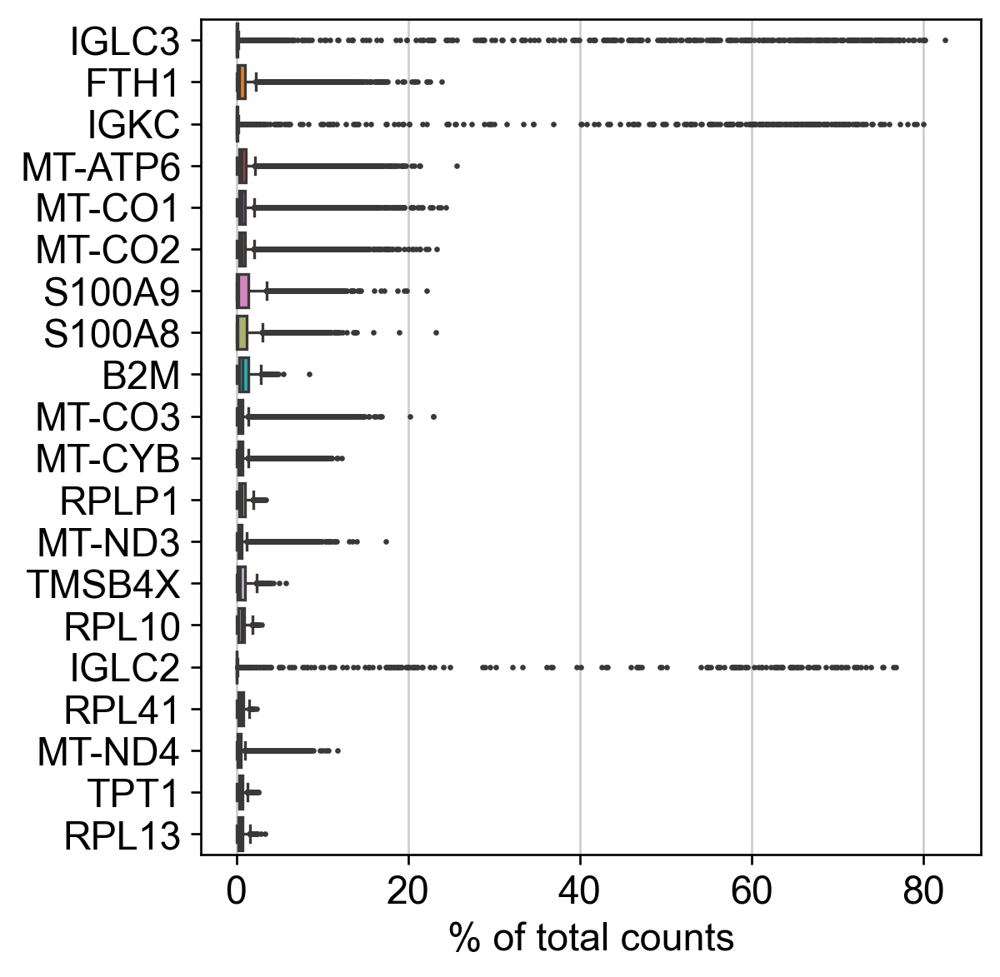

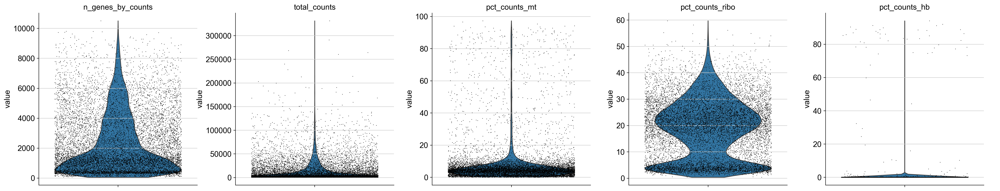

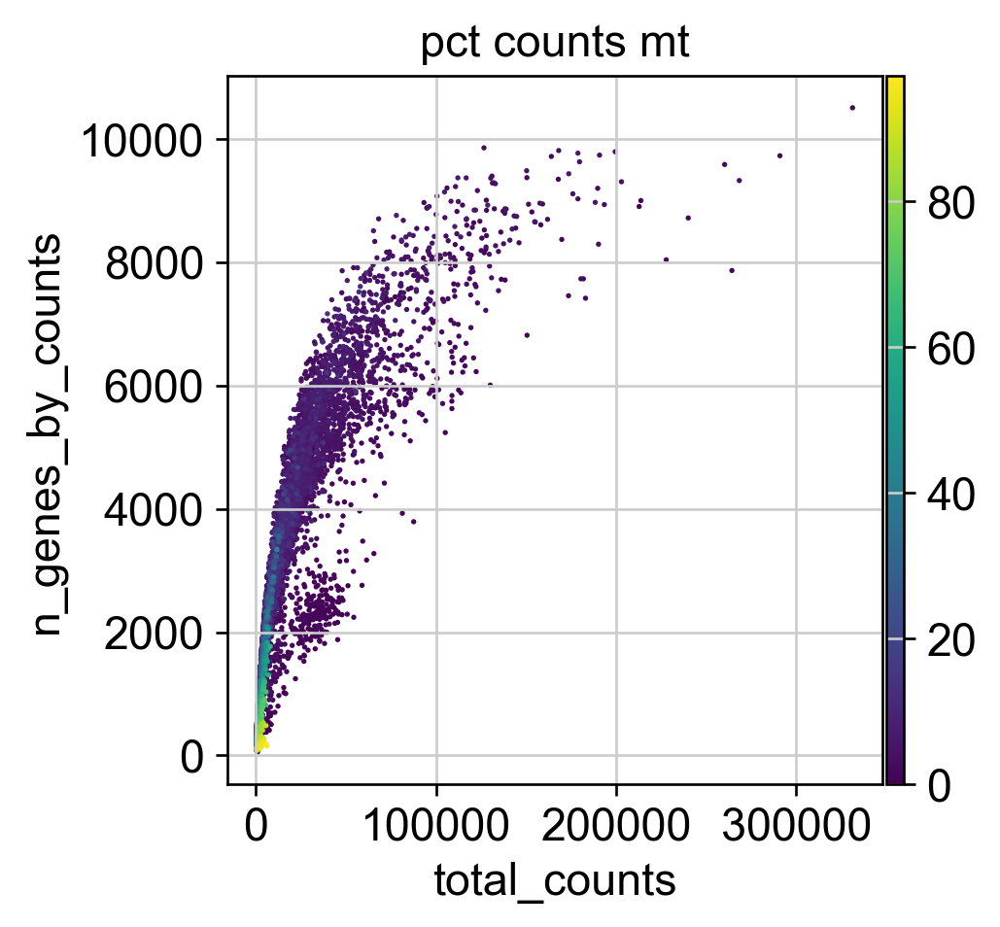

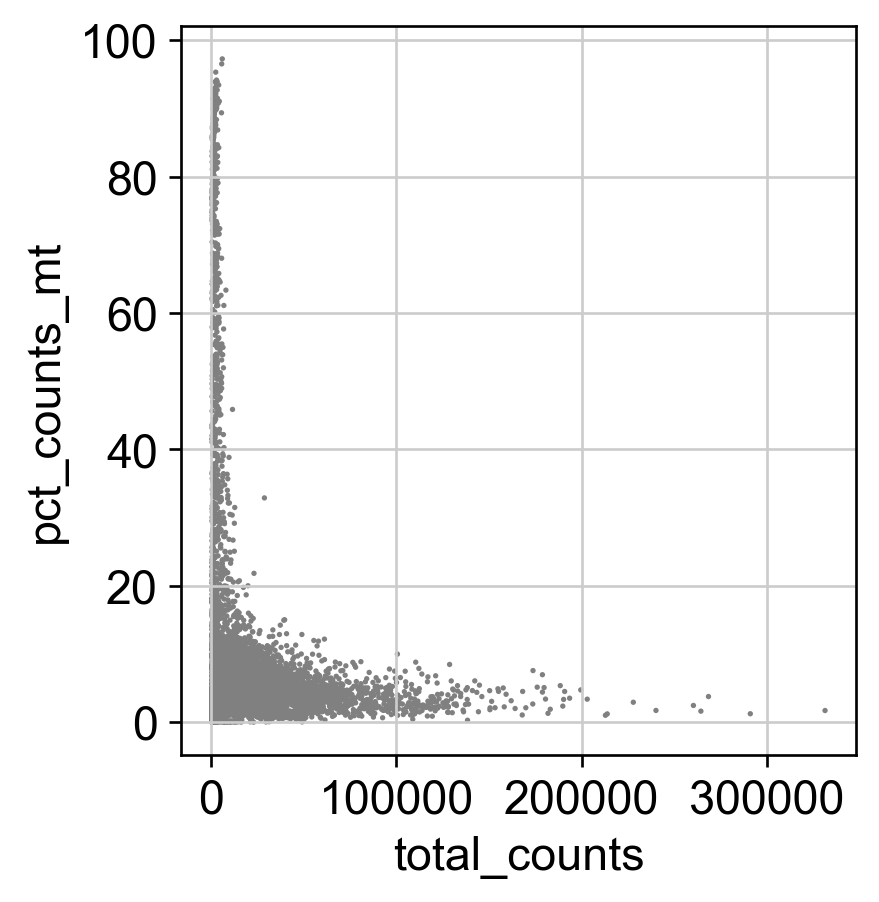

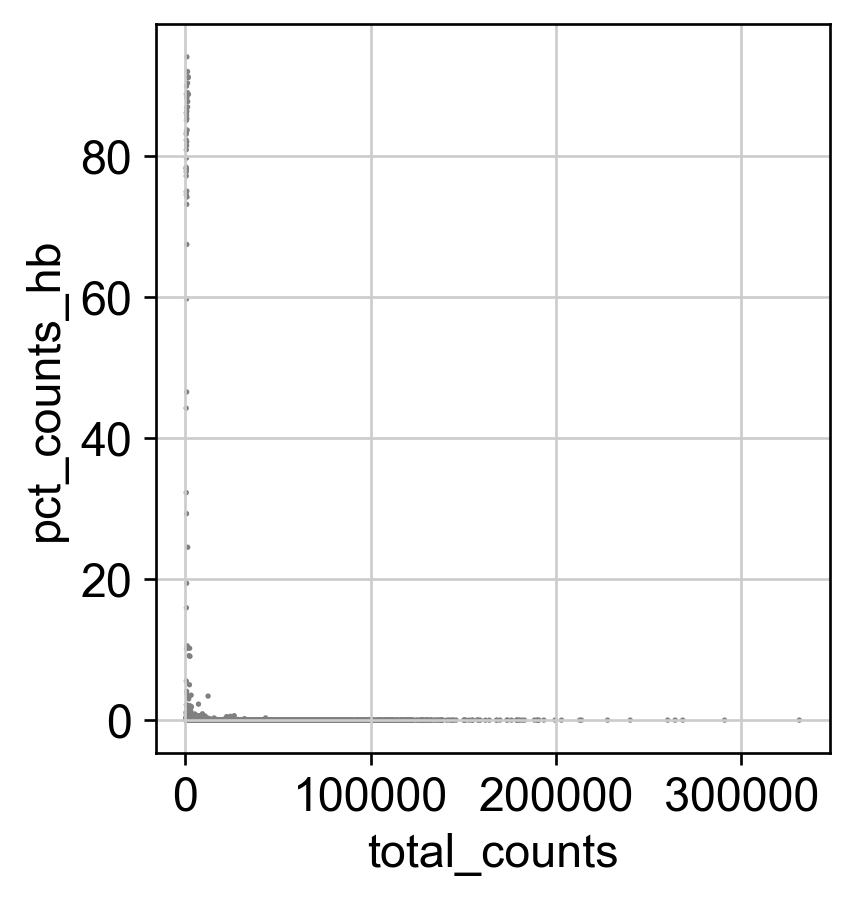

In [8]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [9]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3420 genes that are detected in less than 3 cells
Cells before QC: 11619
Cells after QC : 10830
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_75199/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


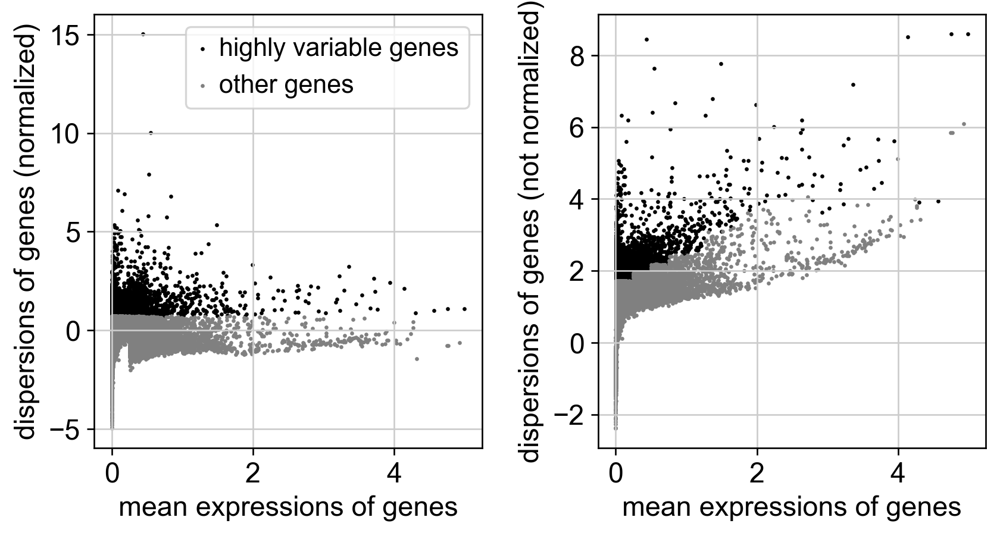

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


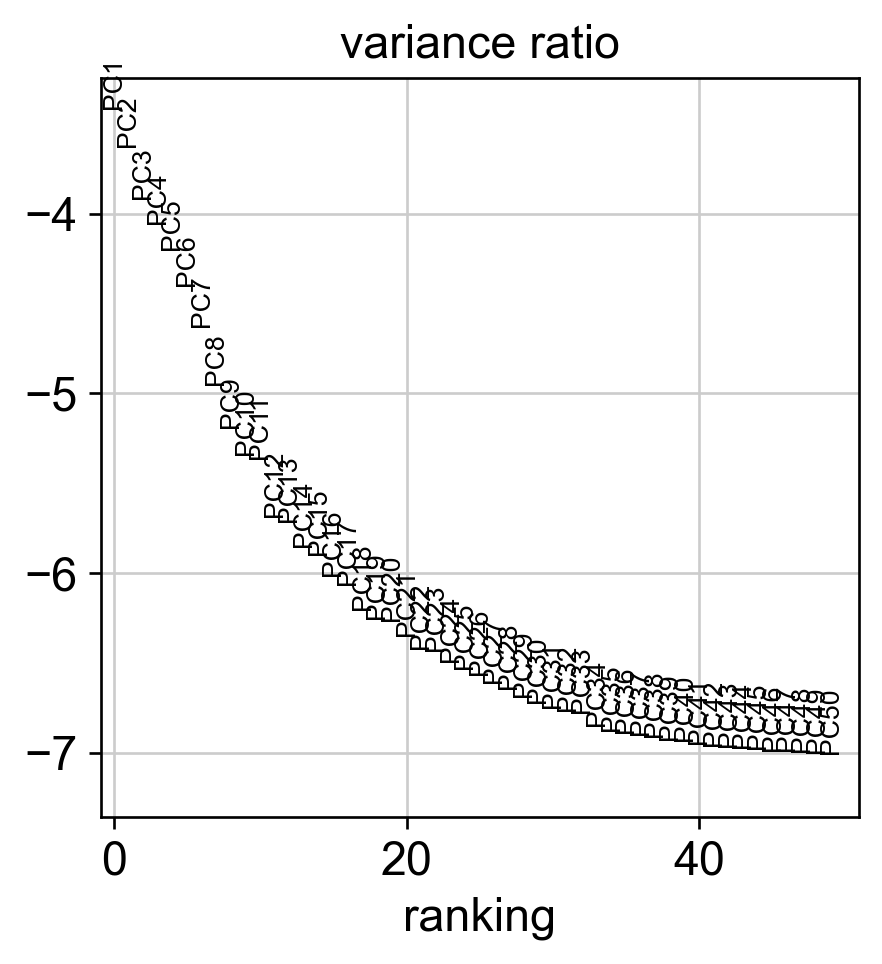

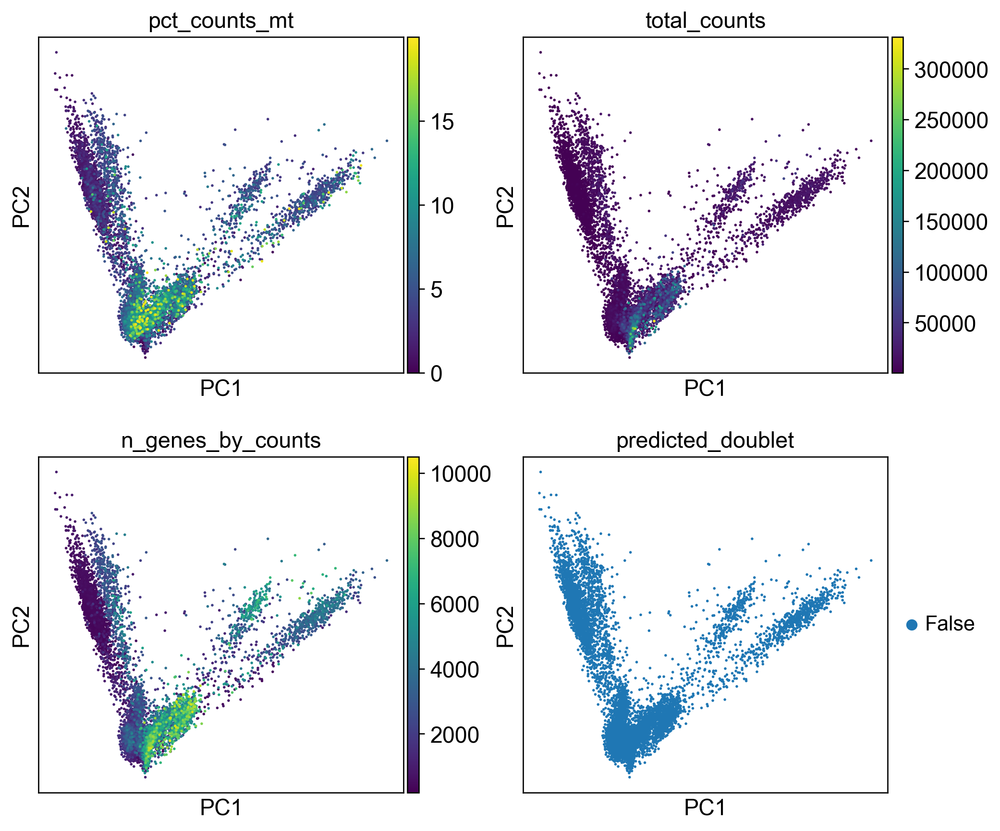

In [10]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [11]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 39
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 39


$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:11)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:05)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 11 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 15 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 18 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden clustering
    finished: found 19 clusters and added
    'le

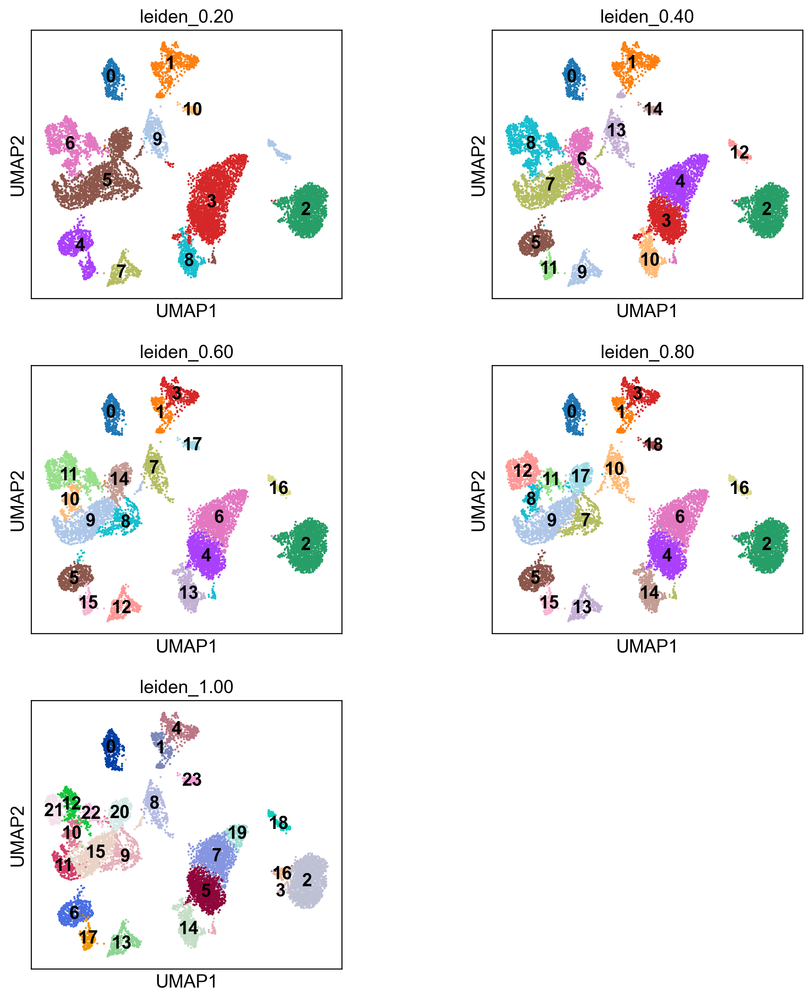

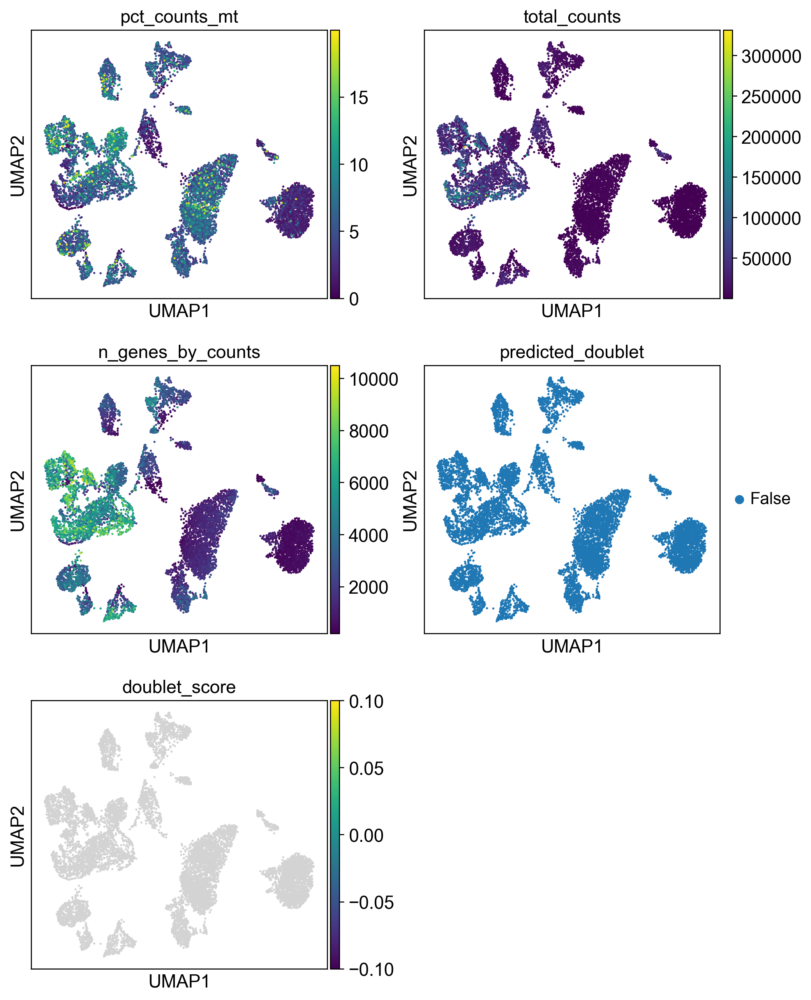

In [12]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [13]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.80"
TOP_N_MARKERS = 15

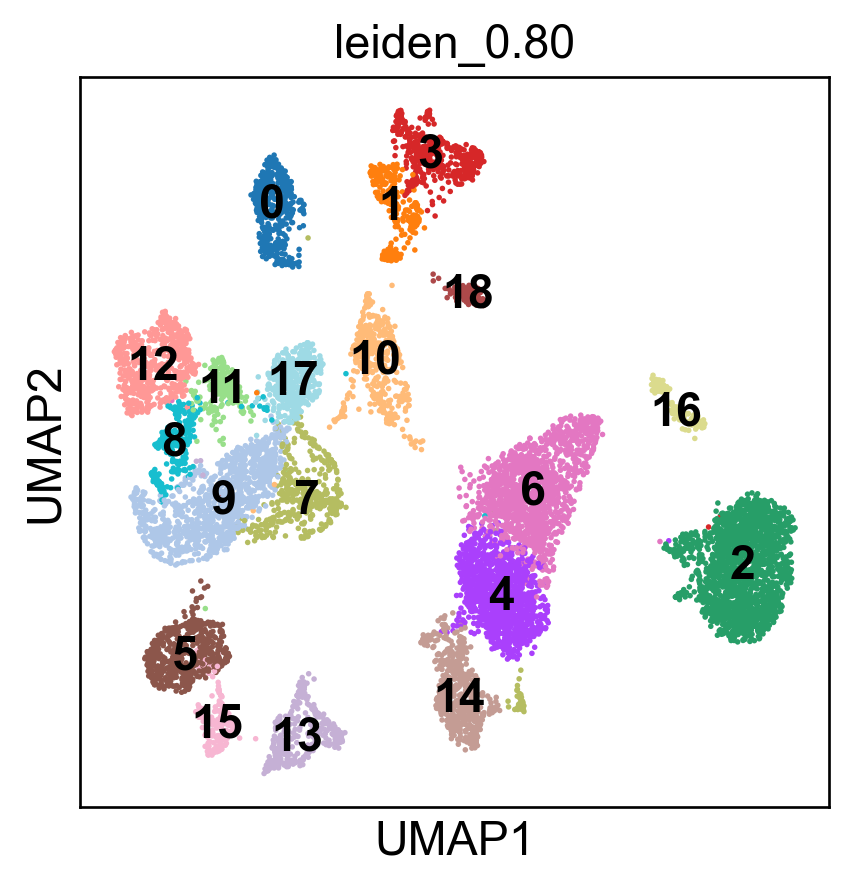

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.80']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:09)


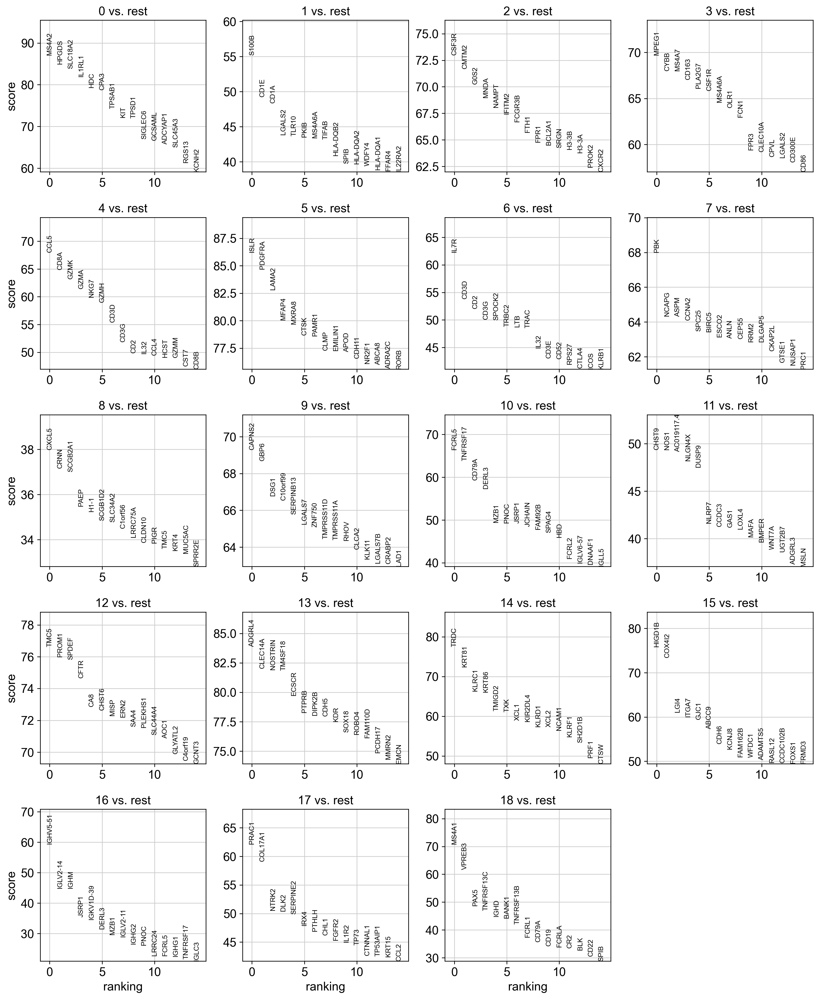

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.80']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
rank_1,MS4A2,S100B,CSF3R,MPEG1,CCL5,ISLR,IL7R,PBK,CXCL5,CAPNS2,FCRL5,CHST9,TMC5,ADGRL4,TRDC,HIGD1B,IGHV5-51,PRAC1,MS4A1
rank_2,HPGDS,CD1E,CMTM2,CYBB,CD8A,PDGFRA,CD3D,NCAPG,CRNN,GBP6,TNFRSF17,NOS1,PROM1,CLEC14A,KRT81,COX4I2,IGLV2-14,COL17A1,VPREB3
rank_3,SLC18A2,CD1A,G0S2,MS4A7,GZMK,LAMA2,CD2,ASPM,SCGB2A1,DSG1,CD79A,AC019117.4,SPDEF,NOSTRIN,KLRC1,LGI4,IGHM,NTRK2,PAX5
rank_4,IL1RL1,LGALS2,MNDA,CD163,GZMA,MFAP4,CD3G,CCNA2,PAEP,C10orf99,DERL3,NLGN4X,CFTR,TM4SF18,KRT86,ITGA7,JSRP1,DLK2,TNFRSF13C
rank_5,HDC,TLR10,NAMPT,PLA2G7,NKG7,MXRA8,SPOCK2,SPC25,H1-1,SERPINB13,MZB1,DUSP9,CA8,ECSCR,TMIGD2,GJC1,IGKV1D-39,SERPINE2,IGHD
rank_6,CPA3,PKIB,IFITM2,CSF1R,GZMH,CTSK,TRBC2,BIRC5,SCGB1D2,LGALS7,PNOC,NLRP7,CHST6,PTPRB,TXK,ABCC9,DERL3,IRX4,BANK1
rank_7,TPSAB1,MS4A6A,FCGR3B,MS4A6A,CD3D,PAMR1,LTB,ESCO2,SLC34A2,ZNF750,JSRP1,CCDC3,MISP,DIPK2B,XCL1,CDH6,MZB1,PTHLH,TNFRSF13B
rank_8,KIT,TIFAB,FTH1,OLR1,CD3G,CLMP,TRAC,ANLN,C1orf56,TMPRSS11D,JCHAIN,GAS1,ERN2,CDH5,KIR2DL4,KCNJ8,IGLV2-11,CHL1,FCRL1
rank_9,TPSD1,HLA-DQB2,FPR1,FCN1,CD2,EMILIN1,IL32,CEP55,LRRC75A,TMPRSS11A,FAM92B,LOXL4,SAA4,KDR,KLRD1,FAM162B,IGHG2,FGFR2,CD79A
rank_10,SIGLEC6,SPIB,BCL2A1,FPR3,IL32,APOD,CD3E,RRM2,CLDN10,RHOV,SPAG4,MAFA,PLEKHS1,SOX18,XCL2,WFDC1,PNOC,IL1R2,CD19


In [14]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [15]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------
print_annotation_template(adata, CLUSTER_KEY)

Fill this dictionary with your manual annotation:
cluster_to_cell_type = {
    "0": "",
    "1": "",
    "2": "",
    "3": "",
    "4": "",
    "5": "",
    "6": "",
    "7": "",
    "8": "",
    "9": "",
    "10": "",
    "11": "",
    "12": "",
    "13": "",
    "14": "",
    "15": "",
    "16": "",
    "17": "",
    "18": "",
}


In [16]:
# Fill with annotations
cluster_to_cell_type = {
    "0": "mast cells",
    "1": "Langerhans cells / dendritic cells",
    "2": "neutrophils",
    "3": "monocytes/macrophages",
    "4": "cytotoxic CD8+ T cells",
    "5": "fibroblasts",
    "6": "CD4+ T cells",
    "7": "cycling/proliferating cells",
    "8": "secretory glandular epithelial cells",
    "9": "squamous epithelial cells",
    "10": "plasma cells",
    "11": "epithelial cells (unclassified/rare)",
    "12": "glandular/secretory epithelial cells",
    "13": "endothelial cells",
    "14": "gamma-delta T cells",
    "15": "pericytes",
    "16": "plasma cells",
    "17": "basal/reserve epithelial cells",
    "18": "B cells"
}

In [17]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360680_N_HPV_NEG_1__celltype_mapping.tsv.gz
                                                                             cell_id               sample_id leiden_0.80                           cell_type
GSM6360680_N_HPV_NEG_1_AAACCCAAGGTGCGAT-1  GSM6360680_N_HPV_NEG_1_AAACCCAAGGTGCGAT-1  GSM6360680_N_HPV_NEG_1           0                          mast cells
GSM6360680_N_HPV_NEG_1_AAACCCACAATAACCC-1  GSM6360680_N_HPV_NEG_1_AAACCCACAATAACCC-1  GSM6360680_N_HPV_NEG_1           1  Langerhans cells / dendritic cells
GSM6360680_N_HPV_NEG_1_AAACCCACACATCCCT-1  GSM6360680_N_HPV_NEG_1_AAACCCACACATCCCT-1  GSM6360680_N_HPV_NEG_1           2                         neutrophils
GSM6360680_N_HPV_NEG_1_AAACCCACACGGCCAT-1  GSM6360680_N_HPV_NEG_1_AAACCCACACGGCCAT-1  GSM6360680_N_HPV_NEG_1           3               monocytes/macrophages
GSM6360680_N_HPV_NEG_1_AAACCCACAGTGTGCC-1  GSM

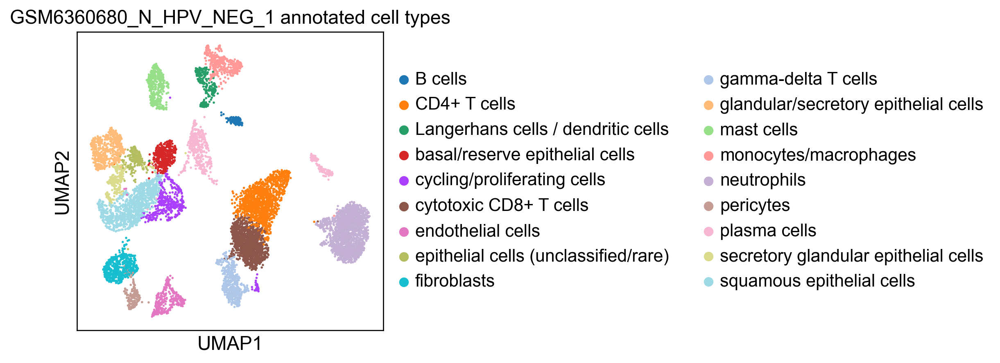

In [19]:
# Look cell type on umap
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360681_N_HPV_NEG_2

In [20]:
sample_id = "GSM6360681_N_HPV_NEG_2"

AnnData object with n_obs × n_vars = 9203 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3755 genes that are detected in less than 3 cells


,suggested_value
min_counts,84.00
max_counts,118153.00
min_genes,100.00
max_genes,17997.00
max_pct_mt,12.39


QC plots for GSM6360681_N_HPV_NEG_2
normalizing counts per cell
    finished (0:00:00)


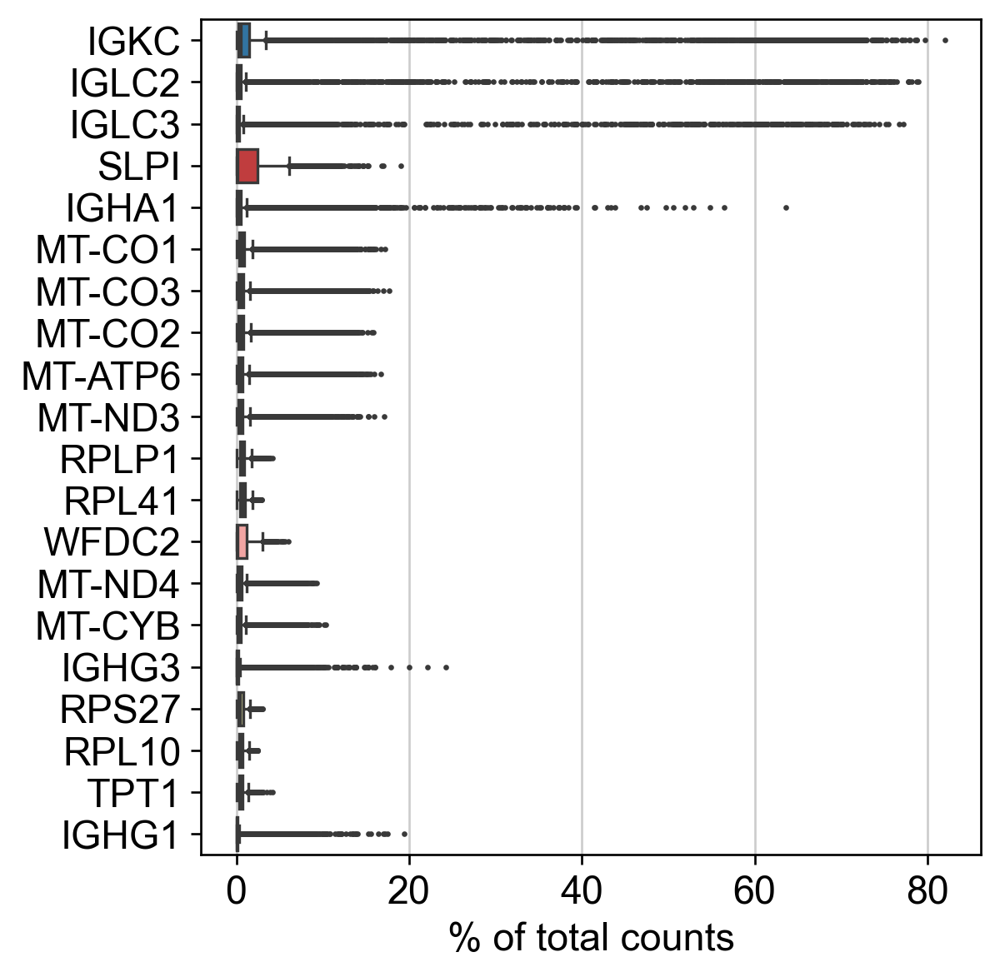

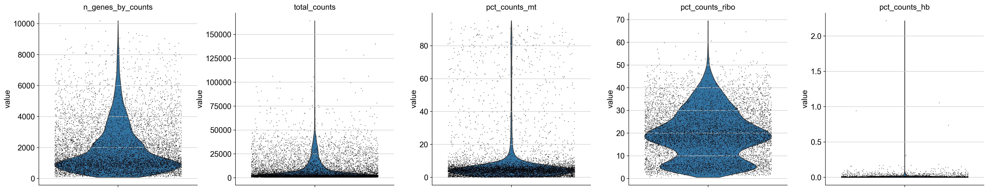

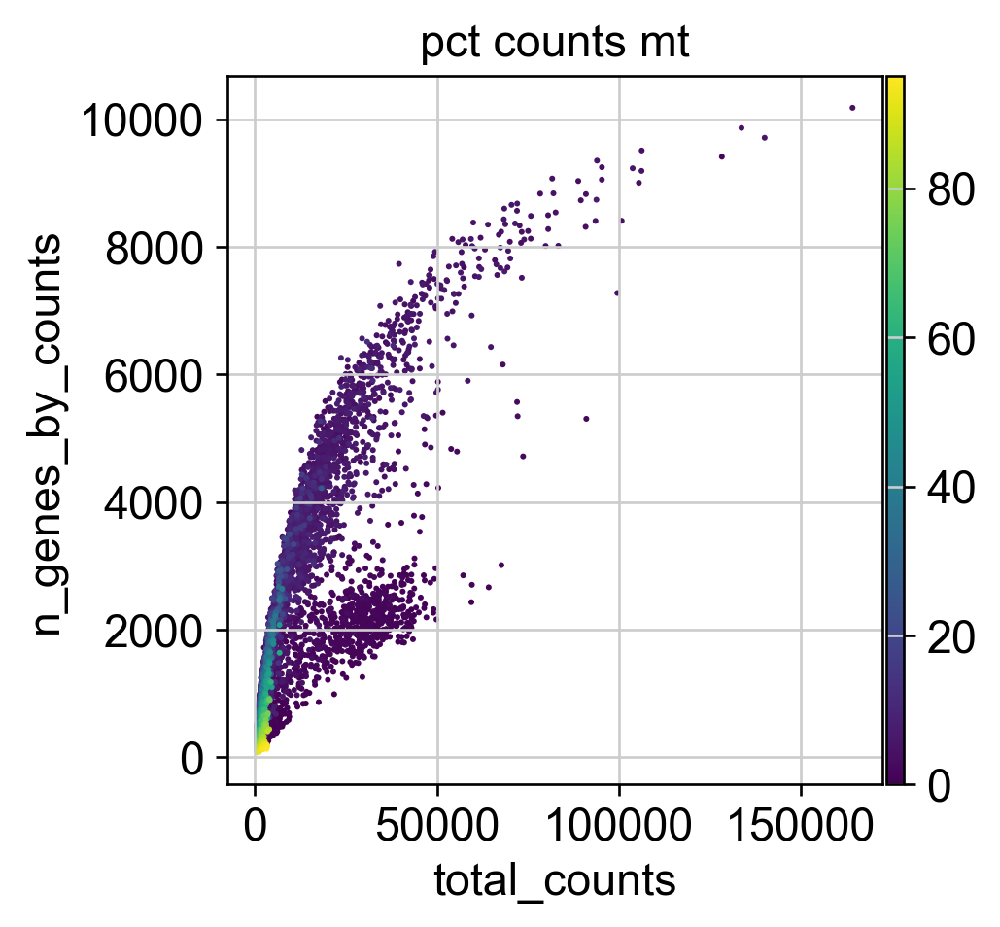

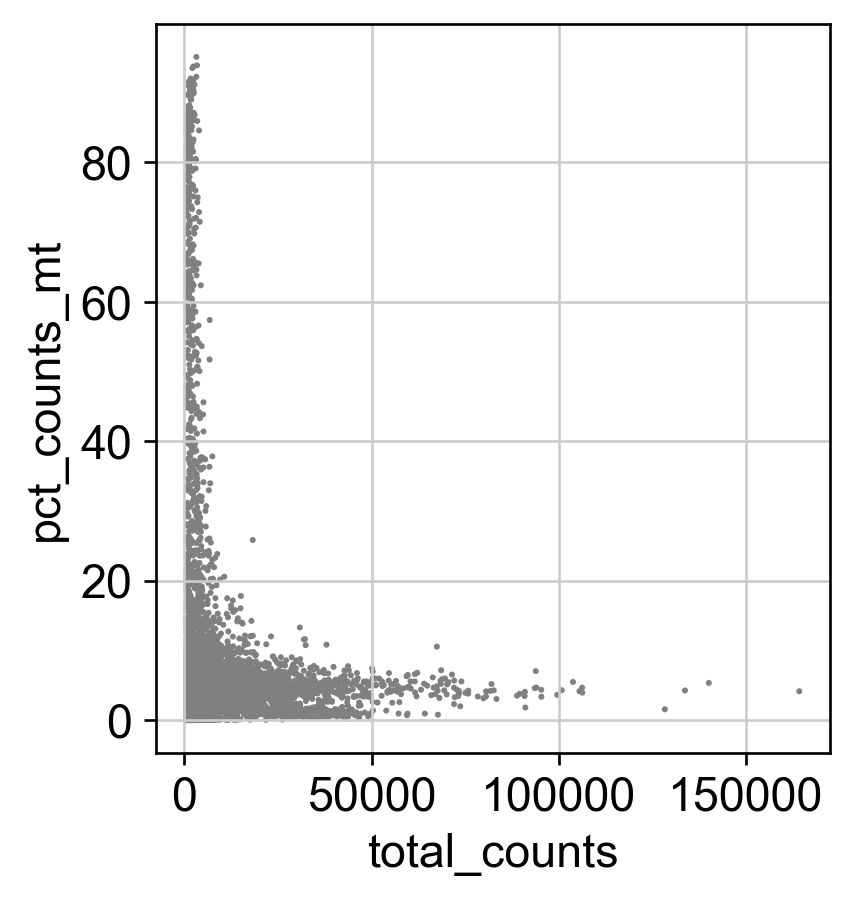

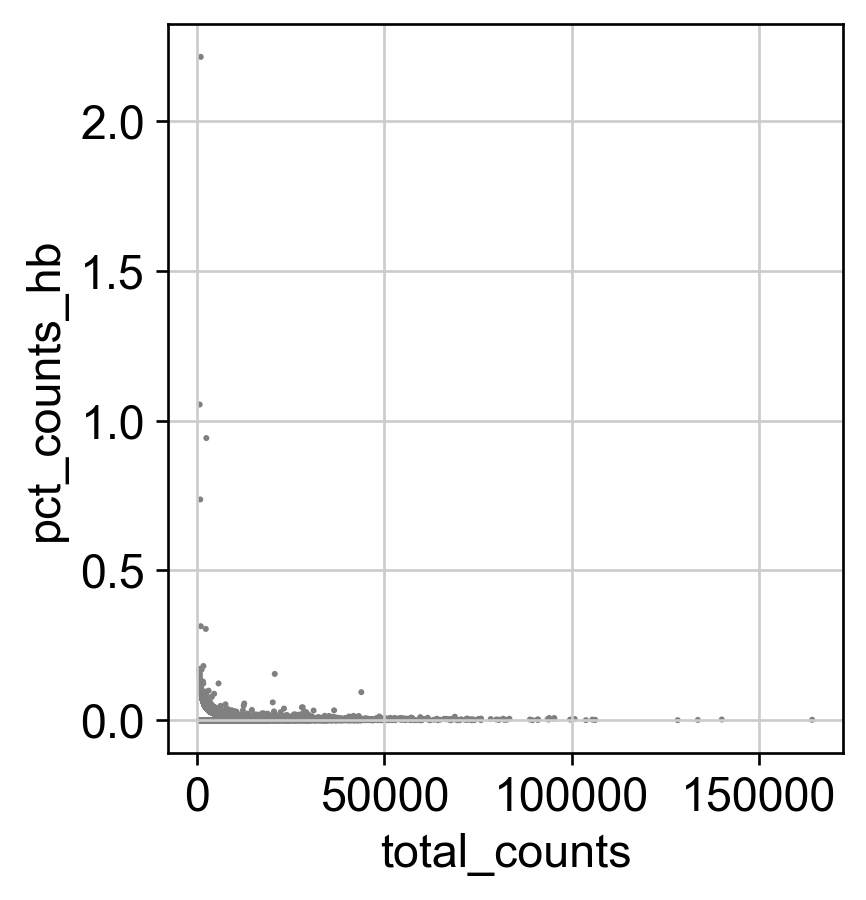

In [21]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [22]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3755 genes that are detected in less than 3 cells
Cells before QC: 9203
Cells after QC : 8568
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_75199/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


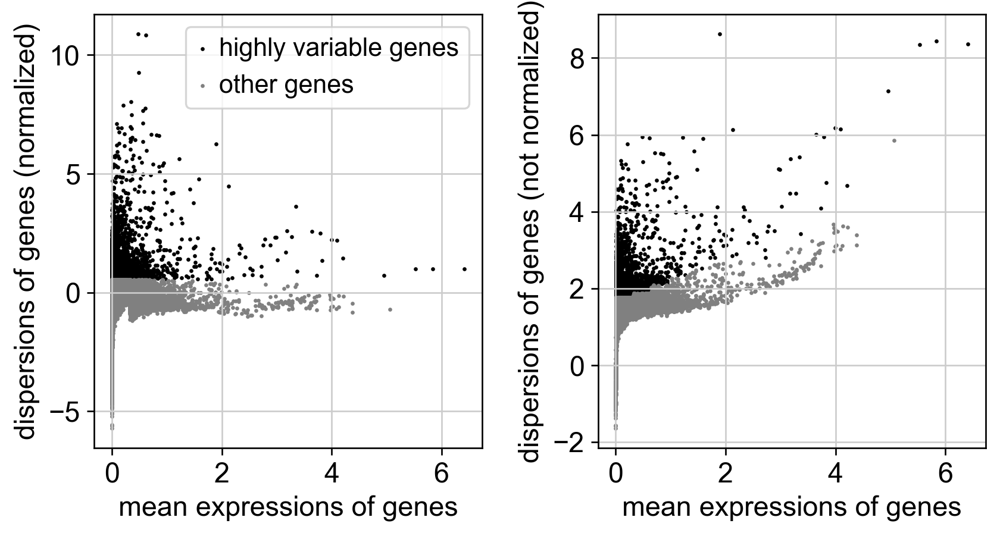

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


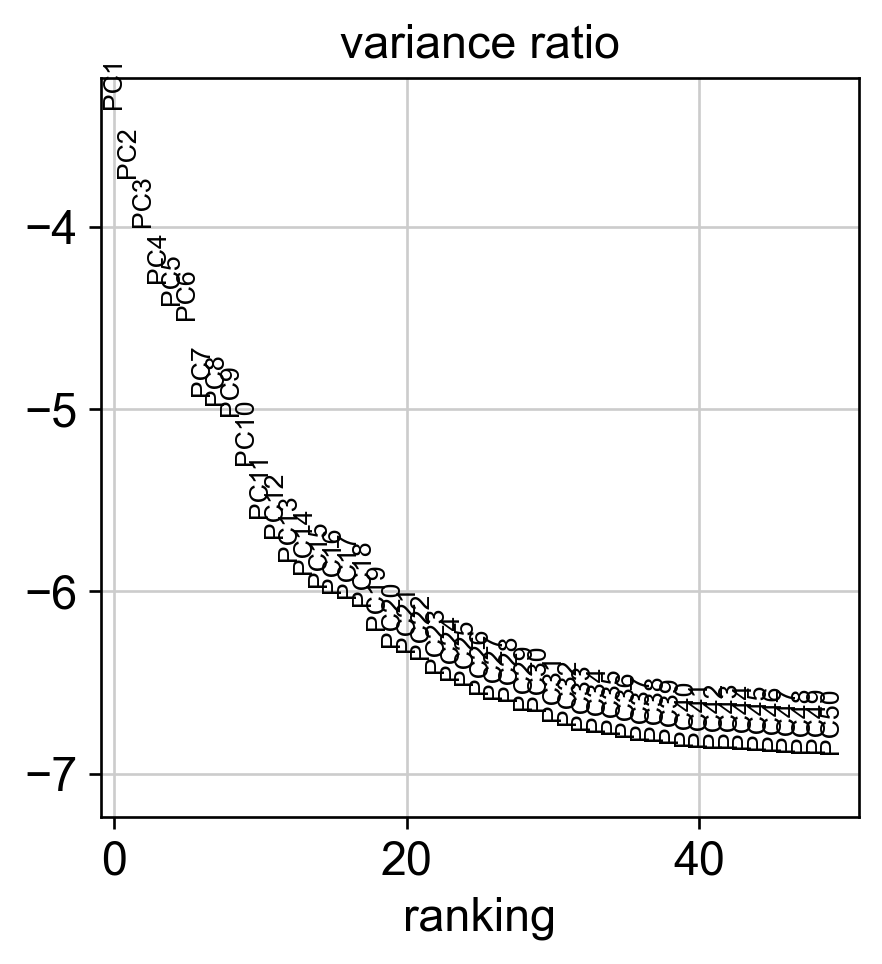

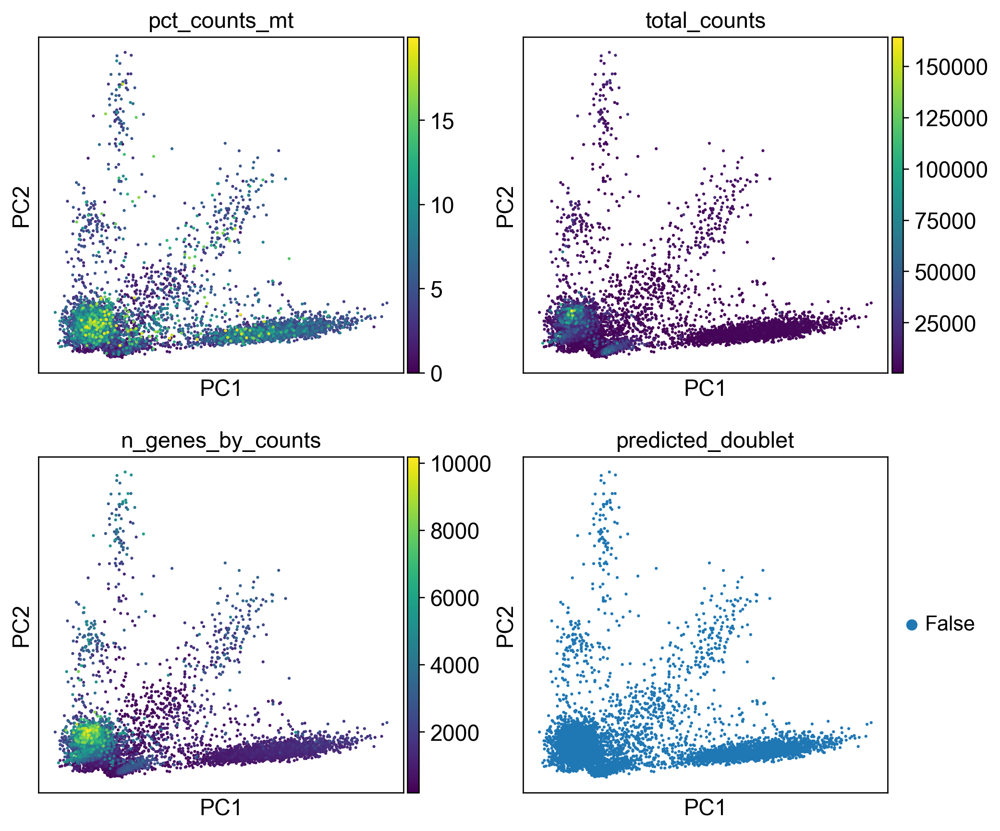

In [23]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [24]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 38
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 38
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:09)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 13 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 19 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 21 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden cluste

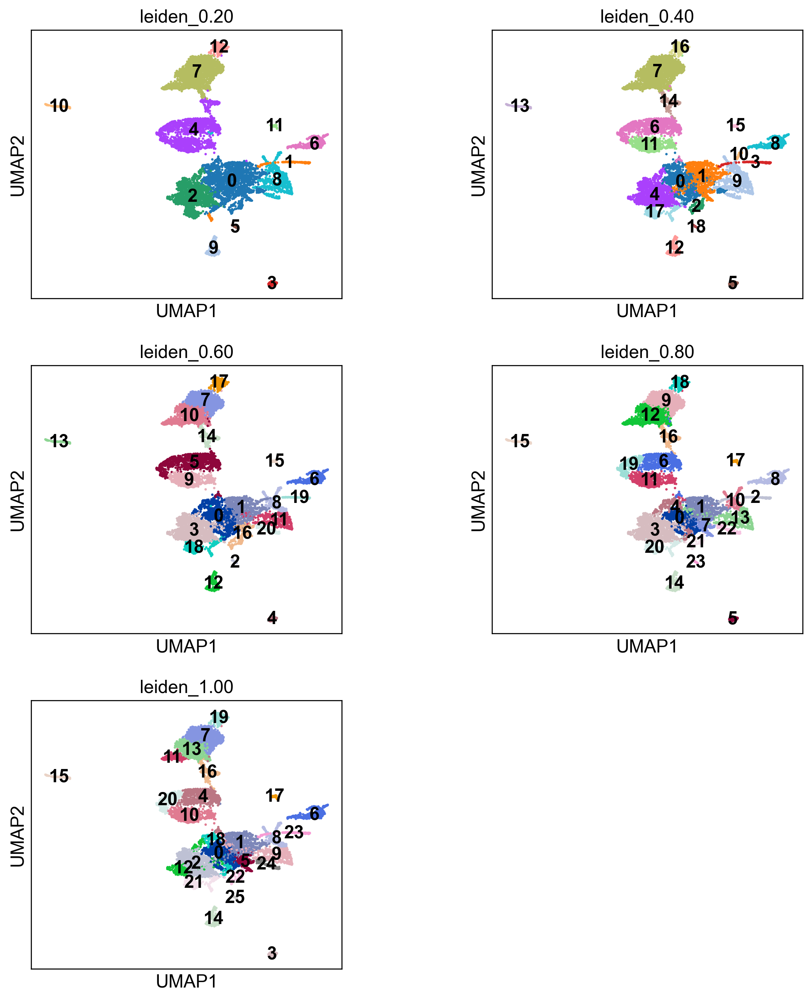

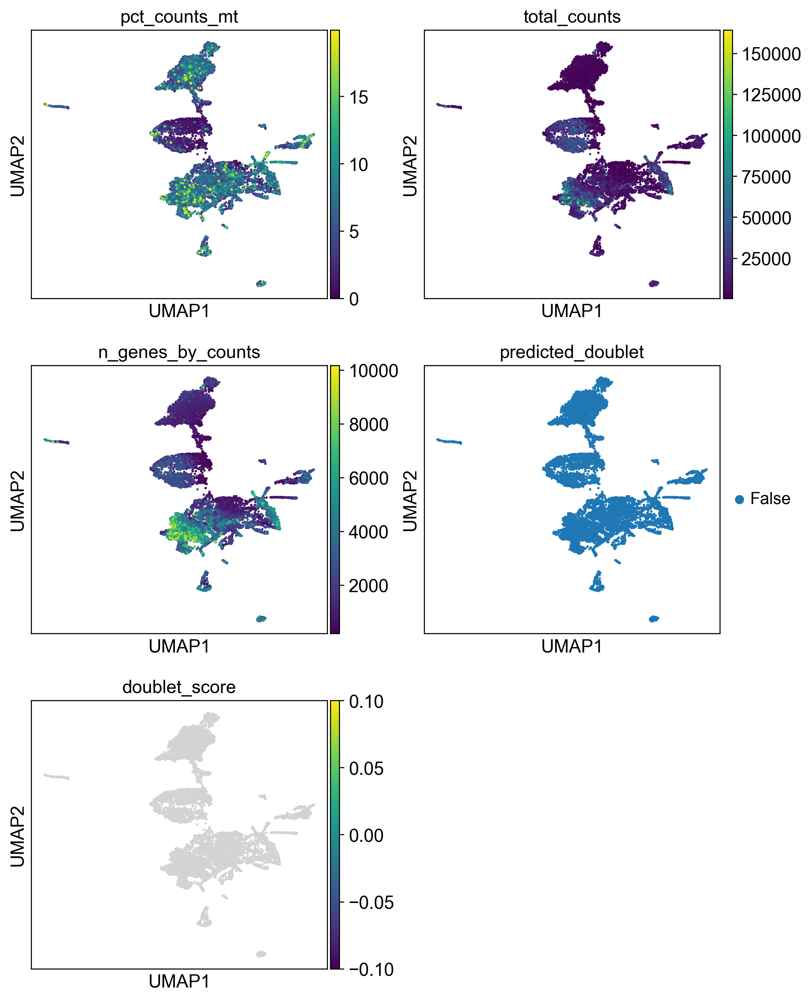

In [25]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [26]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.20"
TOP_N_MARKERS = 15

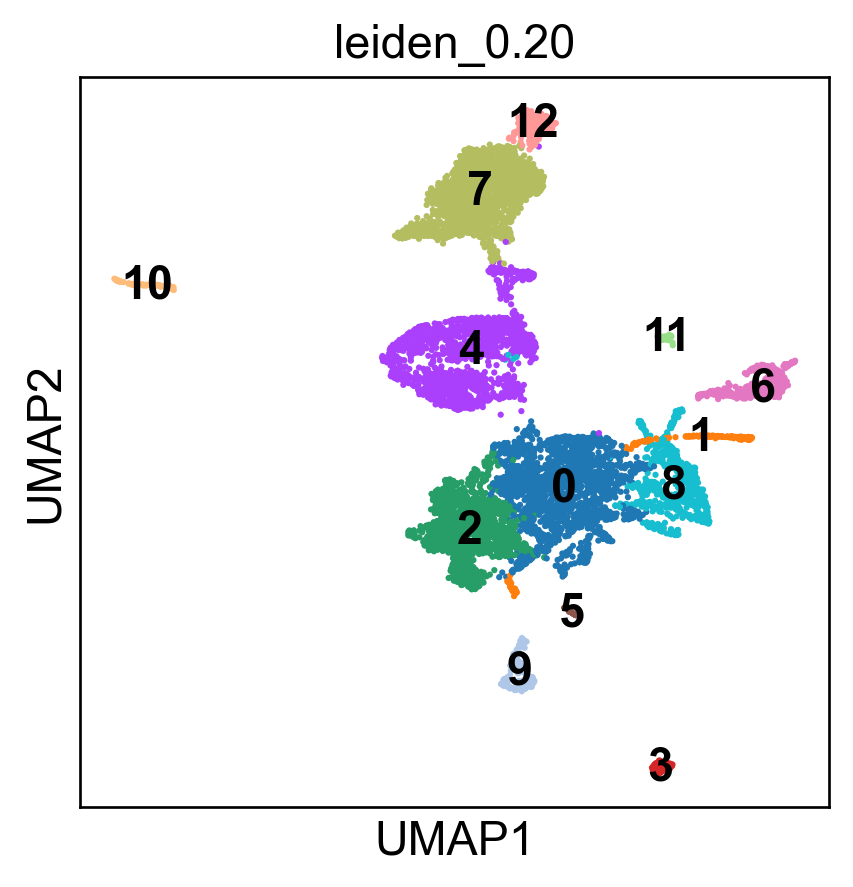

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.20']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:05)


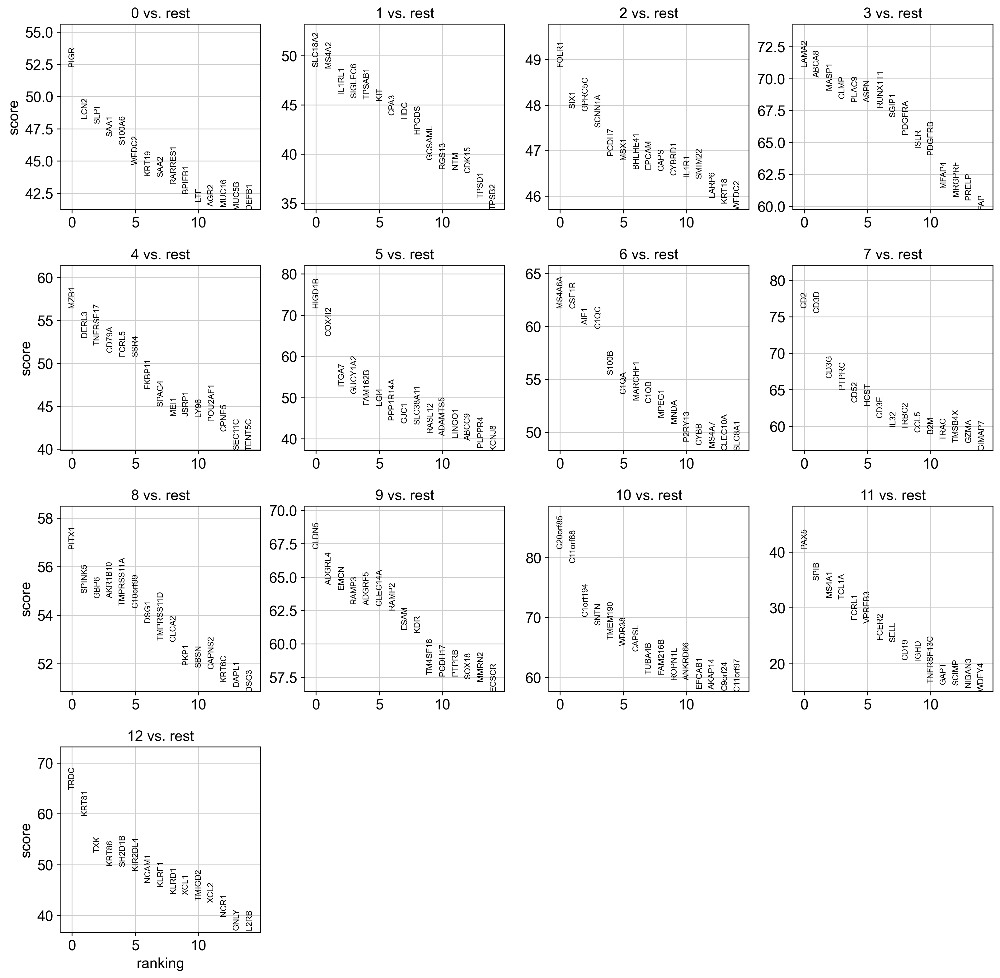

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.20']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12
rank_1,PIGR,SLC18A2,FOLR1,LAMA2,MZB1,HIGD1B,MS4A6A,CD2,PITX1,CLDN5,C20orf85,PAX5,TRDC
rank_2,LCN2,MS4A2,SIX1,ABCA8,DERL3,COX4I2,CSF1R,CD3D,SPINK5,ADGRL4,C11orf88,SPIB,KRT81
rank_3,SLPI,IL1RL1,GPRC5C,MASP1,TNFRSF17,ITGA7,AIF1,CD3G,GBP6,EMCN,C1orf194,MS4A1,TXK
rank_4,SAA1,SIGLEC6,SCNN1A,CLMP,CD79A,GUCY1A2,C1QC,PTPRC,AKR1B10,RAMP3,SNTN,TCL1A,KRT86
rank_5,S100A6,TPSAB1,PCDH7,PLAC9,FCRL5,FAM162B,S100B,CD52,TMPRSS11A,ADGRF5,TMEM190,FCRL1,SH2D1B
rank_6,WFDC2,KIT,MSX1,ASPN,SSR4,LGI4,C1QA,HCST,C10orf99,CLEC14A,WDR38,VPREB3,KIR2DL4
rank_7,KRT19,CPA3,BHLHE41,RUNX1T1,FKBP11,PPP1R14A,MARCHF1,CD3E,DSG1,RAMP2,CAPSL,FCER2,NCAM1
rank_8,SAA2,HDC,EPCAM,SGIP1,SPAG4,GJC1,C1QB,IL32,TMPRSS11D,ESAM,TUBA4B,SELL,KLRF1
rank_9,RARRES1,HPGDS,CAPS,PDGFRA,MEI1,SLC38A11,MPEG1,TRBC2,CLCA2,KDR,FAM216B,CD19,KLRD1
rank_10,BPIFB1,GCSAML,CYBRD1,ISLR,JSRP1,RASL12,MNDA,CCL5,PKP1,TM4SF18,ROPN1L,IGHD,XCL1


In [27]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [28]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "secretory endocervical epithelial cells",
    "1": "mast cells",
    "2": "endocervical / glandular epithelial cells",
    "3": "stromal fibroblasts",
    "4": "plasma cells",
    "5": "mural cells (pericytes / vascular smooth muscle cells)",
    "6": "C1QC+ macrophages",
    "7": "T cells (likely cytotoxic alpha-beta T cells)",
    "8": "squamous epithelial cells",
    "9": "endothelial cells",
    "10": "ciliated endocervical epithelial cells",
    "11": "naive B cells",
    "12": "gamma-delta T / NK-like cytotoxic lymphocytes",
}

In [29]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360681_N_HPV_NEG_2__celltype_mapping.tsv.gz
                                                                             cell_id               sample_id leiden_0.20                                  cell_type
GSM6360681_N_HPV_NEG_2_AAACCCACAAGAGTGC-1  GSM6360681_N_HPV_NEG_2_AAACCCACAAGAGTGC-1  GSM6360681_N_HPV_NEG_2           0    secretory endocervical epithelial cells
GSM6360681_N_HPV_NEG_2_AAACCCAGTCTGTGGC-1  GSM6360681_N_HPV_NEG_2_AAACCCAGTCTGTGGC-1  GSM6360681_N_HPV_NEG_2           2  endocervical / glandular epithelial cells
GSM6360681_N_HPV_NEG_2_AAACCCAGTTCCACAA-1  GSM6360681_N_HPV_NEG_2_AAACCCAGTTCCACAA-1  GSM6360681_N_HPV_NEG_2           3                        stromal fibroblasts
GSM6360681_N_HPV_NEG_2_AAACCCATCCATAGAC-1  GSM6360681_N_HPV_NEG_2_AAACCCATCCATAGAC-1  GSM6360681_N_HPV_NEG_2           4                               plasma cells
GSM6360681_

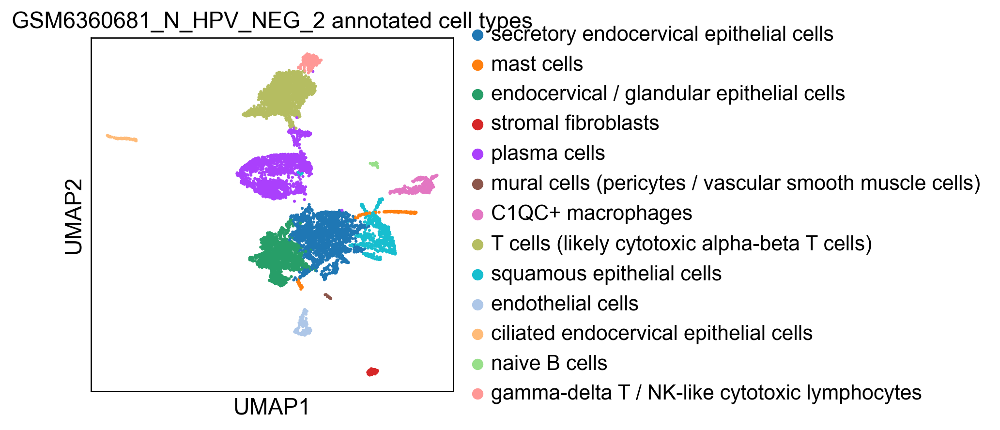

In [30]:
# Look cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360682_N_1

In [31]:
sample_id = "GSM6360682_N_1"

AnnData object with n_obs × n_vars = 16218 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3273 genes that are detected in less than 3 cells


,suggested_value
min_counts,108.00
max_counts,108236.00
min_genes,101.00
max_genes,18438.00
max_pct_mt,13.57


QC plots for GSM6360682_N_1
normalizing counts per cell
    finished (0:00:00)


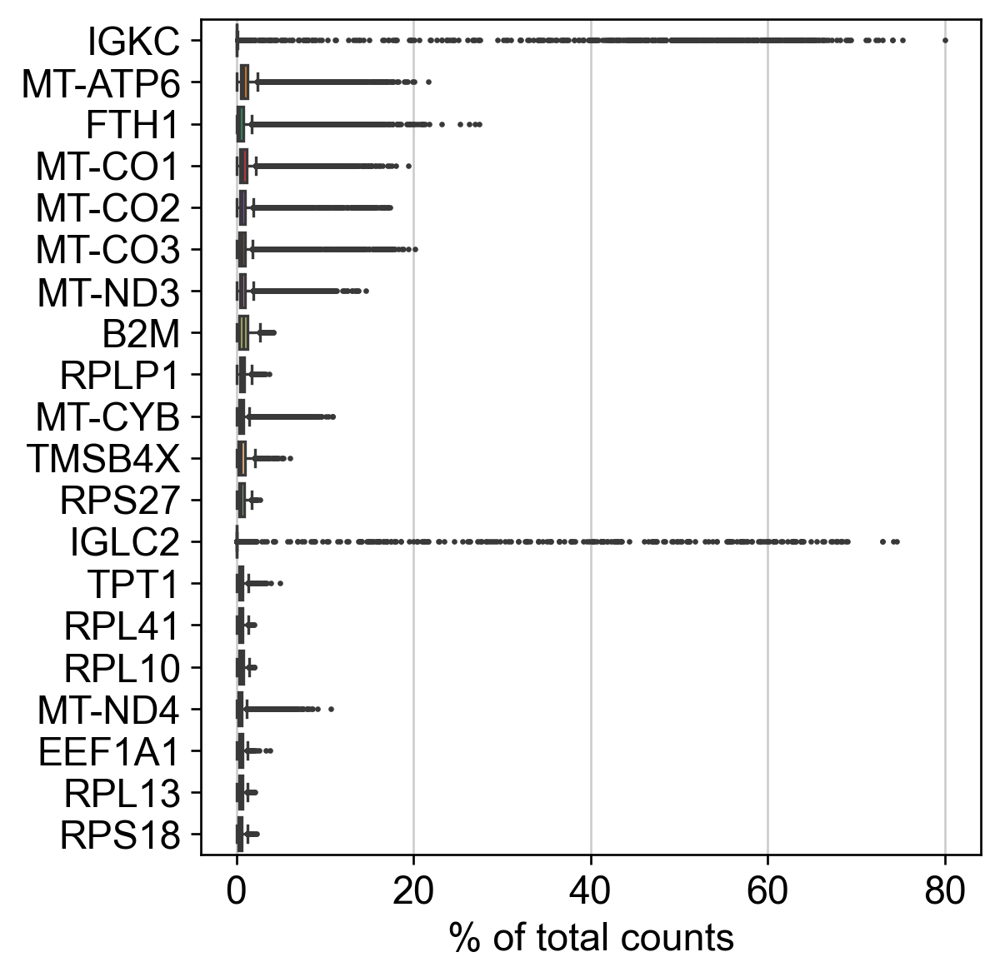

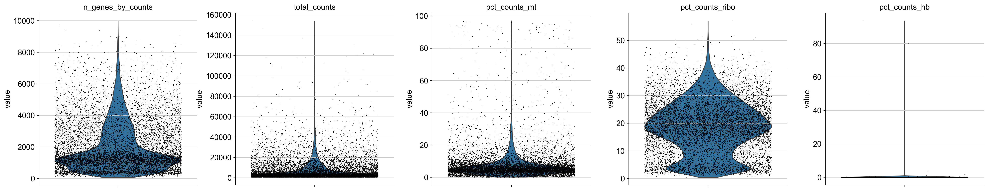

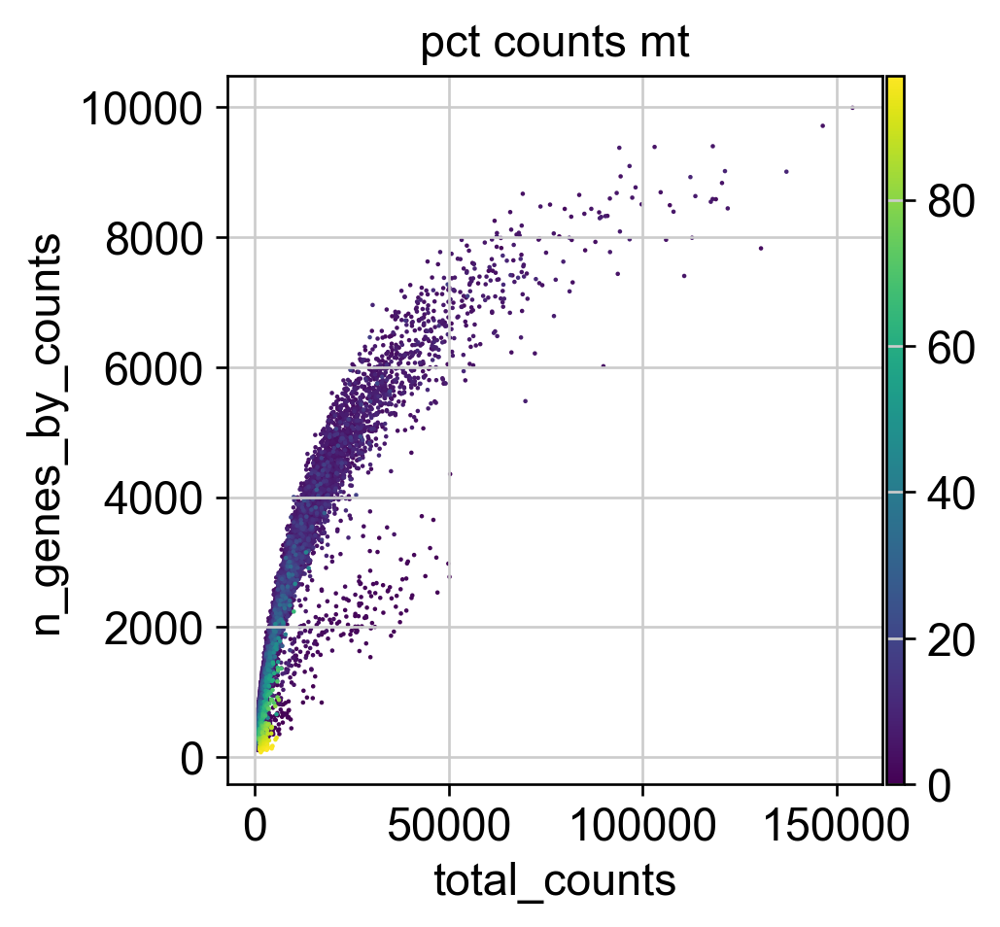

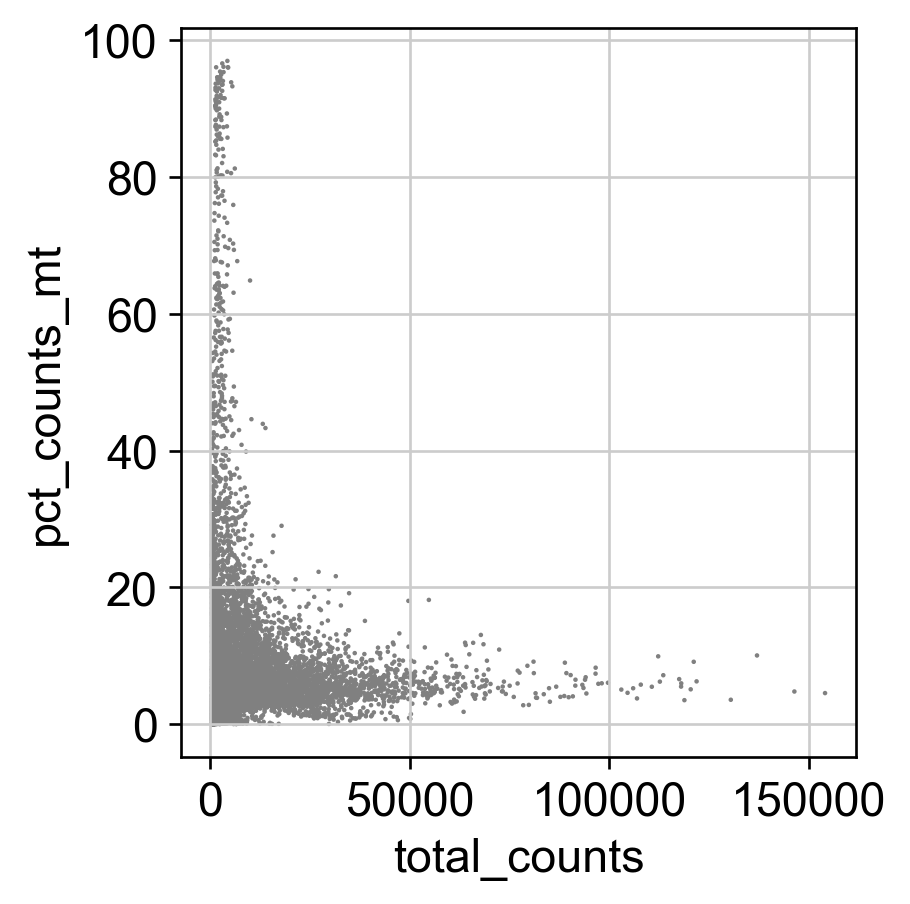

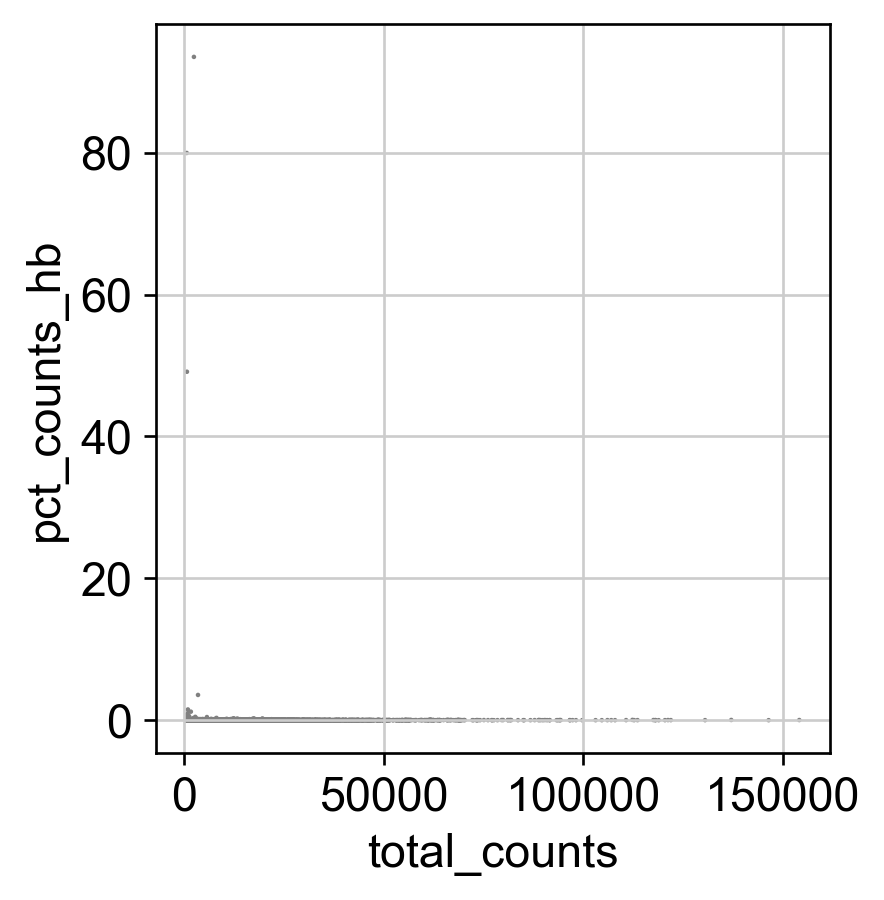

In [32]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [33]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3273 genes that are detected in less than 3 cells
Cells before QC: 16218
Cells after QC : 15310
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_75199/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


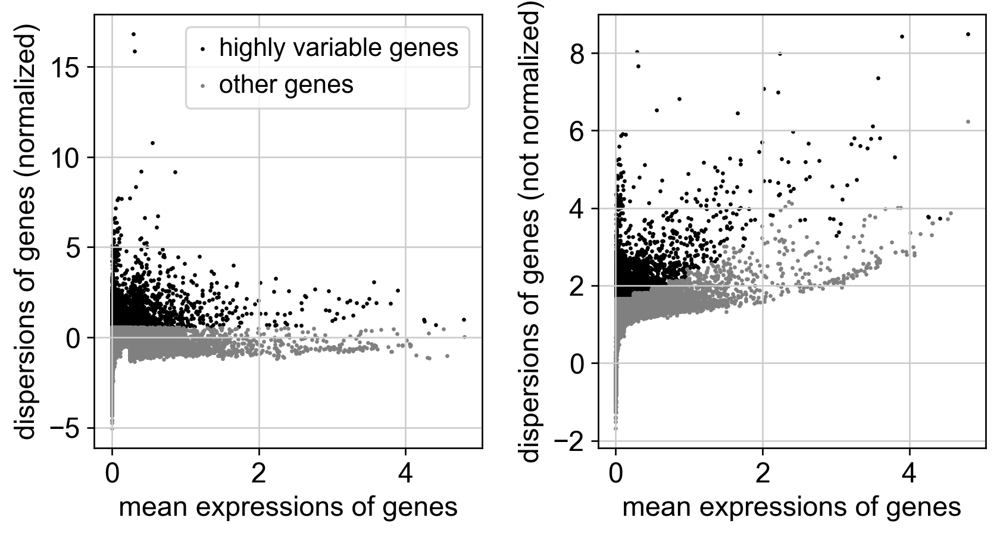

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


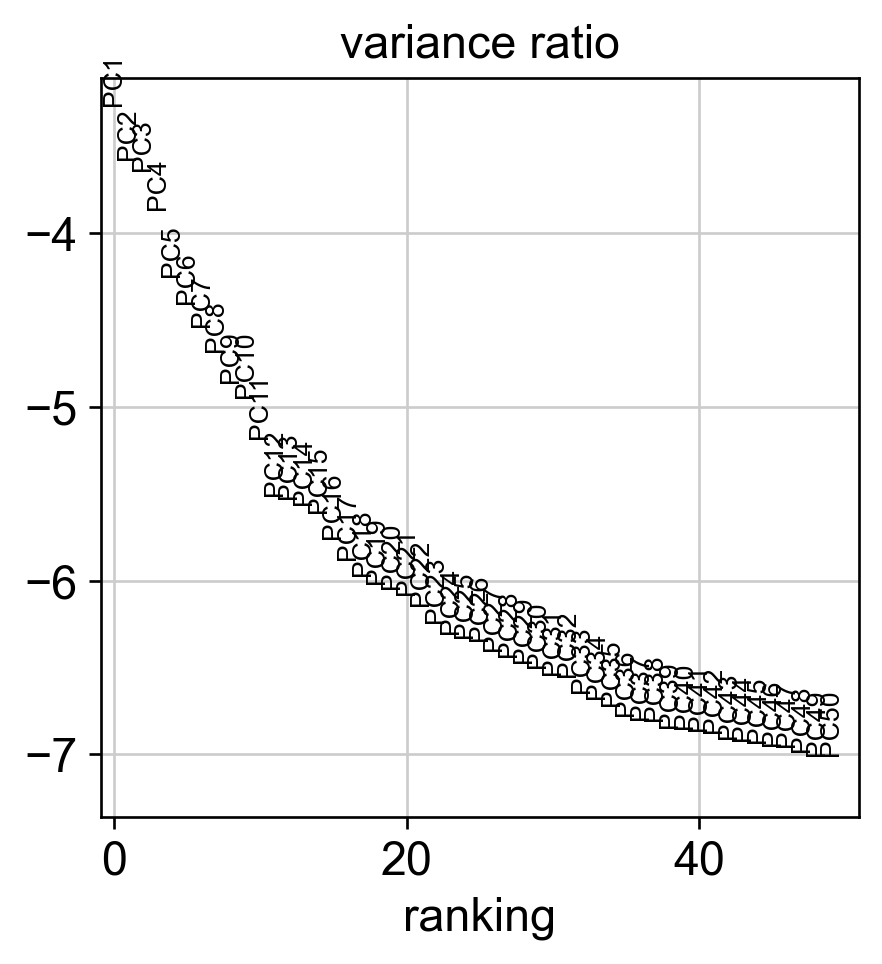

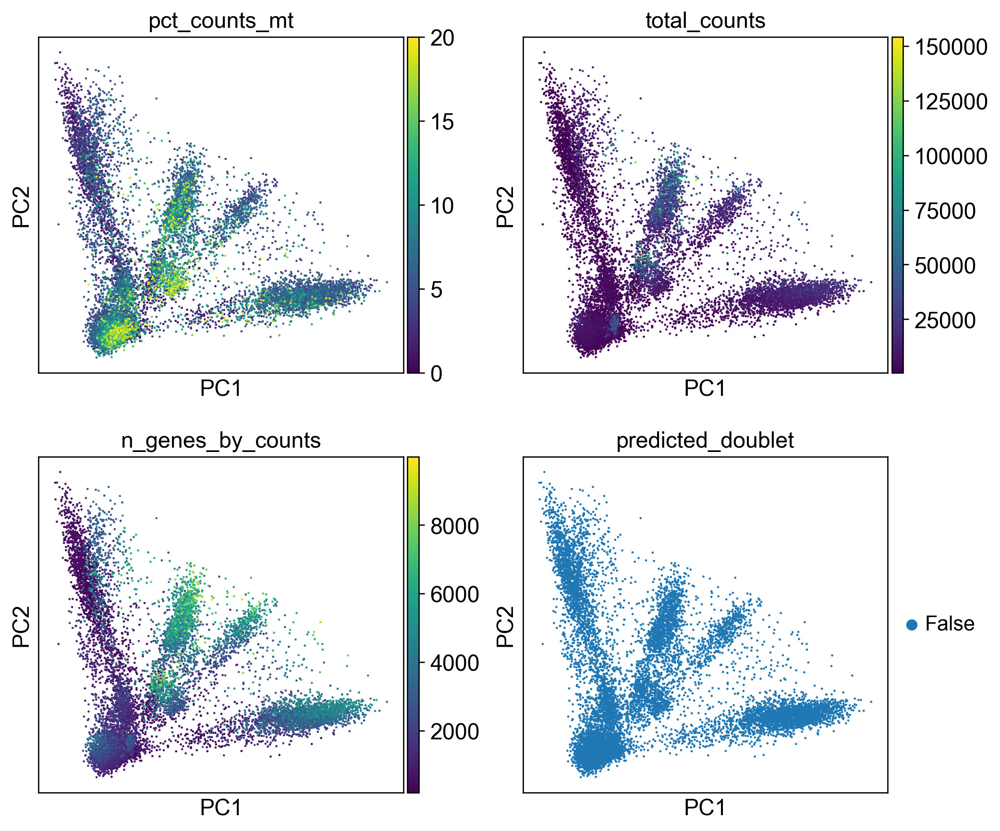

In [34]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [35]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 50
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:07)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 12 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 16 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 18 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden cluste

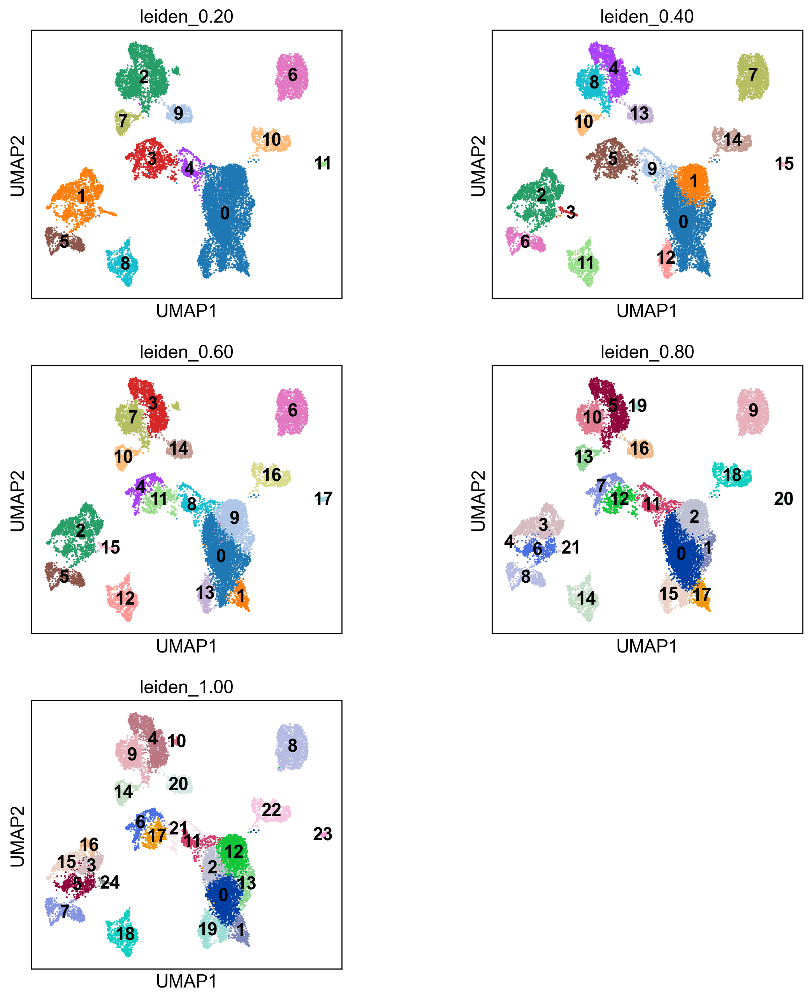

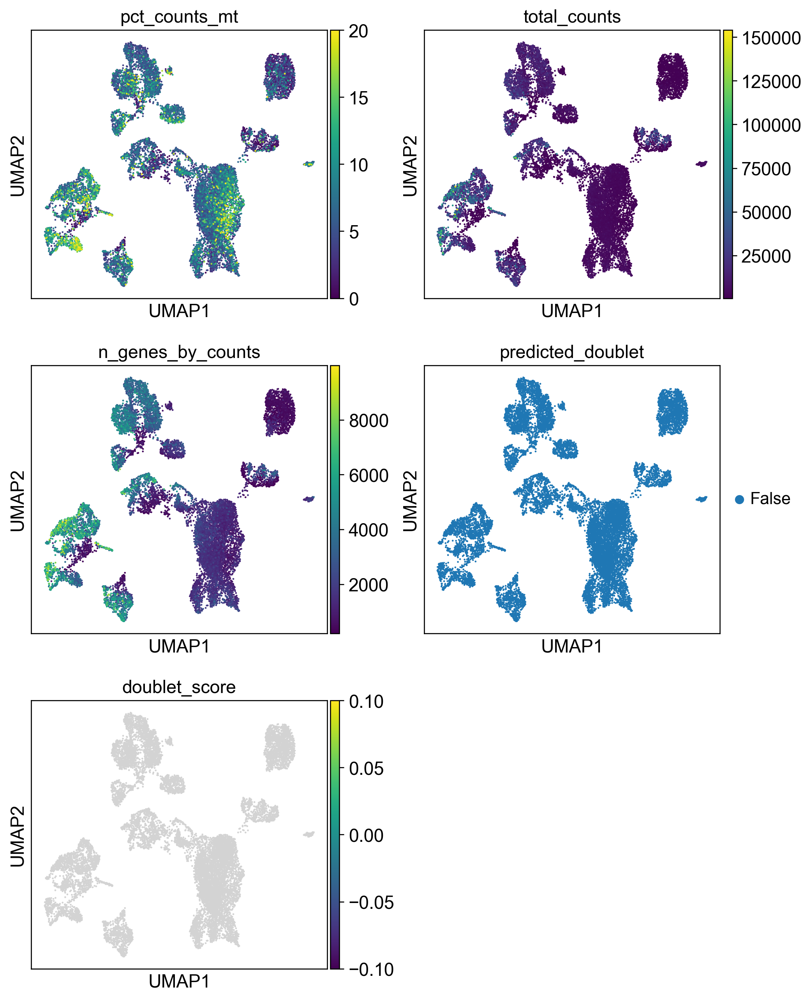

In [36]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [37]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.60"
TOP_N_MARKERS = 15

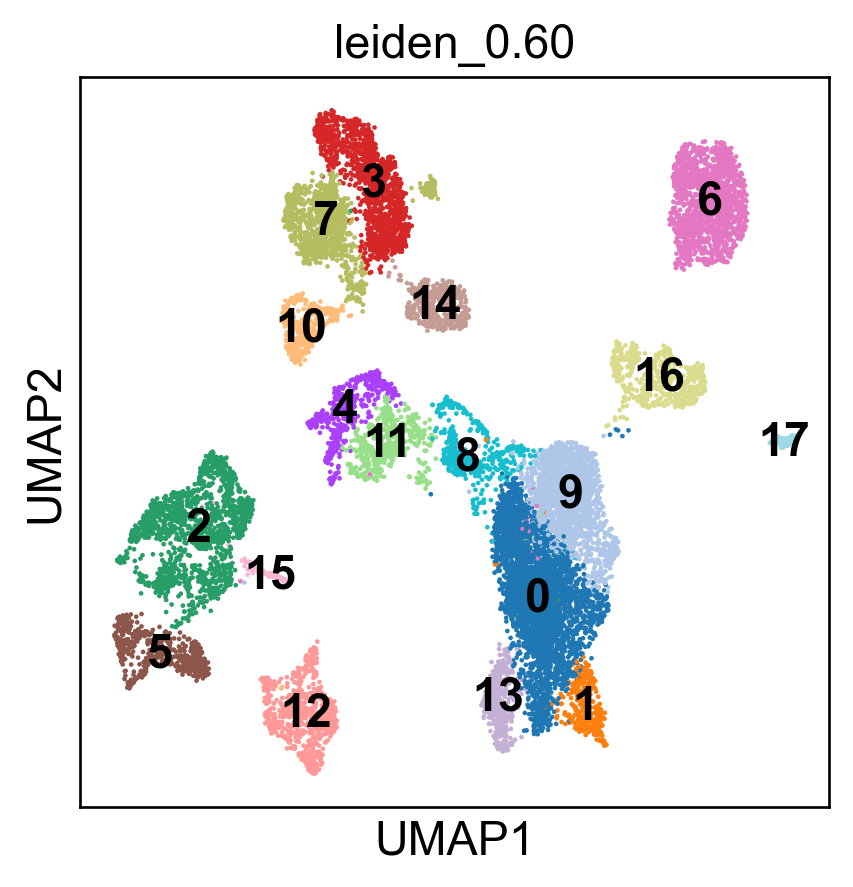

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:12)


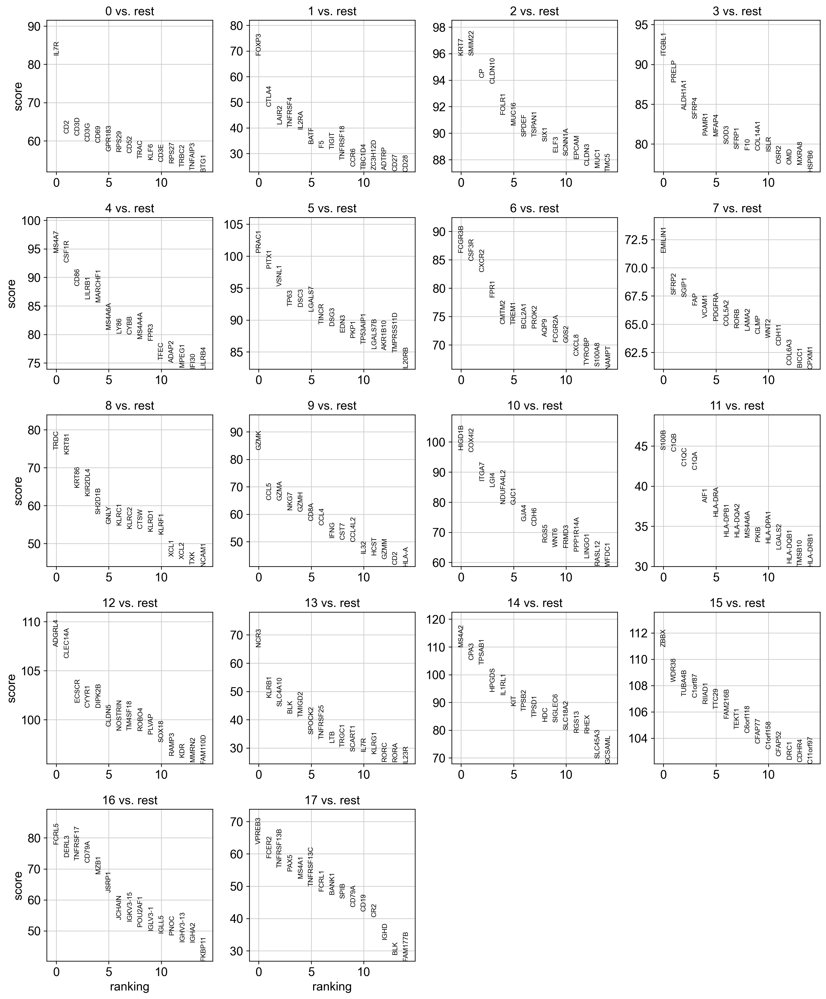

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.60']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
rank_1,IL7R,FOXP3,KRT7,ITGBL1,MS4A7,PRAC1,FCGR3B,EMILIN1,TRDC,GZMK,HIGD1B,S100B,ADGRL4,NCR3,MS4A2,ZBBX,FCRL5,VPREB3
rank_2,CD2,CTLA4,SMIM22,PRELP,CSF1R,PITX1,CSF3R,SFRP2,KRT81,CCL5,COX4I2,C1QB,CLEC14A,KLRB1,CPA3,WDR38,DERL3,FCER2
rank_3,CD3D,LAIR2,CP,ALDH1A1,CD86,VSNL1,CXCR2,SGIP1,KRT86,GZMA,ITGA7,C1QC,ECSCR,SLC4A10,TPSAB1,TUBA4B,TNFRSF17,TNFRSF13B
rank_4,CD3G,TNFRSF4,CLDN10,SFRP4,LILRB1,TP63,FPR1,FAP,KIR2DL4,NKG7,LGI4,C1QA,CYYR1,BLK,HPGDS,C1orf87,CD79A,PAX5
rank_5,CD69,IL2RA,FOLR1,PAMR1,MARCHF1,DSC3,CMTM2,VCAM1,SH2D1B,GZMH,NDUFA4L2,AIF1,DIPK2B,TMIGD2,IL1RL1,RIIAD1,MZB1,MS4A1
rank_6,GPR183,BATF,MUC16,MFAP4,MS4A6A,LGALS7,TREM1,PDGFRA,GNLY,CD8A,GJC1,HLA-DRA,CLDN5,SPOCK2,KIT,TTC29,JSRP1,TNFRSF13C
rank_7,RPS29,F5,SPDEF,SOD3,LY86,TINCR,BCL2A1,COL5A2,KLRC1,CCL4,GJA4,HLA-DPB1,NOSTRIN,TNFRSF25,TPSB2,FAM216B,JCHAIN,FCRL1
rank_8,CD52,TIGIT,TSPAN1,SFRP1,CYBB,DSG3,PROK2,RORB,KLRC2,IFNG,CDH6,HLA-DQA2,TM4SF18,LTB,TPSD1,TEKT1,IGKV3-15,BANK1
rank_9,TRAC,TNFRSF18,SIX1,F10,MS4A4A,EDN3,AQP9,LAMA2,CTSW,CST7,RGS5,MS4A6A,ROBO4,TRGC1,HDC,C6orf118,POU2AF1,SPIB
rank_10,KLF6,CCR6,ELF3,COL14A1,FPR3,PKP1,FCGR2A,CLMP,KLRD1,CCL4L2,WNT6,PKIB,PLVAP,SCART1,SIGLEC6,CFAP77,IGLV3-1,CD79A


In [38]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [39]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "T cells (IL7R+; likely CD4 memory/activated)",
    "1": "Regulatory T cells (Treg)",
    "2": "Endocervical epithelial cells (columnar/secretory)",
    "3": "Fibroblasts (matrix/homeostatic)",
    "4": "Monocytes/macrophages",
    "5": "Squamous epithelial cells",
    "6": "Neutrophils",
    "7": "Fibroblasts (activated/ECM-remodeling)",
    "8": "γδ T cells",
    "9": "Cytotoxic T cells (CD8-like)",
    "10": "Pericytes",
    "11": "C1Q+ macrophages",
    "12": "Endothelial cells",
    "13": "ILC3-like innate lymphoid cells",
    "14": "Mast cells",
    "15": "Ciliated epithelial cells",
    "16": "Plasma cells",
    "17": "B cells"
}

In [40]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360682_N_1__celltype_mapping.tsv.gz
                                                             cell_id       sample_id leiden_0.60                                          cell_type
GSM6360682_N_1_AAACCCAAGCGACTGA-1  GSM6360682_N_1_AAACCCAAGCGACTGA-1  GSM6360682_N_1           0       T cells (IL7R+; likely CD4 memory/activated)
GSM6360682_N_1_AAACCCAAGCGTGAAC-1  GSM6360682_N_1_AAACCCAAGCGTGAAC-1  GSM6360682_N_1           2  Endocervical epithelial cells (columnar/secret...
GSM6360682_N_1_AAACCCAAGTCTAACC-1  GSM6360682_N_1_AAACCCAAGTCTAACC-1  GSM6360682_N_1           3                   Fibroblasts (matrix/homeostatic)
GSM6360682_N_1_AAACCCAAGTCTACCA-1  GSM6360682_N_1_AAACCCAAGTCTACCA-1  GSM6360682_N_1           3                   Fibroblasts (matrix/homeostatic)
GSM6360682_N_1_AAACCCAAGTCTGCGC-1  GSM6360682_N_1_AAACCCAAGTCTGCGC-1  GSM6360682_N_1           2  E

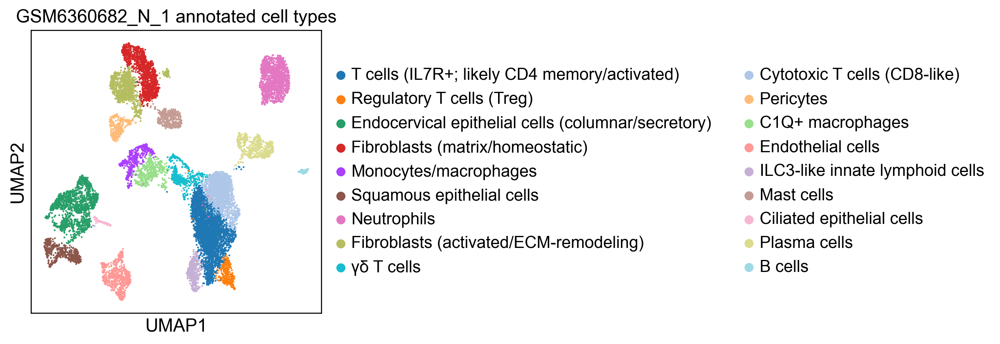

In [41]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360683_N_2

In [4]:
sample_id = "GSM6360683_N_2"

AnnData object with n_obs × n_vars = 7335 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3937 genes that are detected in less than 3 cells


,suggested_value
min_counts,1088.00
max_counts,31047.00
min_genes,641.00
max_genes,6282.00
max_pct_mt,14.66


QC plots for GSM6360683_N_2
normalizing counts per cell
    finished (0:00:00)


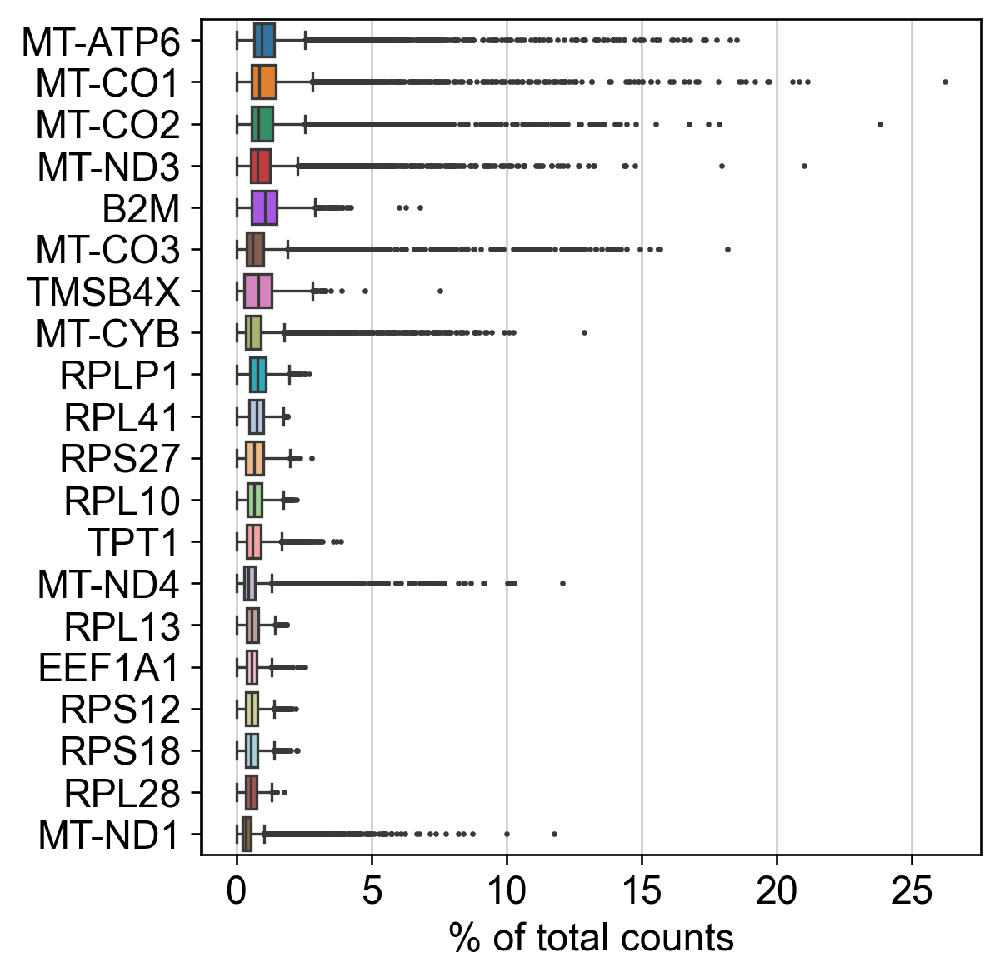

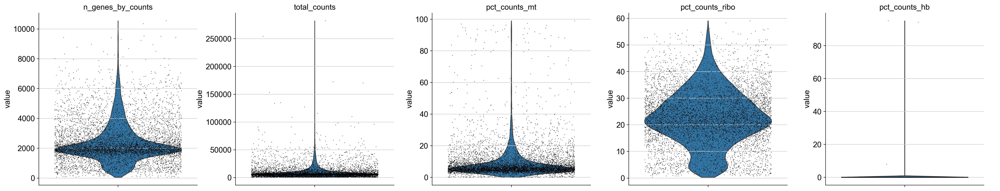

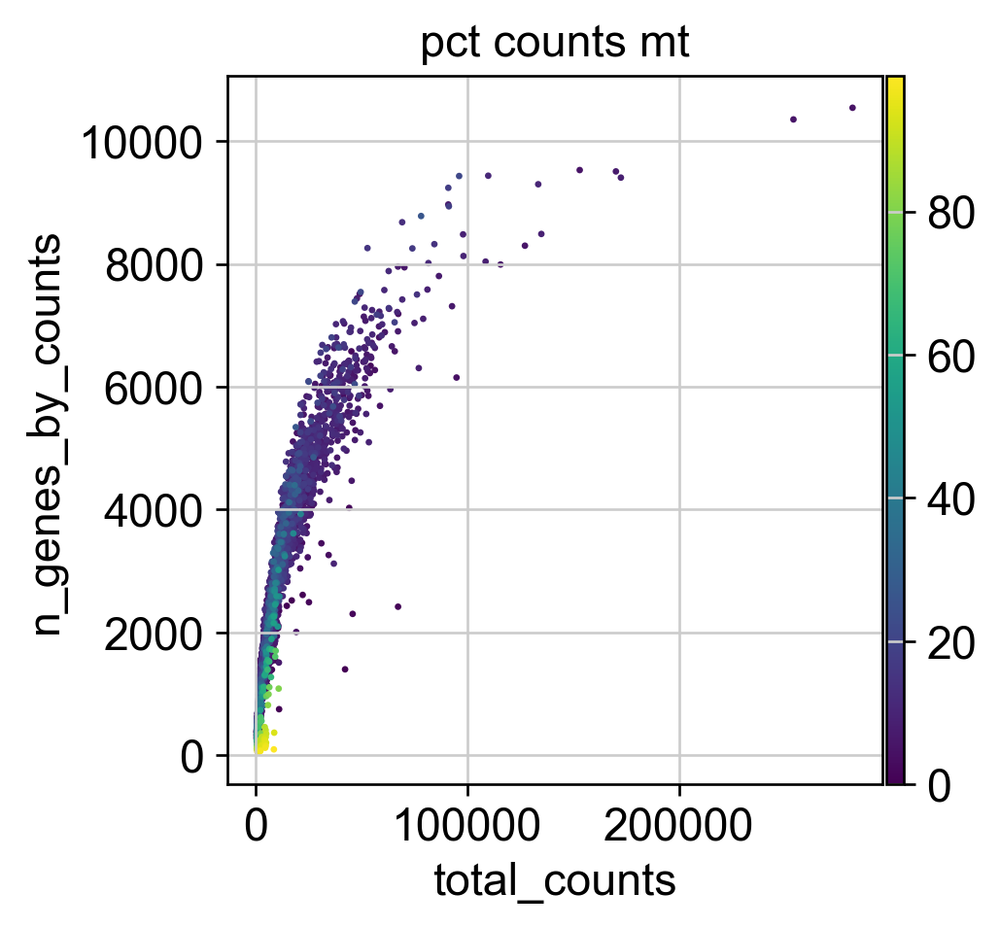

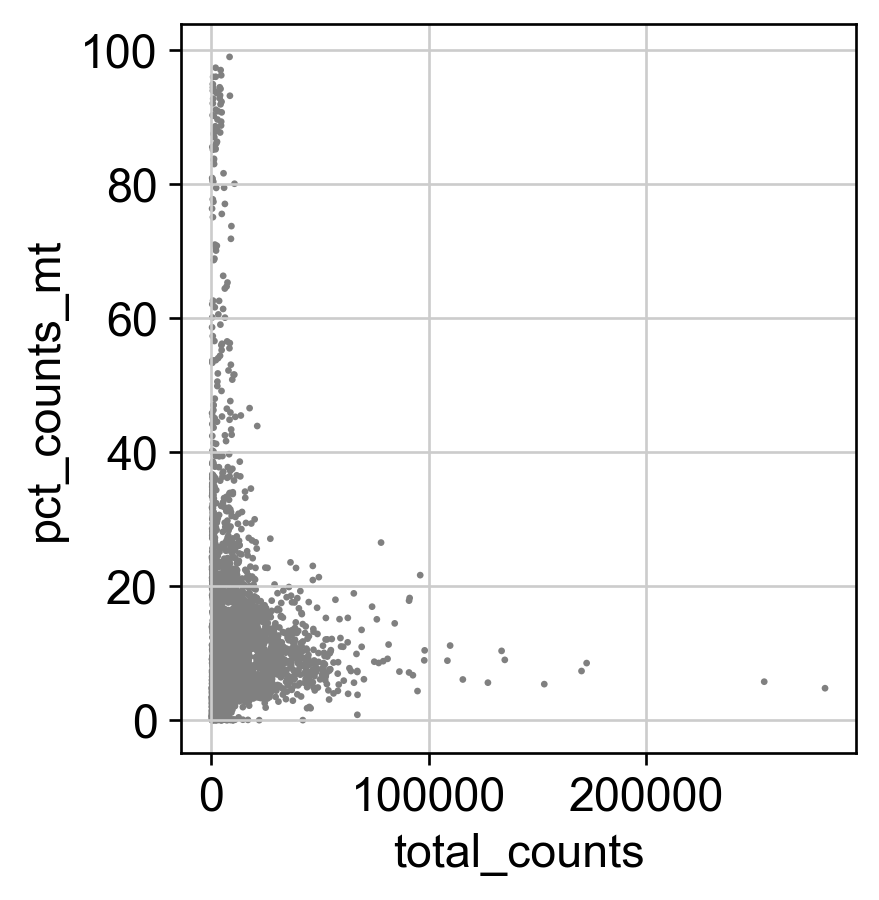

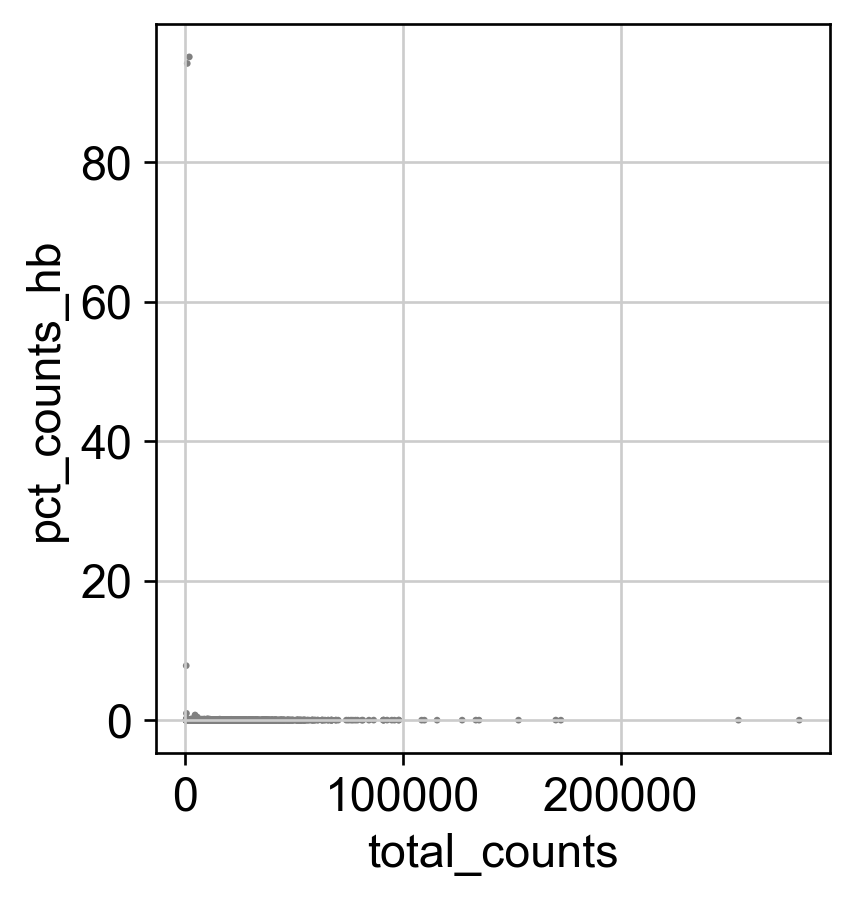

In [5]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [6]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 1000,
    "min_genes": 600,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3937 genes that are detected in less than 3 cells
Cells before QC: 7335
Cells after QC : 6580
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_80533/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


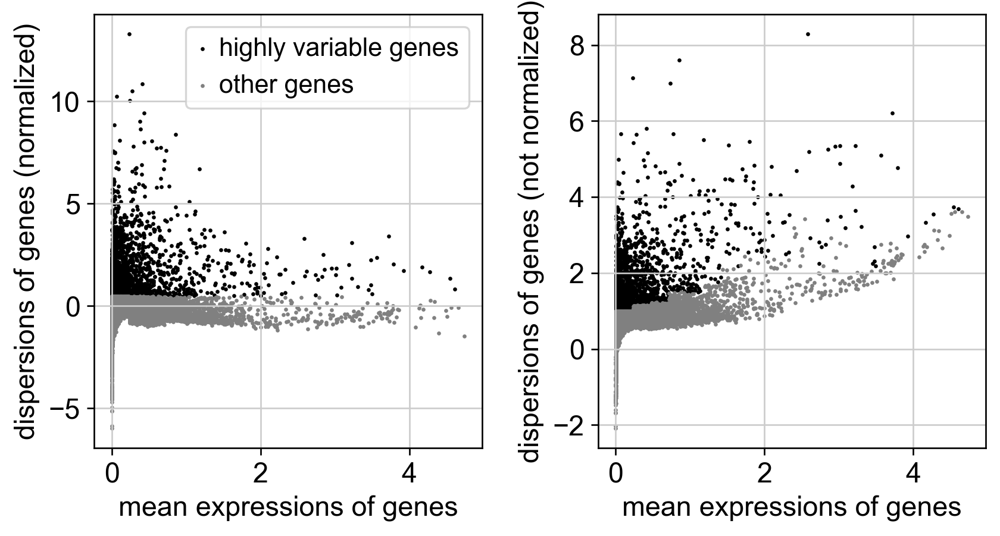

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:00)


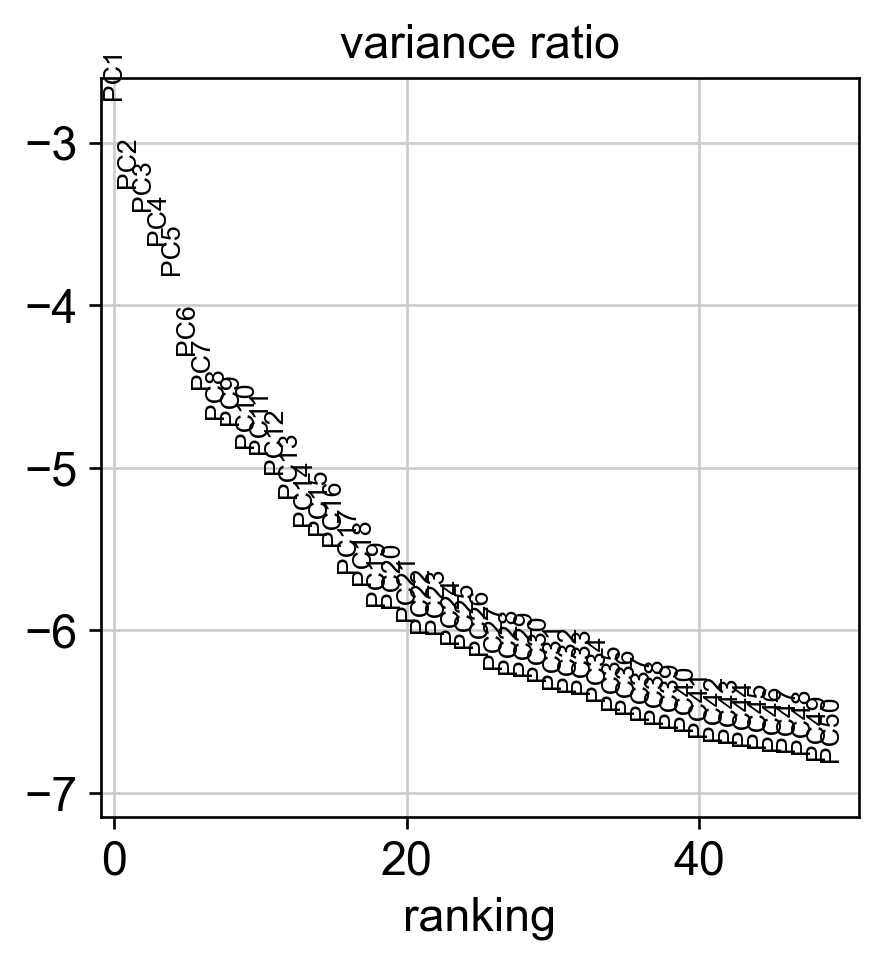

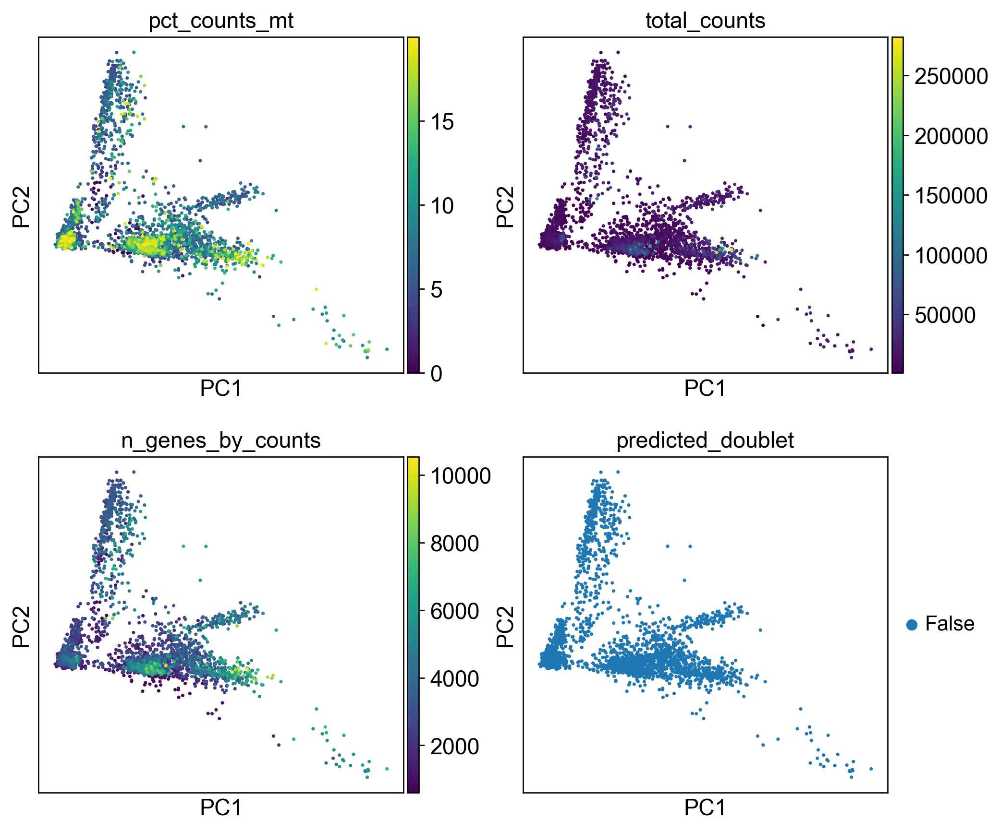

In [7]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [8]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 50
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 50


$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:08)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 12 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 17 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 22 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden clustering
    finished: found 25 clusters and added
    'le

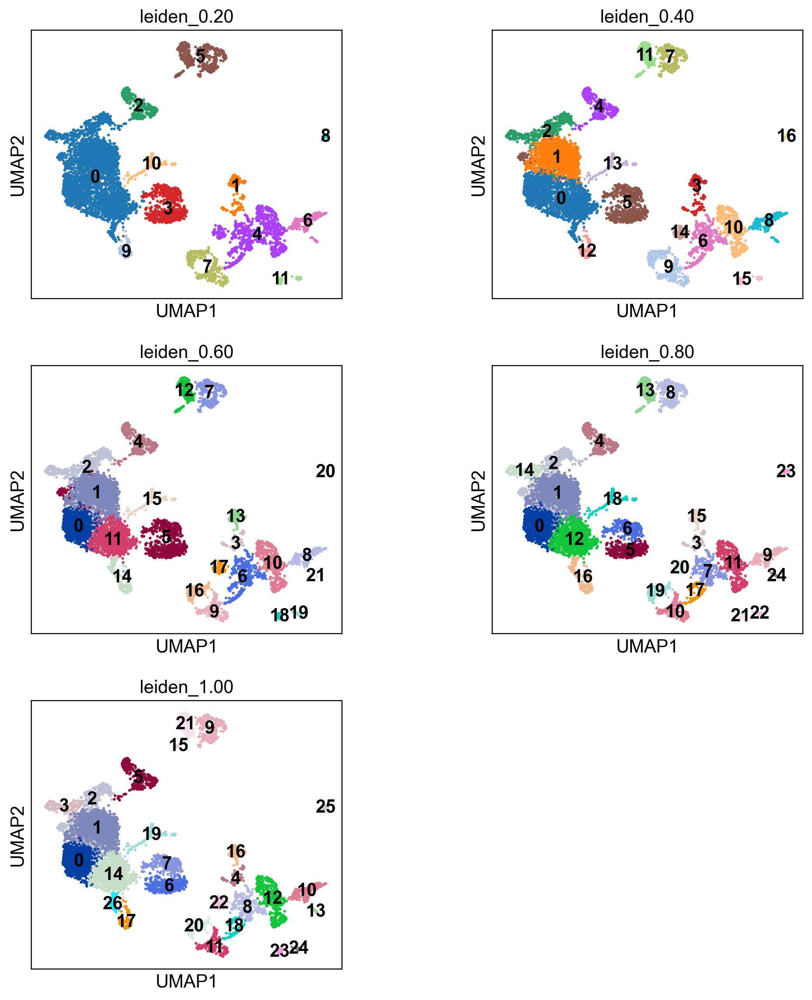

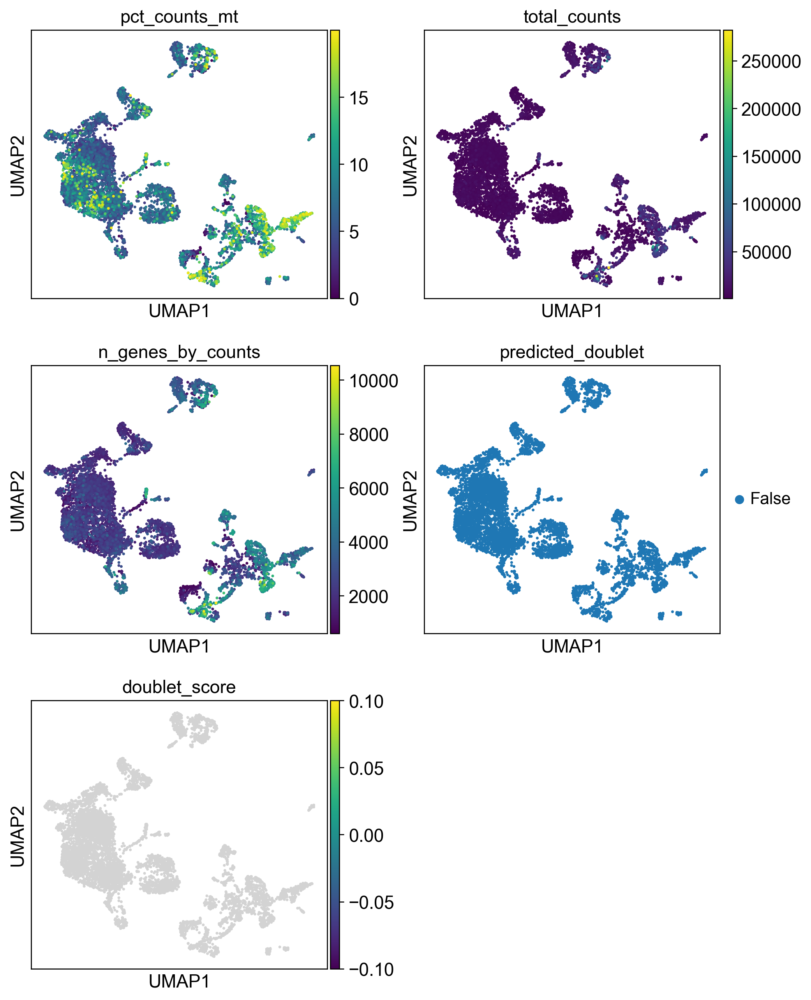

In [9]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [10]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.40"
TOP_N_MARKERS = 15

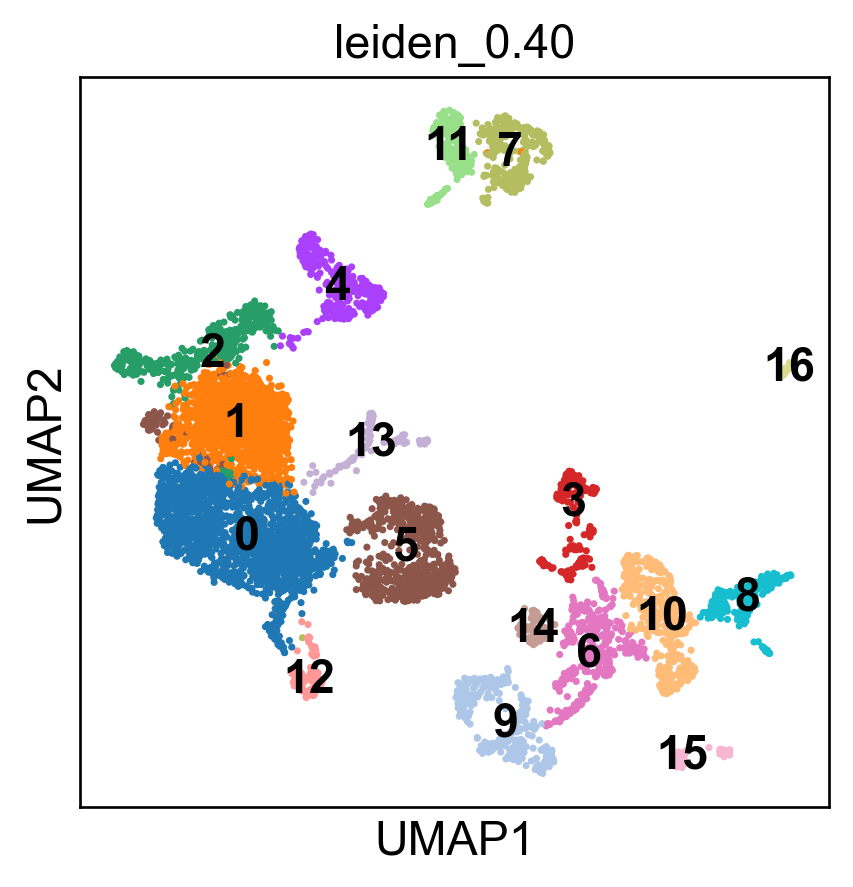

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.40']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:05)


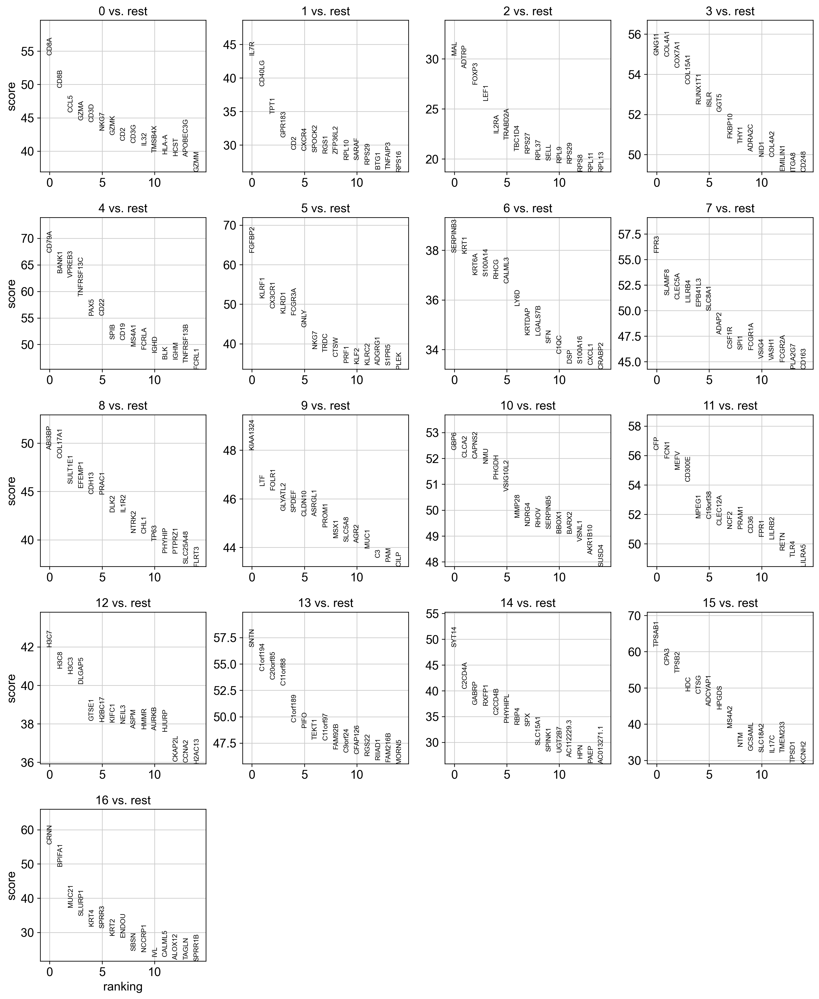

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.40']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
rank_1,CD8A,IL7R,MAL,GNG11,CD79A,FGFBP2,SERPINB3,FPR3,ABI3BP,KIAA1324,GBP6,CFP,H3C7,SNTN,SYT14,TPSAB1,CRNN
rank_2,CD8B,CD40LG,ADTRP,COL4A1,BANK1,KLRF1,KRT1,SLAMF8,COL17A1,LTF,CLCA2,FCN1,H3C8,C1orf194,C2CD4A,CPA3,BPIFA1
rank_3,CCL5,TPT1,FOXP3,COX7A1,VPREB3,CX3CR1,KRT6A,CLEC5A,SULT1E1,FOLR1,CAPNS2,MEFV,H3C3,C20orf85,GABRP,TPSB2,MUC21
rank_4,GZMA,GPR183,LEF1,COL15A1,TNFRSF13C,KLRD1,S100A14,LILRB4,EFEMP1,GLYATL2,NMU,CD300E,DLGAP5,C11orf88,RXFP1,HDC,SLURP1
rank_5,CD3D,CD2,IL2RA,RUNX1T1,PAX5,FCGR3A,RHCG,EPB41L3,CDH13,SPDEF,PHGDH,MPEG1,GTSE1,C1orf189,C2CD4B,CTSG,KRT4
rank_6,NKG7,CXCR4,TRABD2A,ISLR,CD22,GNLY,CALML3,SLC8A1,PRAC1,CLDN10,VSIG10L2,C19orf38,H2BC17,PIFO,PHYHIPL,ADCYAP1,SPRR3
rank_7,GZMK,SPOCK2,TBC1D4,GGT5,SPIB,NKG7,LY6D,ADAP2,DLK2,ASRGL1,MMP28,CLEC12A,KIFC1,TEKT1,RBP4,HPGDS,KRT2
rank_8,CD2,RGS1,RPS27,FKBP10,CD19,TRDC,KRTDAP,CSF1R,IL1R2,PROM1,NDRG4,NCF2,NEIL3,C11orf97,SPX,MS4A2,ENDOU
rank_9,CD3G,ZFP36L2,RPL37,THY1,MS4A1,CTSW,LGALS7B,SPI1,NTRK2,MSX1,RHOV,PRAM1,ASPM,FAM92B,SLC15A1,NTM,SBSN
rank_10,IL32,RPL10,SELL,ADRA2C,FCRLA,PRF1,SFN,FCGR1A,CHL1,SLC5A8,SERPINB5,CD36,HMMR,C9orf24,SPINK1,GCSAML,NCCRP1


In [11]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [13]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "CD8 T cells",
    "1": "CD4 T cells",
    "2": "Regulatory T cells",
    "3": "Fibroblasts",
    "4": "B cells",
    "5": "NK cells",
    "6": "Squamous epithelial cells",
    "7": "Myeloid cells",
    "8": "Epithelial cells",
    "9": "Glandular epithelial cells",
    "10": "Epithelial cells",
    "11": "Myeloid cells",
    "12": "Cycling cells",
    "13": "Ciliated epithelial cells",
    "14": "Secretory epithelial cells",
    "15": "Mast cells",
    "16": "Squamous epithelial cells"
}

In [14]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360683_N_2__celltype_mapping.tsv.gz
                                                             cell_id       sample_id leiden_0.40           cell_type
GSM6360683_N_2_AAACCCAAGAGCAGTC-1  GSM6360683_N_2_AAACCCAAGAGCAGTC-1  GSM6360683_N_2           0         CD8 T cells
GSM6360683_N_2_AAACCCACAACTCCAA-1  GSM6360683_N_2_AAACCCACAACTCCAA-1  GSM6360683_N_2           1         CD4 T cells
GSM6360683_N_2_AAACCCACACCAGCCA-1  GSM6360683_N_2_AAACCCACACCAGCCA-1  GSM6360683_N_2           1         CD4 T cells
GSM6360683_N_2_AAACCCAGTGATACTC-1  GSM6360683_N_2_AAACCCAGTGATACTC-1  GSM6360683_N_2           2  Regulatory T cells
GSM6360683_N_2_AAACCCAGTTTAGACC-1  GSM6360683_N_2_AAACCCAGTTTAGACC-1  GSM6360683_N_2           3         Fibroblasts


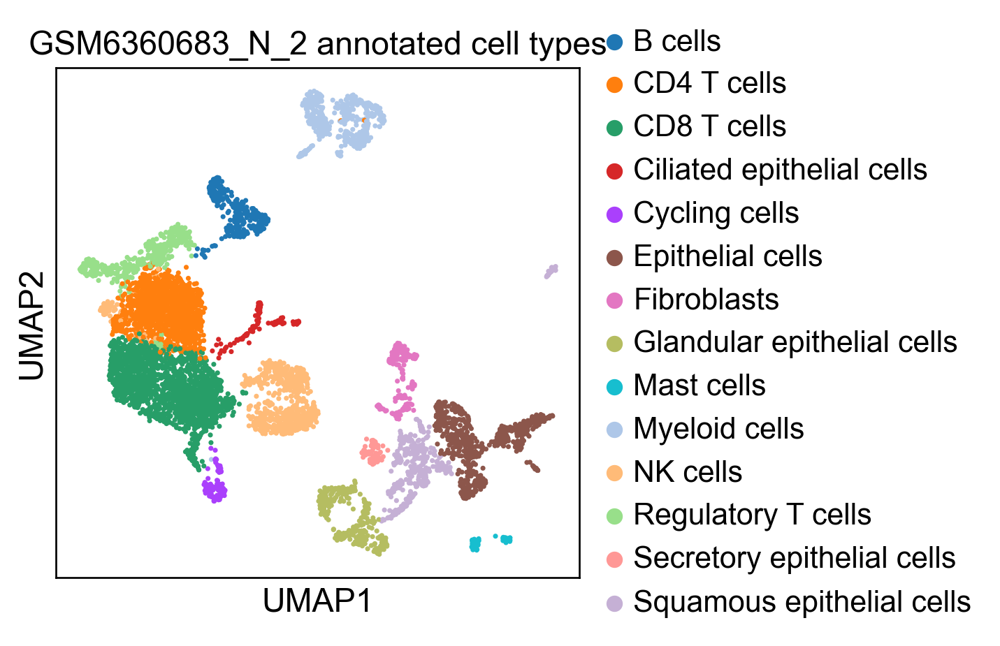

In [15]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360684_HSIL_1

In [16]:
sample_id = "GSM6360684_HSIL_1"

AnnData object with n_obs × n_vars = 6346 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3734 genes that are detected in less than 3 cells


,suggested_value
min_counts,226.00
max_counts,44987.00
min_genes,229.00
max_genes,8658.00
max_pct_mt,15.37


QC plots for GSM6360684_HSIL_1
normalizing counts per cell
    finished (0:00:00)


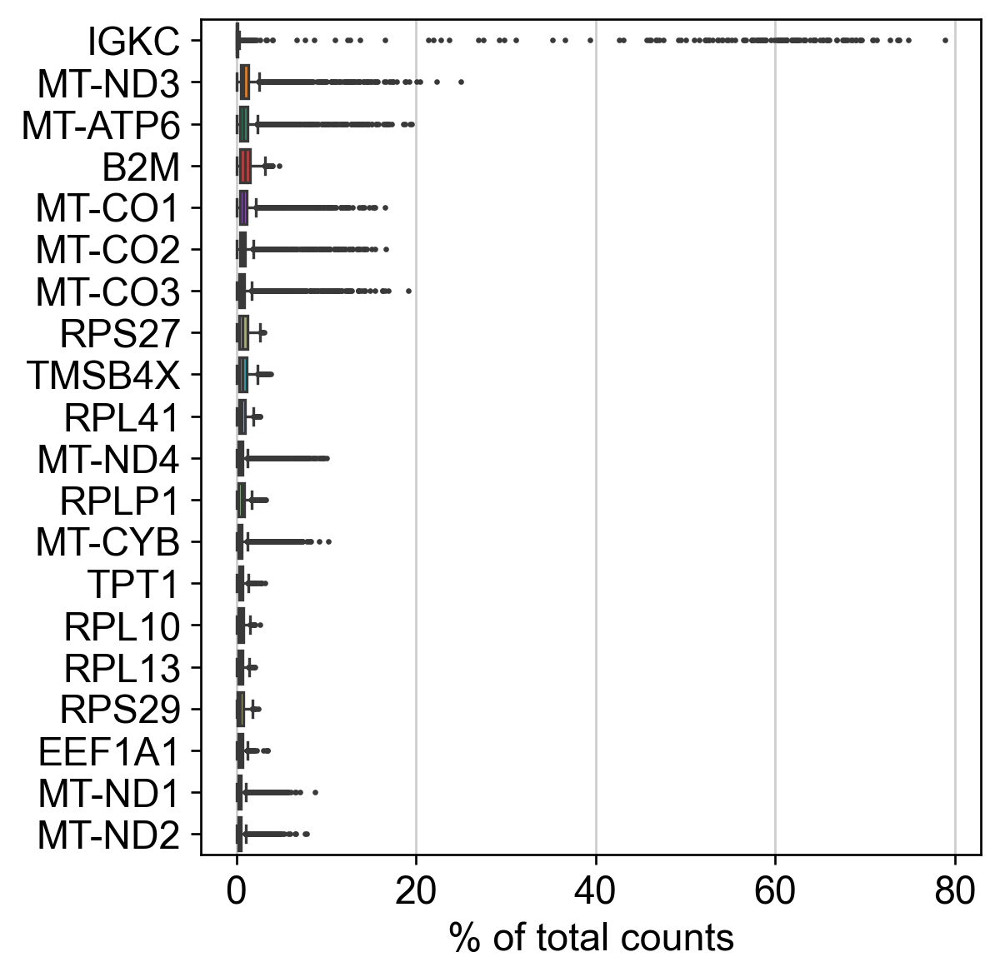

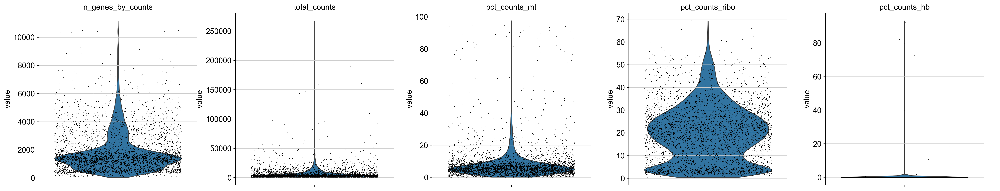

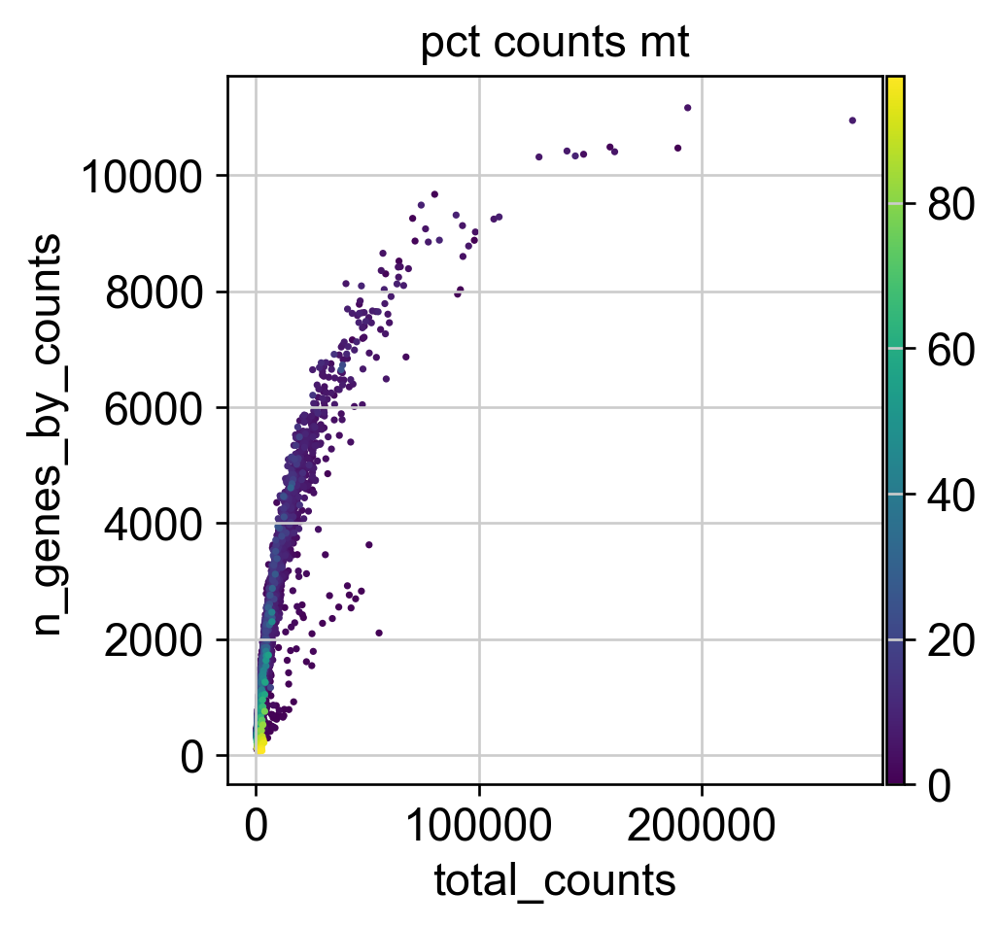

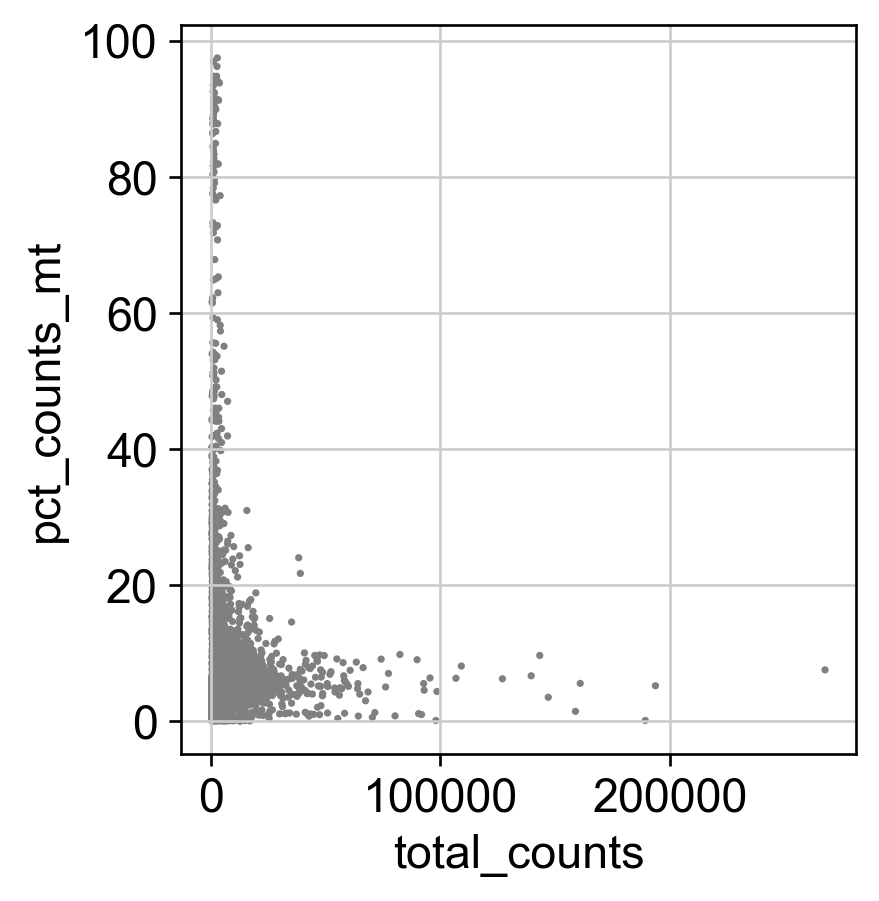

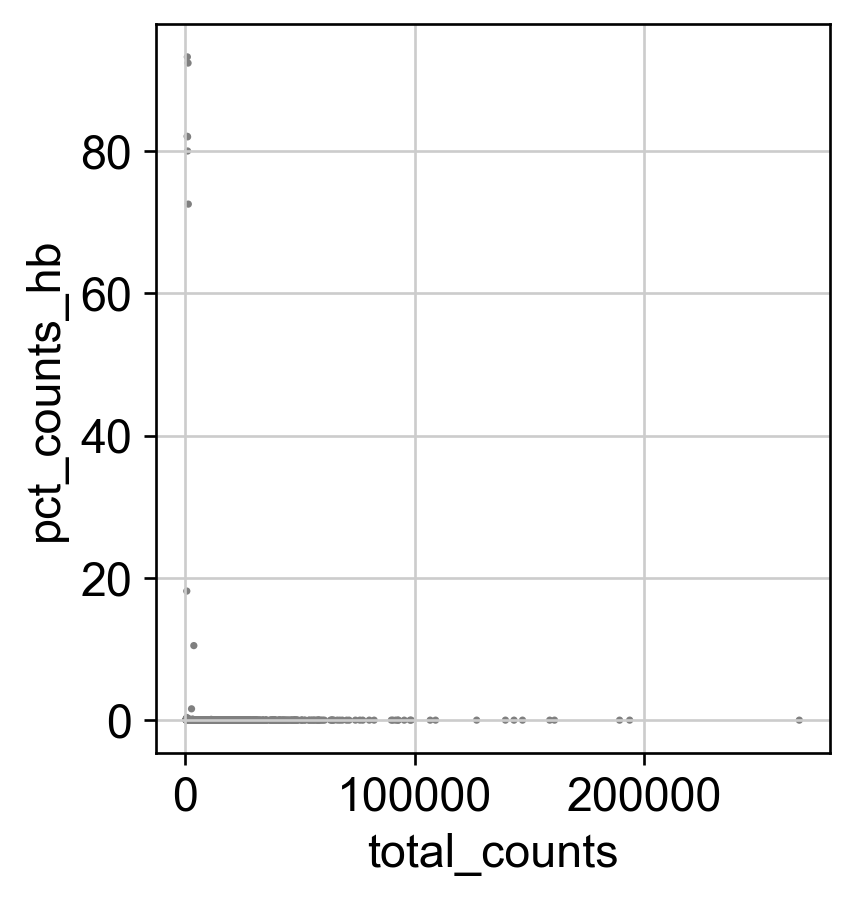

In [17]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [18]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3734 genes that are detected in less than 3 cells
Cells before QC: 6346
Cells after QC : 5969
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_80533/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


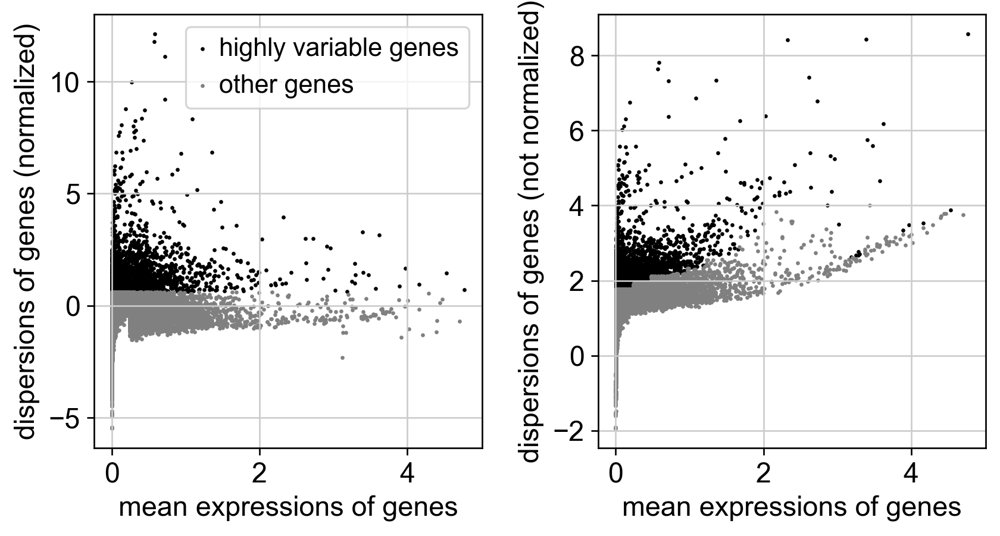

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


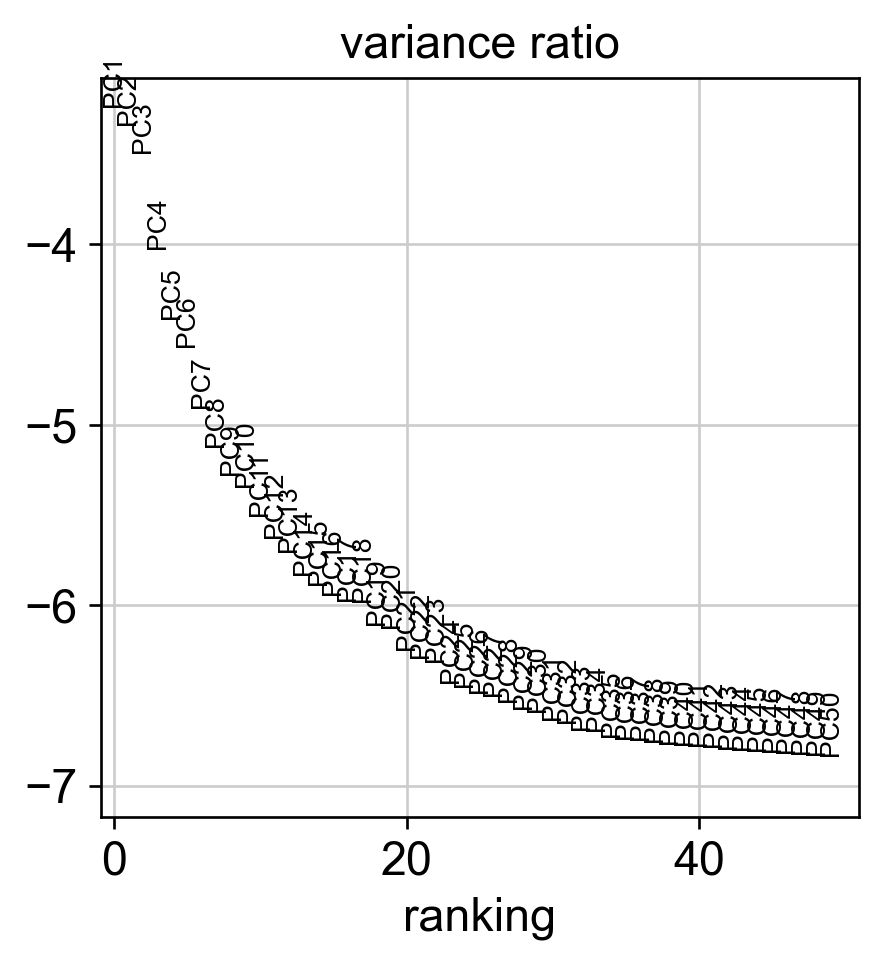

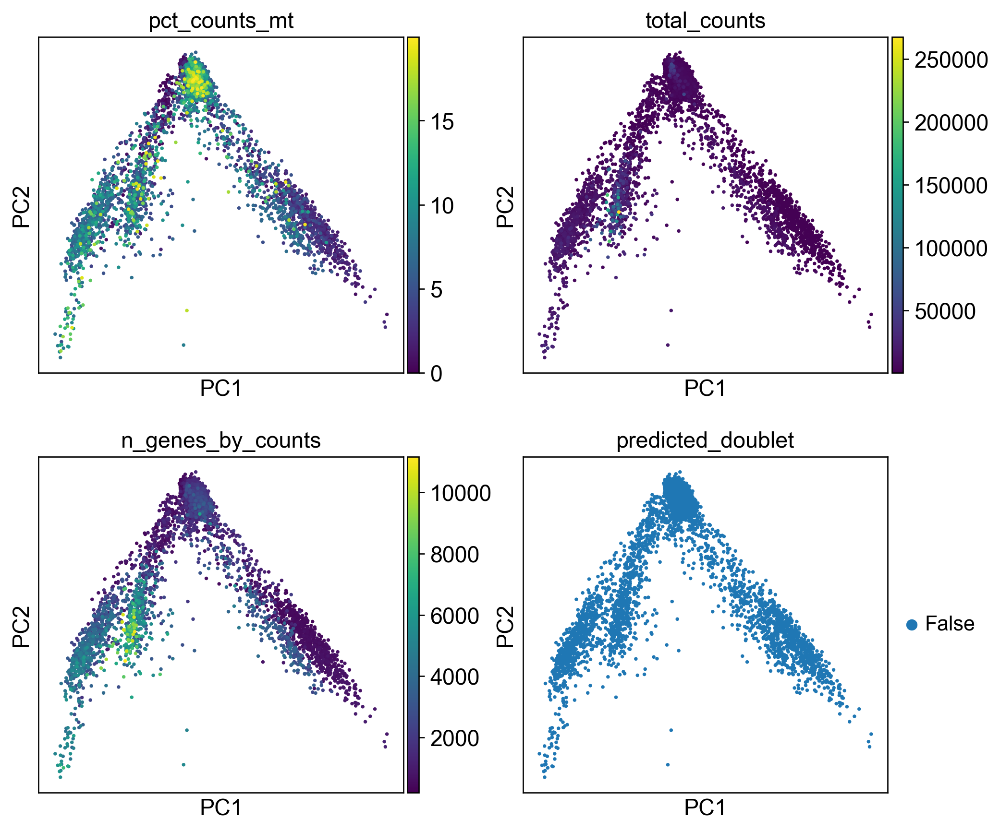

In [19]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [20]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 38
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 38
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:07)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 13 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 15 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 17 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden cluste

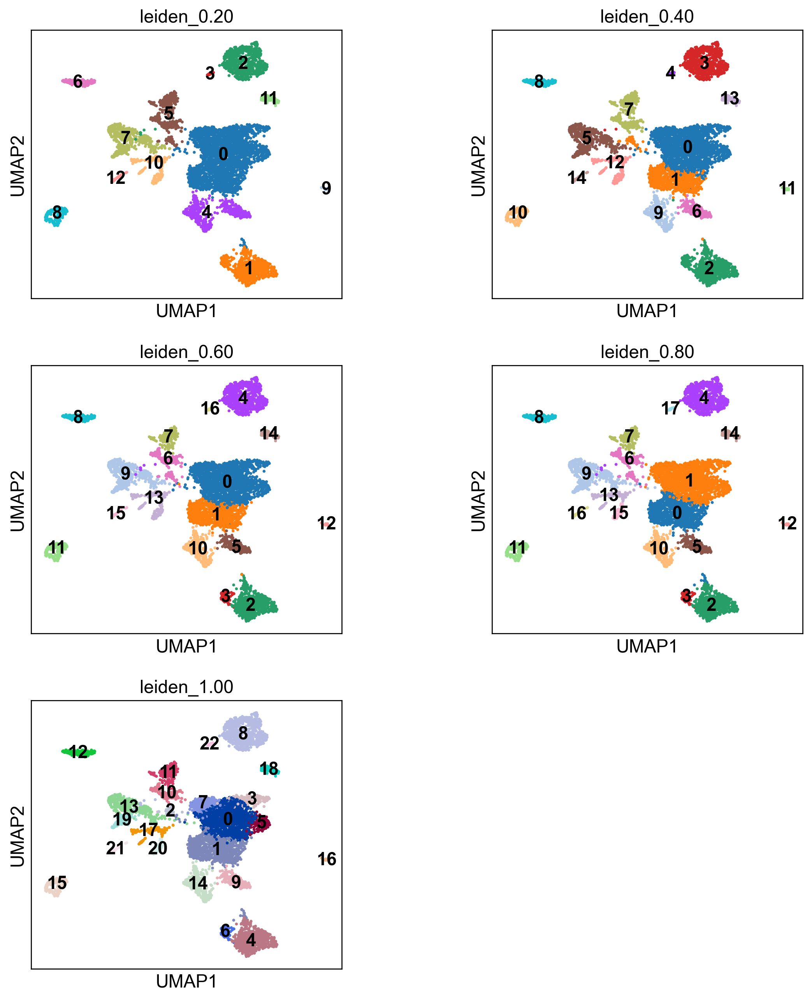

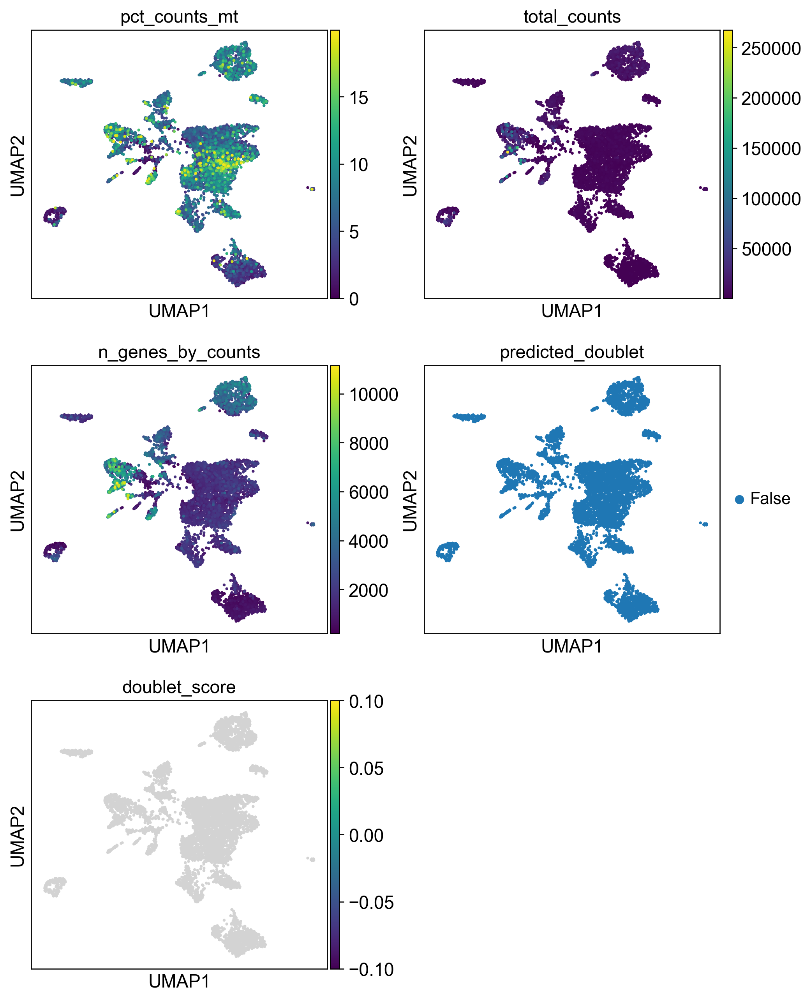

In [21]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [22]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.60"
TOP_N_MARKERS = 15

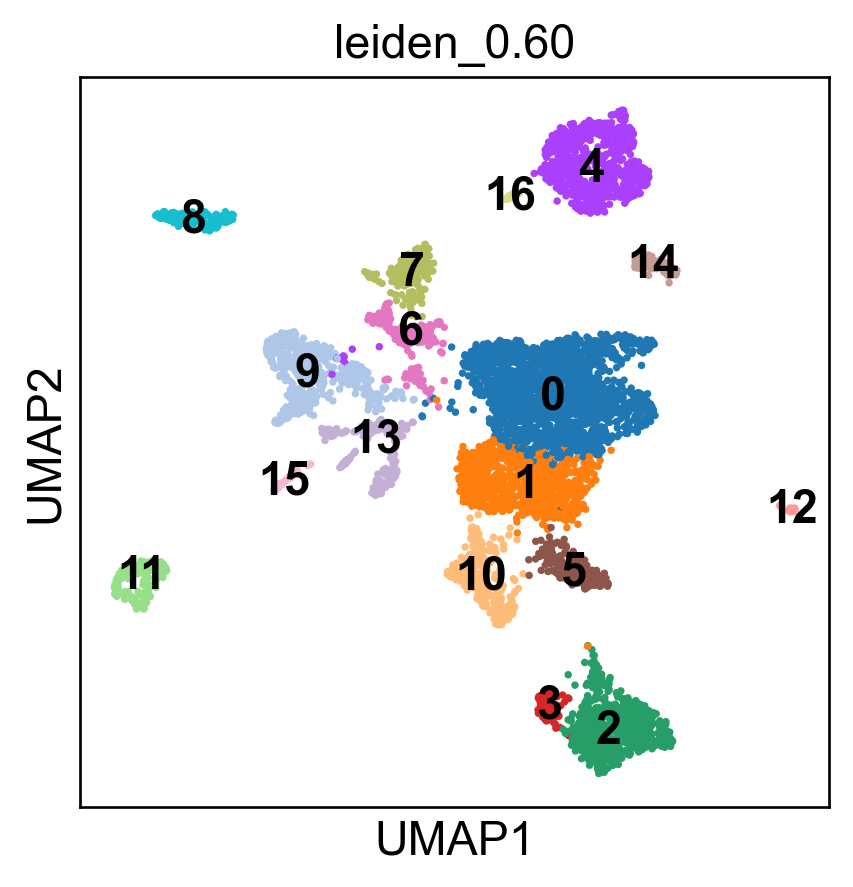

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:04)


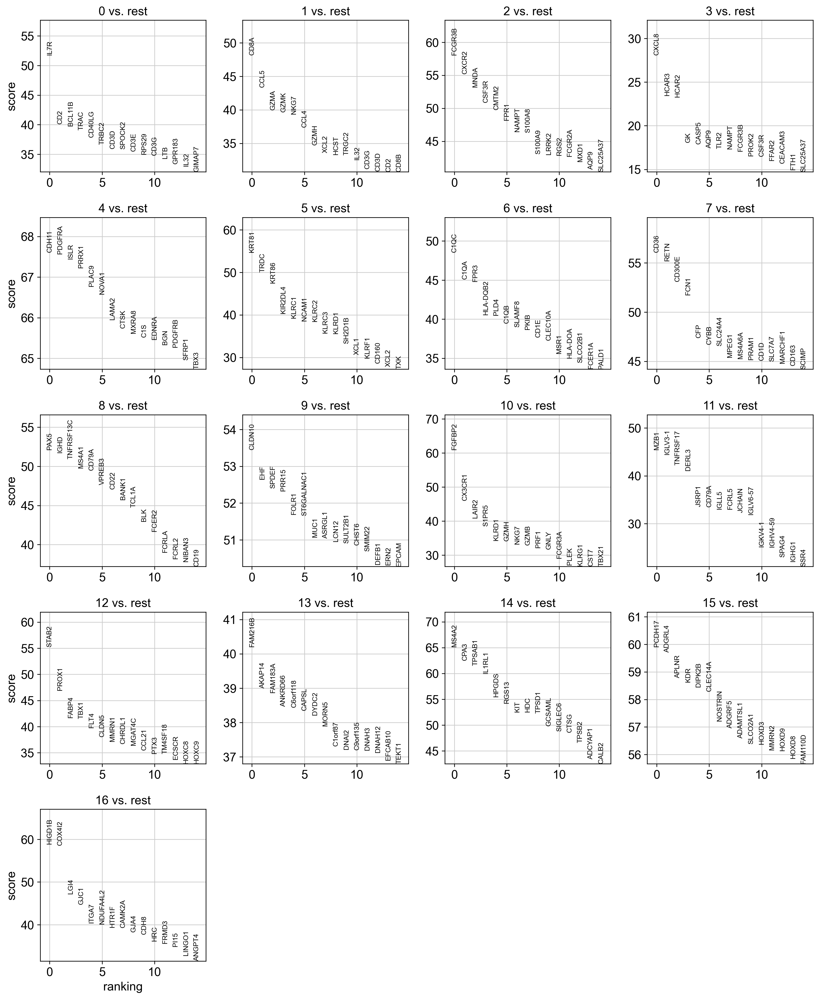

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.60']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
rank_1,IL7R,CD8A,FCGR3B,CXCL8,CDH11,KRT81,C1QC,CD36,PAX5,CLDN10,FGFBP2,MZB1,STAB2,FAM216B,MS4A2,PCDH17,HIGD1B
rank_2,CD2,CCL5,CXCR2,HCAR3,PDGFRA,TRDC,C1QA,RETN,IGHD,EHF,CX3CR1,IGLV3-1,PROX1,AKAP14,CPA3,ADGRL4,COX4I2
rank_3,BCL11B,GZMA,MNDA,HCAR2,ISLR,KRT86,FPR3,CD300E,TNFRSF13C,SPDEF,LAIR2,TNFRSF17,FABP4,FAM183A,TPSAB1,APLNR,LGI4
rank_4,TRAC,GZMK,CSF3R,GK,PRRX1,KIR2DL4,HLA-DQB2,FCN1,MS4A1,PRR15,S1PR5,DERL3,TBX1,ANKRD66,IL1RL1,KDR,GJC1
rank_5,CD40LG,NKG7,CMTM2,CASP5,PLAC9,KLRC1,PLD4,CFP,CD79A,FOLR1,KLRD1,JSRP1,FLT4,C6orf118,HPGDS,DIPK2B,ITGA7
rank_6,TRBC2,CCL4,FPR1,AQP9,NOVA1,NCAM1,C1QB,CYBB,VPREB3,ST6GALNAC1,GZMH,CD79A,CLDN5,CAPSL,RGS13,CLEC14A,NDUFA4L2
rank_7,CD3D,GZMH,NAMPT,TLR2,LAMA2,KLRC2,SLAMF8,SLC24A4,CD22,MUC1,NKG7,IGLL5,MMRN1,DYDC2,KIT,NOSTRIN,HTR1F
rank_8,SPOCK2,XCL2,S100A8,NAMPT,CTSK,KLRC3,PKIB,MPEG1,BANK1,ASRGL1,GZMB,FCRL5,CHRDL1,MORN5,HDC,ADGRF5,CAMK2A
rank_9,CD3E,HCST,S100A9,FCGR3B,MXRA8,KLRD1,CD1E,MS4A6A,TCL1A,LCN12,PRF1,JCHAIN,MGAT4C,C1orf87,TPSD1,ADAMTSL1,GJA4
rank_10,RPS29,TRGC2,LRRK2,PROK2,C1S,SH2D1B,CLEC10A,PRAM1,BLK,SULT2B1,GNLY,IGLV6-57,CCL21,DNAI2,GCSAML,SLCO2A1,CDH8


In [23]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [25]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "CD4+ T cells",
    "1": "CD8+ cytotoxic T cells",
    "2": "Neutrophils",
    "3": "Activated neutrophils",
    "4": "Fibroblasts",
    "5": "gamma-delta T cells",
    "6": "C1QC+ macrophages",
    "7": "FCN1+ monocytes/macrophages",
    "8": "B cells",
    "9": "Epithelial cells",
    "10": "NK cells",
    "11": "Plasma cells",
    "12": "Lymphatic endothelial cells",
    "13": "Ciliated epithelial cells",
    "14": "Mast cells",
    "15": "Endothelial cells",
    "16": "Pericytes"
}

In [26]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360684_HSIL_1__celltype_mapping.tsv.gz
                                                                   cell_id          sample_id leiden_0.60              cell_type
GSM6360684_HSIL_1_AAACCCAAGACGGTCA-1  GSM6360684_HSIL_1_AAACCCAAGACGGTCA-1  GSM6360684_HSIL_1           0           CD4+ T cells
GSM6360684_HSIL_1_AAACCCAAGCCAGACA-1  GSM6360684_HSIL_1_AAACCCAAGCCAGACA-1  GSM6360684_HSIL_1           2            Neutrophils
GSM6360684_HSIL_1_AAACCCAAGTATAACG-1  GSM6360684_HSIL_1_AAACCCAAGTATAACG-1  GSM6360684_HSIL_1           0           CD4+ T cells
GSM6360684_HSIL_1_AAACCCACAACTTCTT-1  GSM6360684_HSIL_1_AAACCCACAACTTCTT-1  GSM6360684_HSIL_1           2            Neutrophils
GSM6360684_HSIL_1_AAACCCACACTACACA-1  GSM6360684_HSIL_1_AAACCCACACTACACA-1  GSM6360684_HSIL_1           3  Activated neutrophils


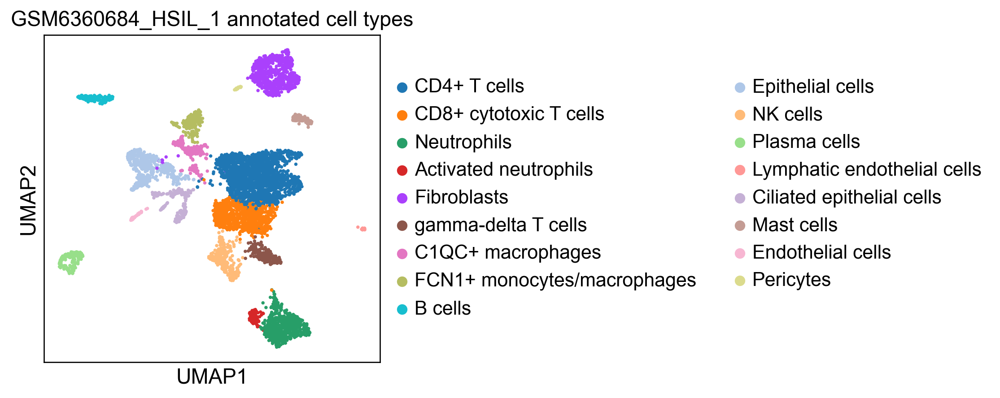

In [27]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360685_HSIL_2

In [28]:
sample_id = "GSM6360685_HSIL_2"

AnnData object with n_obs × n_vars = 7371 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3664 genes that are detected in less than 3 cells


,suggested_value
min_counts,108.0
max_counts,196530.0
min_genes,113.0
max_genes,30999.0
max_pct_mt,13.5


QC plots for GSM6360685_HSIL_2
normalizing counts per cell
    finished (0:00:00)


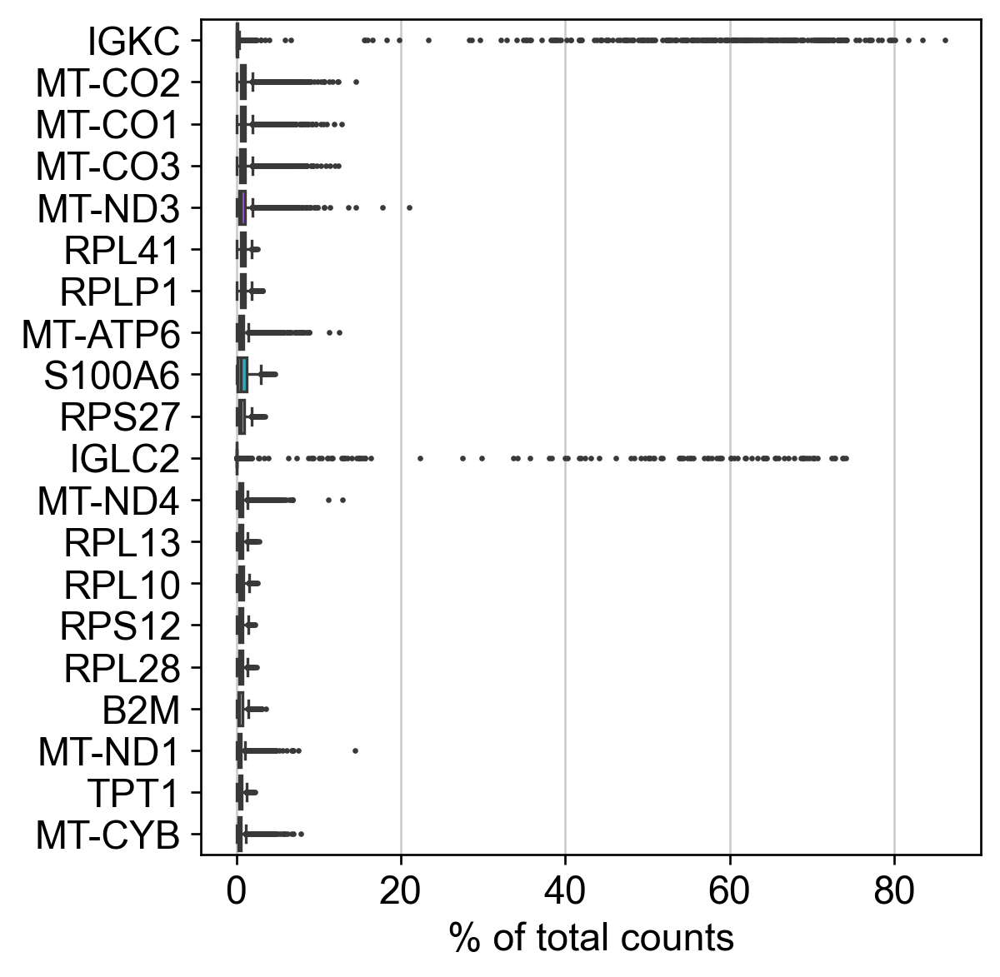

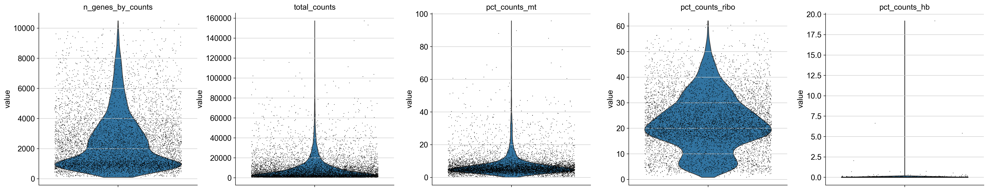

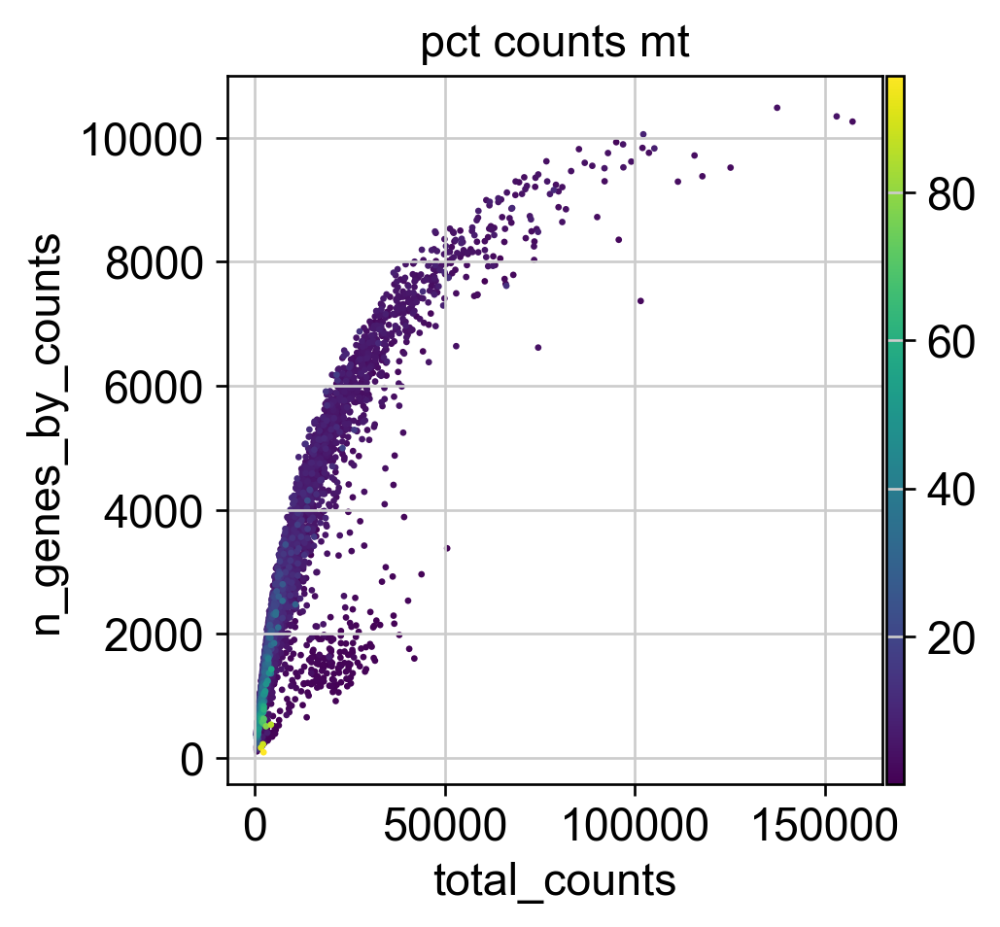

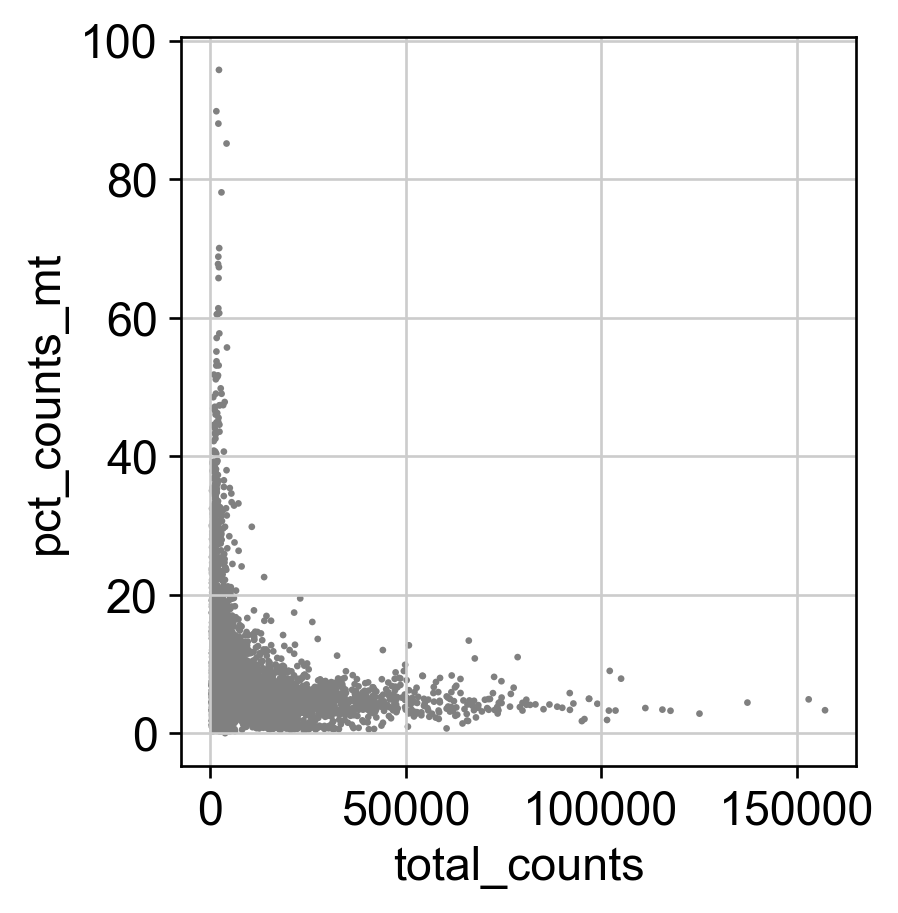

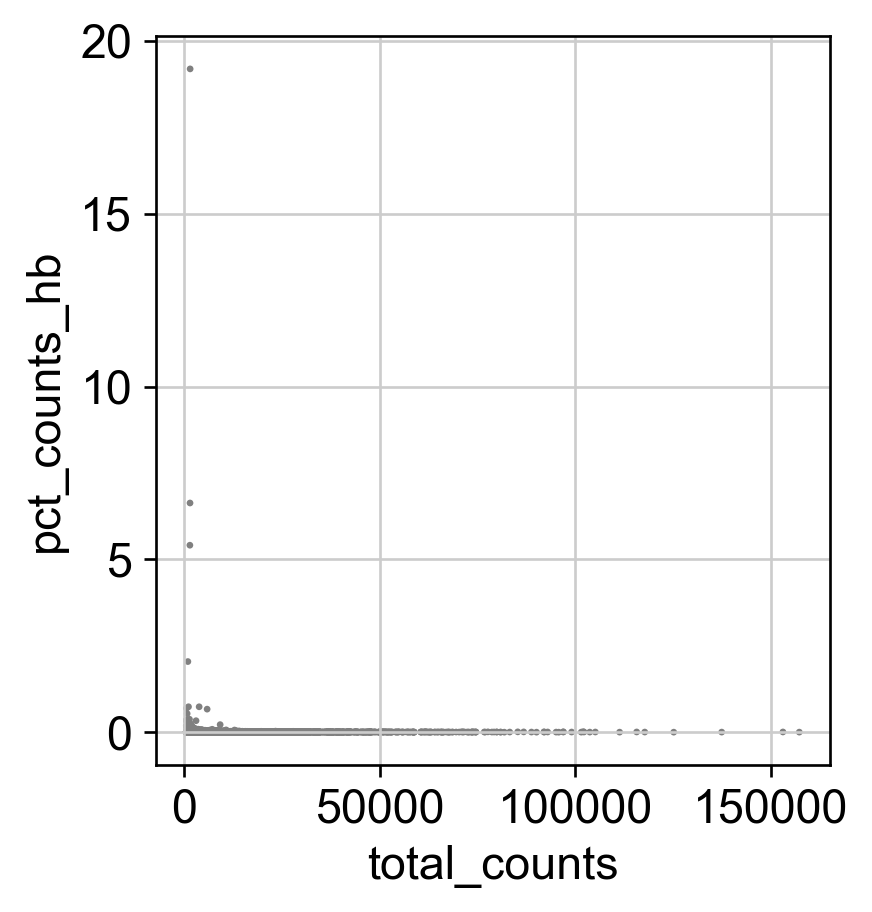

In [29]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [30]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3664 genes that are detected in less than 3 cells
Cells before QC: 7371
Cells after QC : 6982
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_80533/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


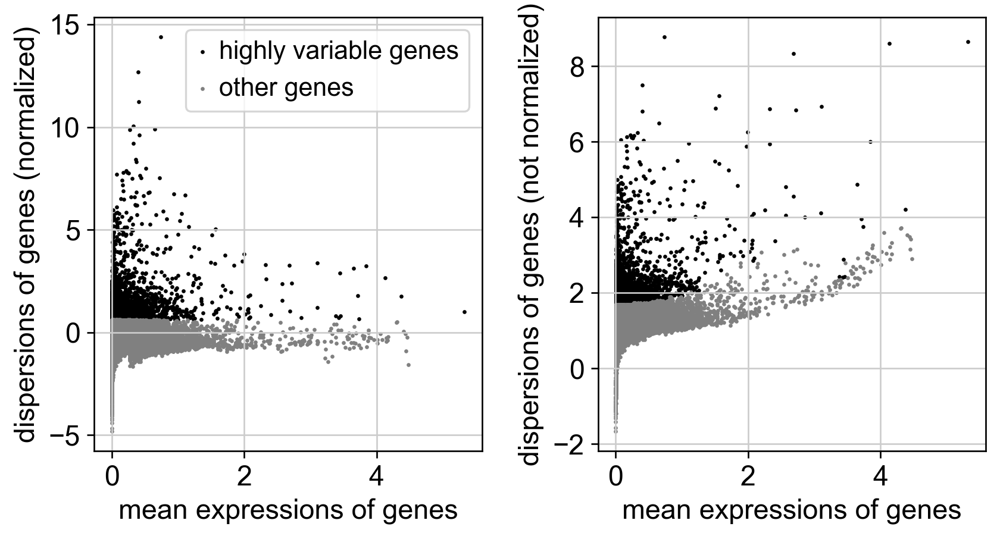

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


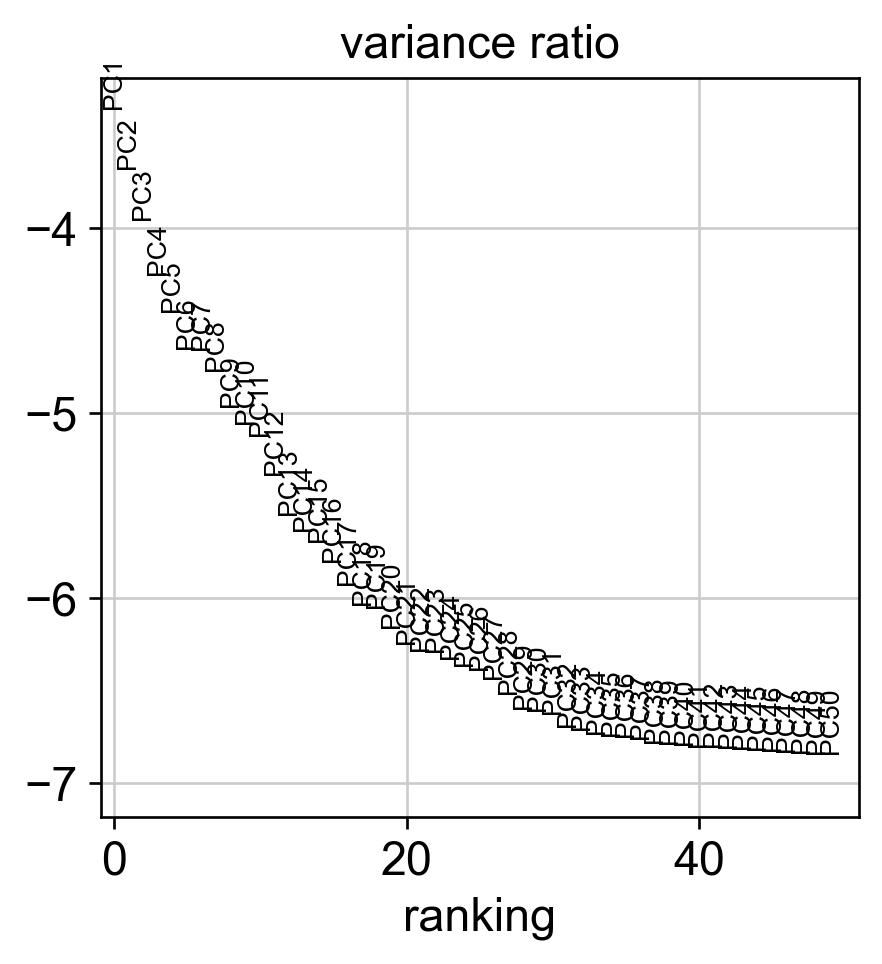

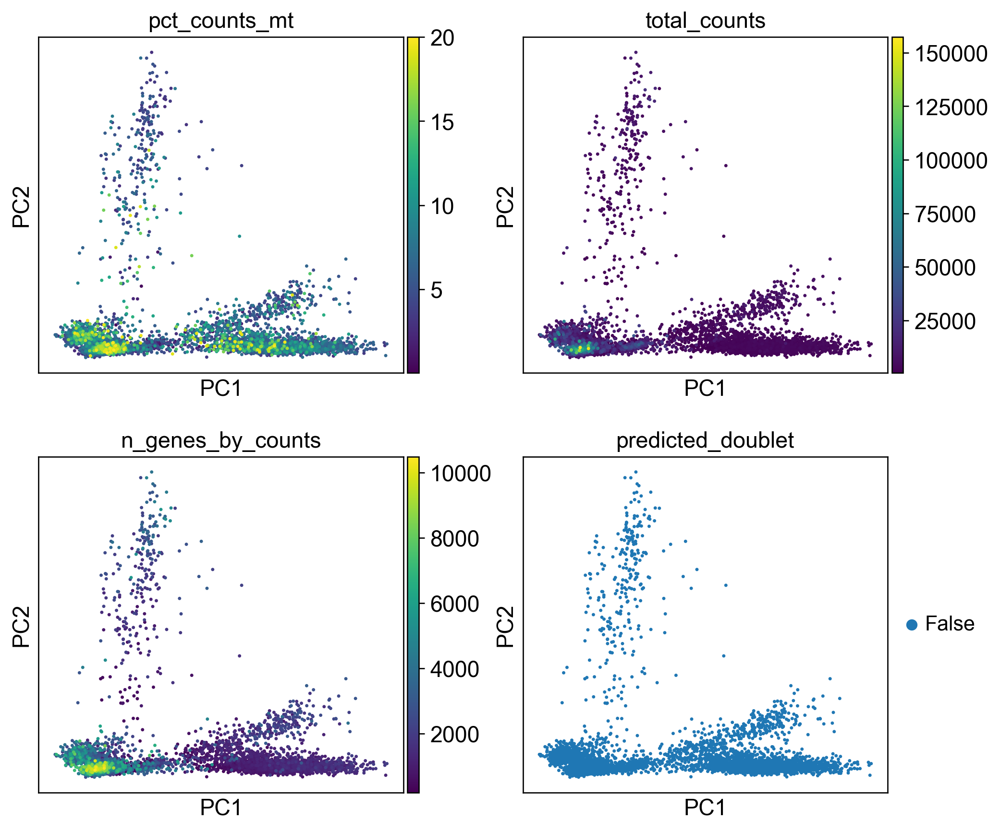

In [31]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [32]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 38
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 38
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:08)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 12 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 16 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 17 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden cluste

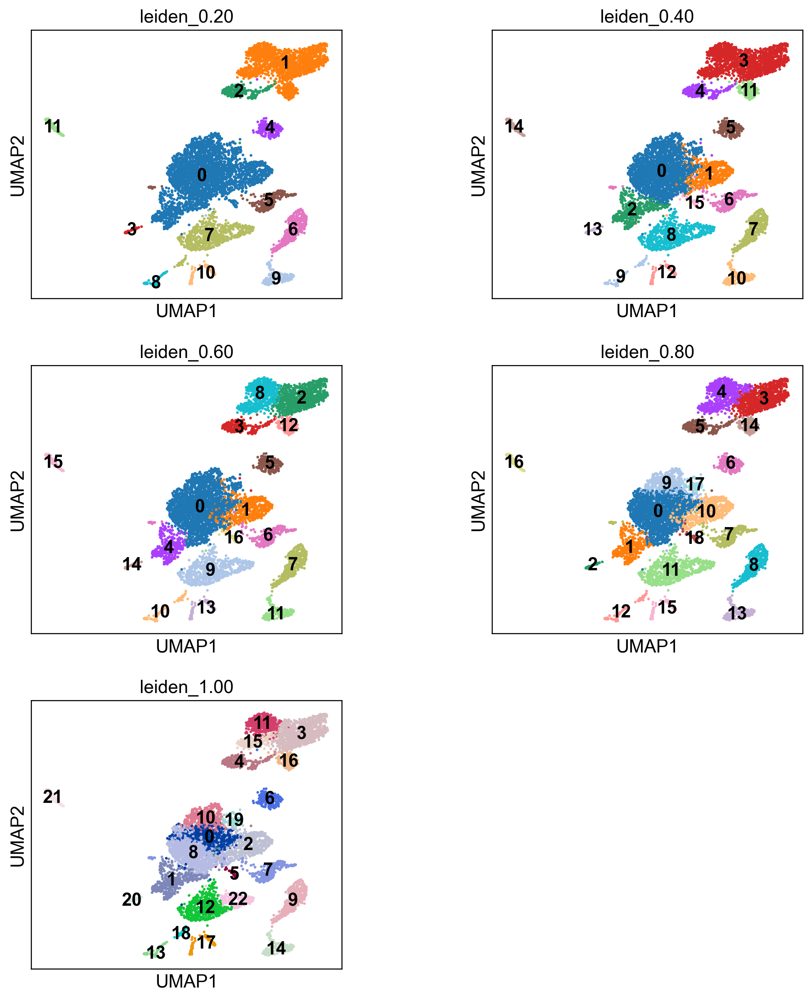

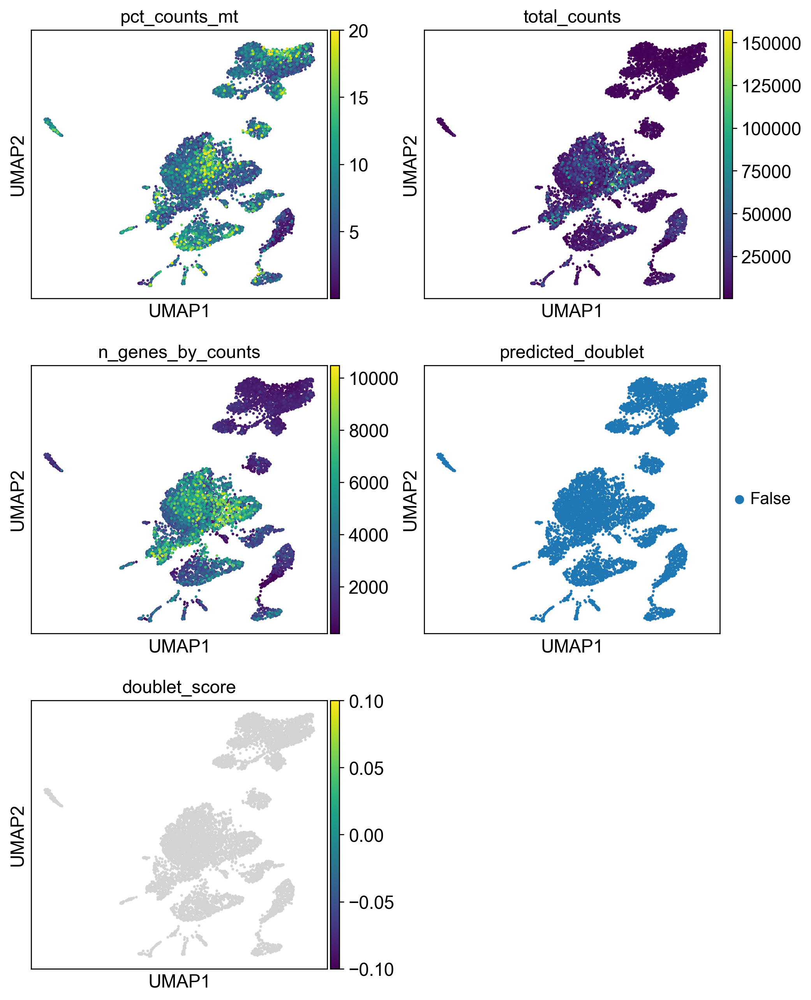

In [33]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [34]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.60"
TOP_N_MARKERS = 15

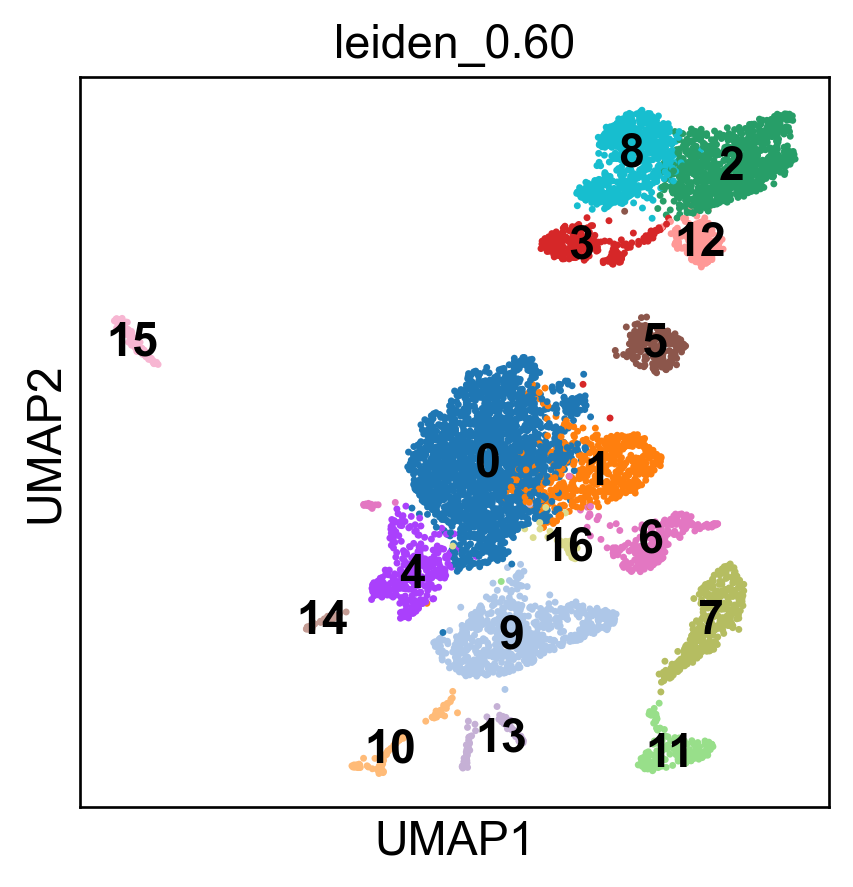

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:05)


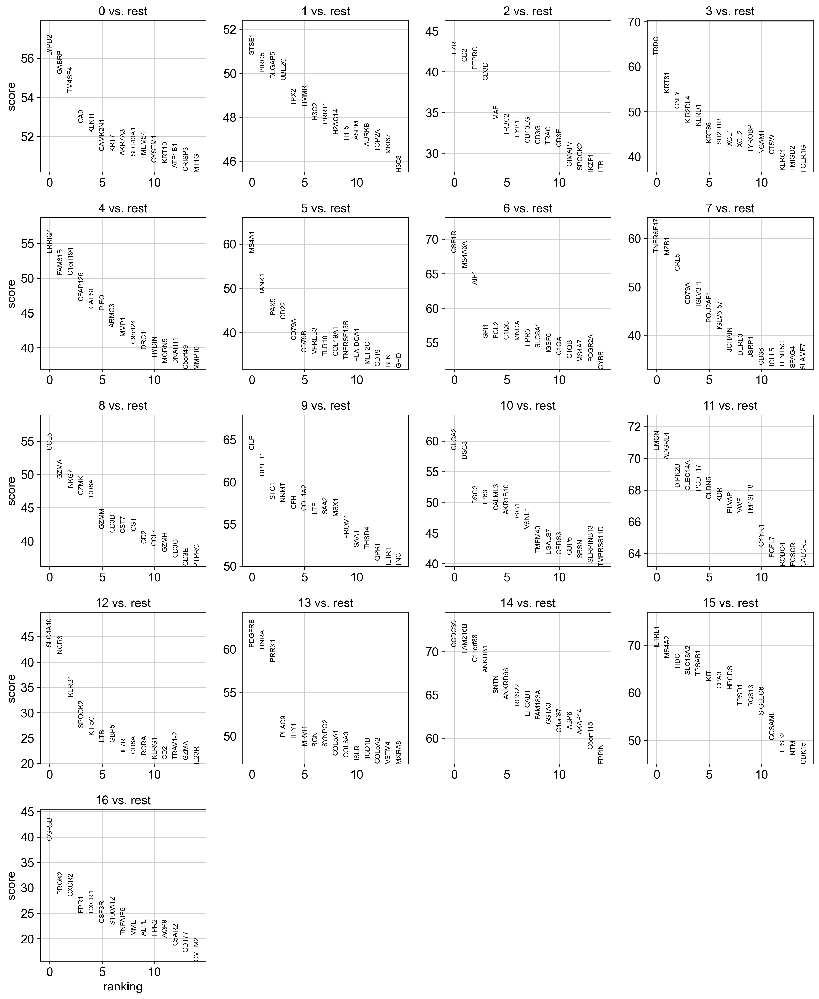

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.60']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
rank_1,LYPD2,GTSE1,IL7R,TRDC,LRRIQ1,MS4A1,CSF1R,TNFRSF17,CCL5,CILP,CLCA2,EMCN,SLC4A10,PDGFRB,CCDC39,IL1RL1,FCGR3B
rank_2,GABRP,BIRC5,CD2,KRT81,FAM81B,BANK1,MS4A6A,MZB1,GZMA,BPIFB1,DSC3,ADGRL4,NCR3,EDNRA,FAM216B,MS4A2,PROK2
rank_3,TM4SF4,DLGAP5,PTPRC,GNLY,C1orf194,PAX5,AIF1,FCRL5,NKG7,STC1,DSG3,DIPK2B,KLRB1,PRRX1,C11orf88,HDC,CXCR2
rank_4,CA9,UBE2C,CD3D,KIR2DL4,CFAP126,CD22,SPI1,CD79A,GZMK,NNMT,TP63,CLEC14A,SPOCK2,PLAC9,ANKUB1,SLC18A2,FPR1
rank_5,KLK11,TPX2,MAF,KLRD1,CAPSL,CD79A,FGL2,IGLV3-1,CD8A,CFH,CALML3,PCDH17,KIF5C,THY1,SNTN,TPSAB1,CXCR1
rank_6,CAMK2N1,HMMR,TRBC2,KRT86,PIFO,CD79B,C1QC,POU2AF1,GZMM,COL1A2,AKR1B10,CLDN5,LTB,MRVI1,ANKRD66,KIT,CSF3R
rank_7,KRT7,H3C2,FYB1,SH2D1B,ARMC3,VPREB3,MNDA,IGLV6-57,CD3D,LTF,DSG1,KDR,GBP5,BGN,RGS22,CPA3,S100A12
rank_8,AKR7A3,PRR11,CD40LG,XCL1,MMP1,TLR10,FPR3,JCHAIN,CST7,SAA2,VSNL1,PLVAP,IL7R,SYNPO2,EFCAB1,HPGDS,TNFAIP6
rank_9,SLC40A1,H2AC14,CD3G,XCL2,C9orf24,COL19A1,SLC8A1,DERL3,HCST,MSX1,TMEM40,VWF,CD8A,COL5A1,FAM183A,TPSD1,MME
rank_10,TMEM54,H1-5,TRAC,TYROBP,DRC1,TNFRSF13B,IGSF6,JSRP1,CD2,PROM1,LGALS7,TM4SF18,RORA,COL6A3,GSTA3,RGS13,ALPL


In [35]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [37]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "epithelial cells",
    "1": "cycling/proliferating epithelial cells",
    "2": "T cells",
    "3": "NK / cytotoxic lymphocytes",
    "4": "ciliated epithelial cells",
    "5": "B cells",
    "6": "macrophages / monocytes",
    "7": "plasma cells",
    "8": "CD8+ / cytotoxic T cells",
    "9": "fibroblasts",
    "10": "squamous epithelial cells",
    "11": "endothelial cells",
    "12": "T / NK cells",
    "13": "pericytes / vascular smooth muscle-like cells",
    "14": "ciliated epithelial cells",
    "15": "mast cells",
    "16": "neutrophils"
}

In [38]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360685_HSIL_2__celltype_mapping.tsv.gz
                                                                   cell_id          sample_id leiden_0.60                   cell_type
GSM6360685_HSIL_2_AAACCCAAGAATGTTG-1  GSM6360685_HSIL_2_AAACCCAAGAATGTTG-1  GSM6360685_HSIL_2           0            epithelial cells
GSM6360685_HSIL_2_AAACCCAAGGGTATAT-1  GSM6360685_HSIL_2_AAACCCAAGGGTATAT-1  GSM6360685_HSIL_2           2                     T cells
GSM6360685_HSIL_2_AAACCCACACTCAGAT-1  GSM6360685_HSIL_2_AAACCCACACTCAGAT-1  GSM6360685_HSIL_2           3  NK / cytotoxic lymphocytes
GSM6360685_HSIL_2_AAACCCACAGCAGAAC-1  GSM6360685_HSIL_2_AAACCCACAGCAGAAC-1  GSM6360685_HSIL_2           4   ciliated epithelial cells
GSM6360685_HSIL_2_AAACCCACAGCTCCTT-1  GSM6360685_HSIL_2_AAACCCACAGCTCCTT-1  GSM6360685_HSIL_2           2                     T cells


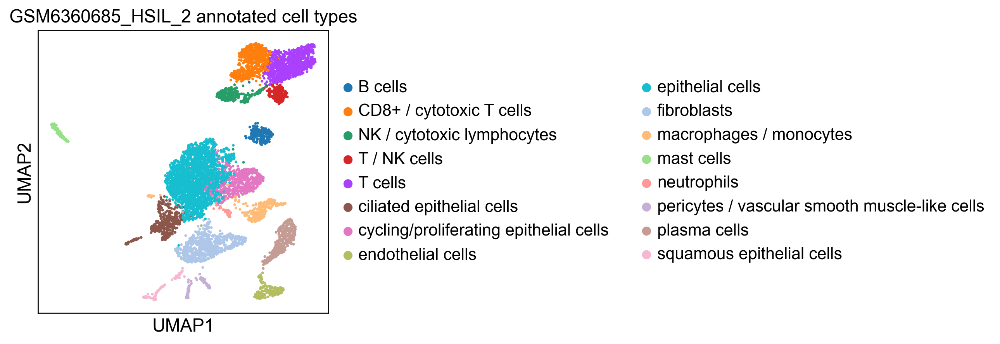

In [39]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360686_SCC_4

In [4]:
sample_id = "GSM6360686_SCC_4"

AnnData object with n_obs × n_vars = 8979 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 4468 genes that are detected in less than 3 cells


,suggested_value
min_counts,32.00
max_counts,135868.00
min_genes,100.00
max_genes,22631.00
max_pct_mt,11.79


QC plots for GSM6360686_SCC_4
normalizing counts per cell
    finished (0:00:00)


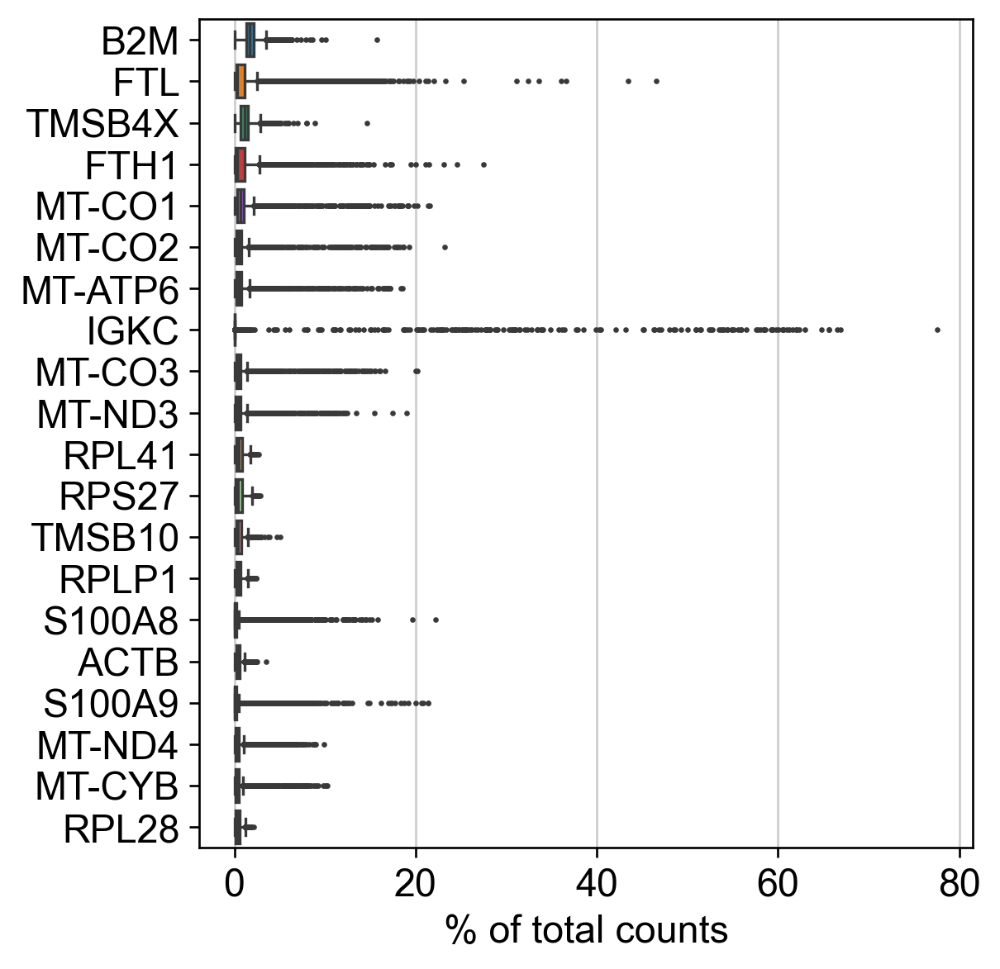

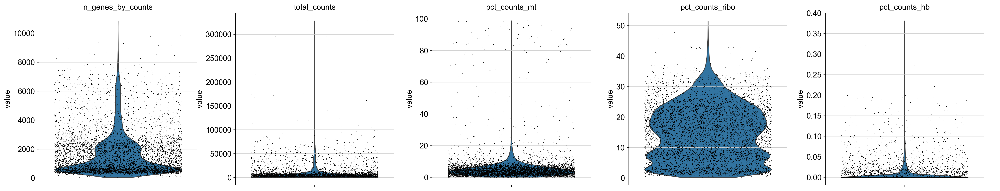

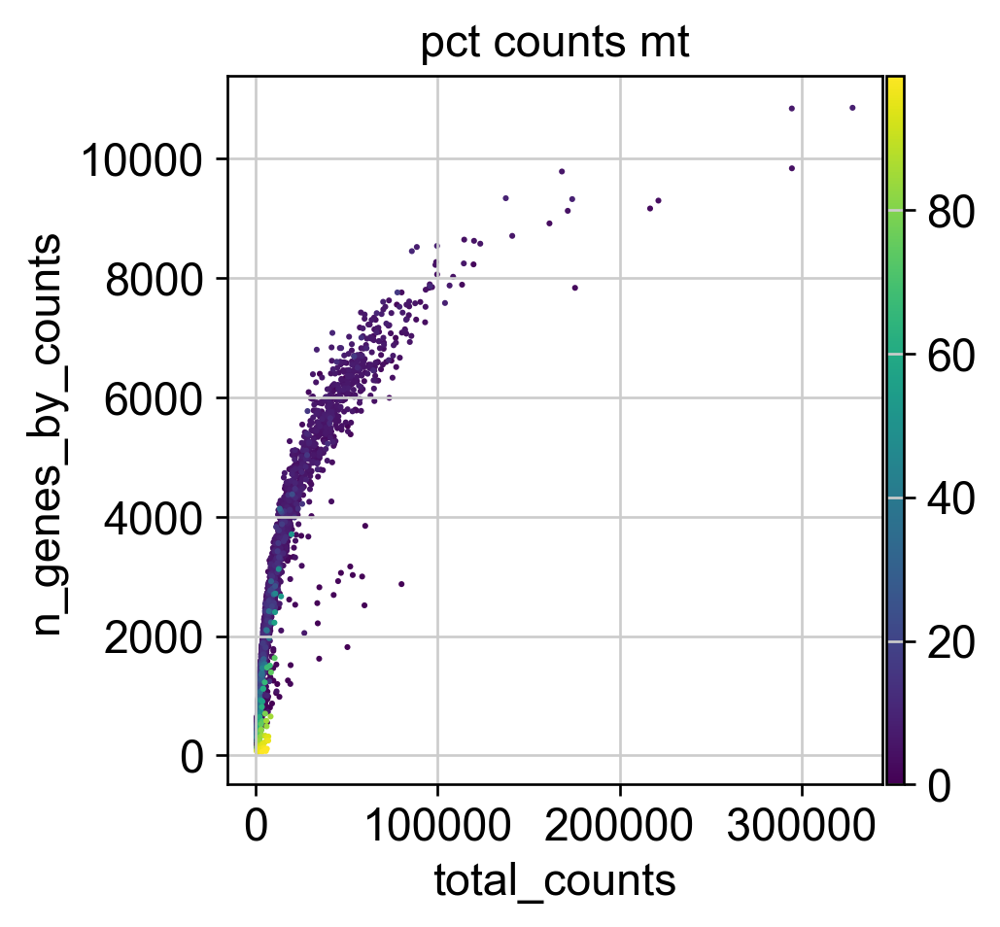

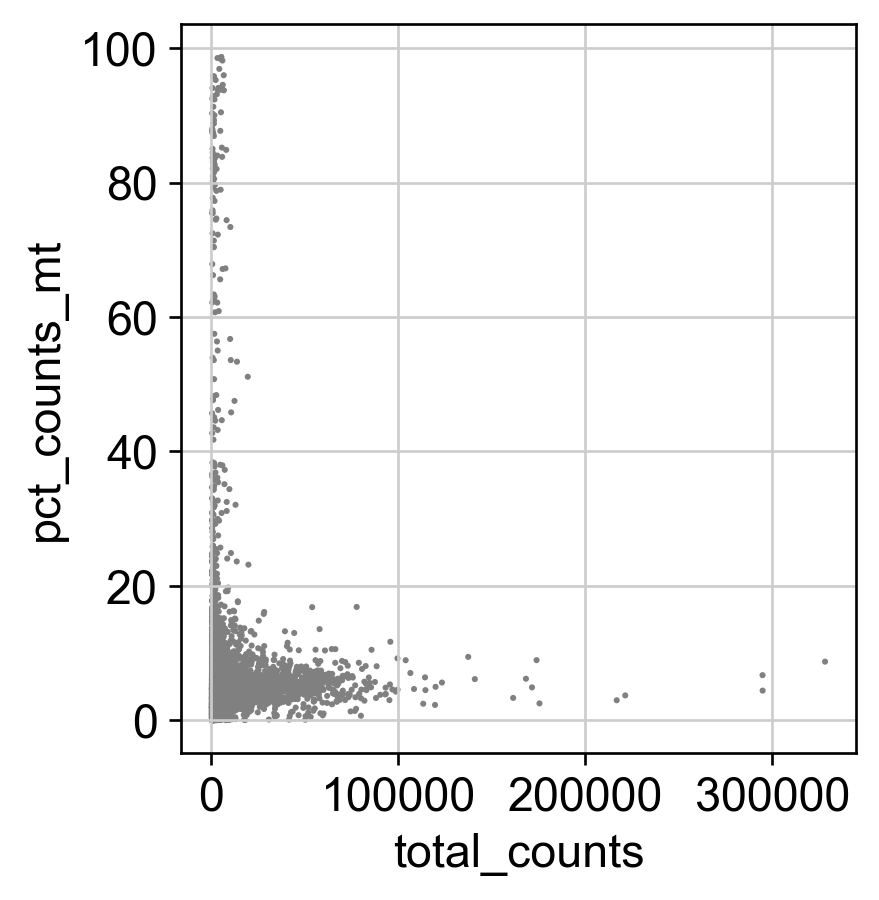

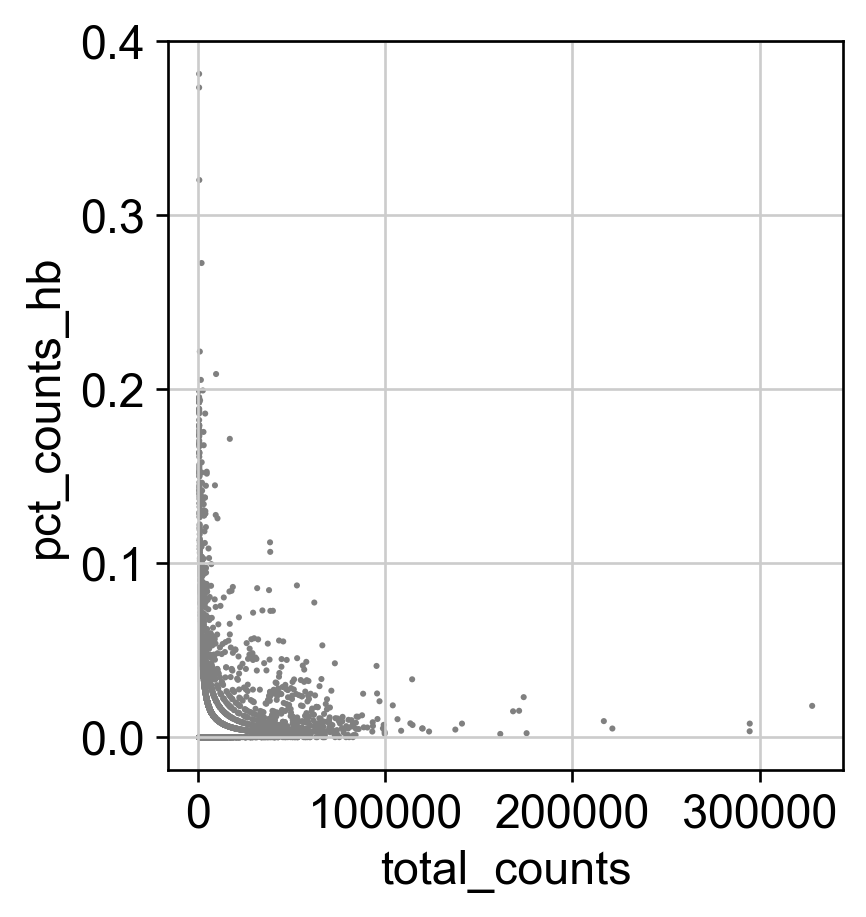

In [5]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [6]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 4468 genes that are detected in less than 3 cells
Cells before QC: 8979
Cells after QC : 8753
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_83018/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


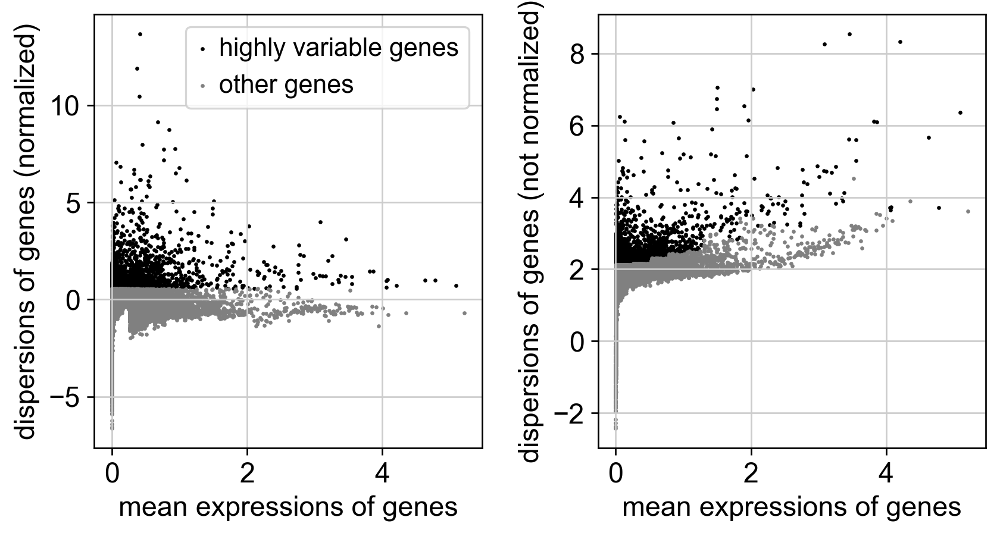

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


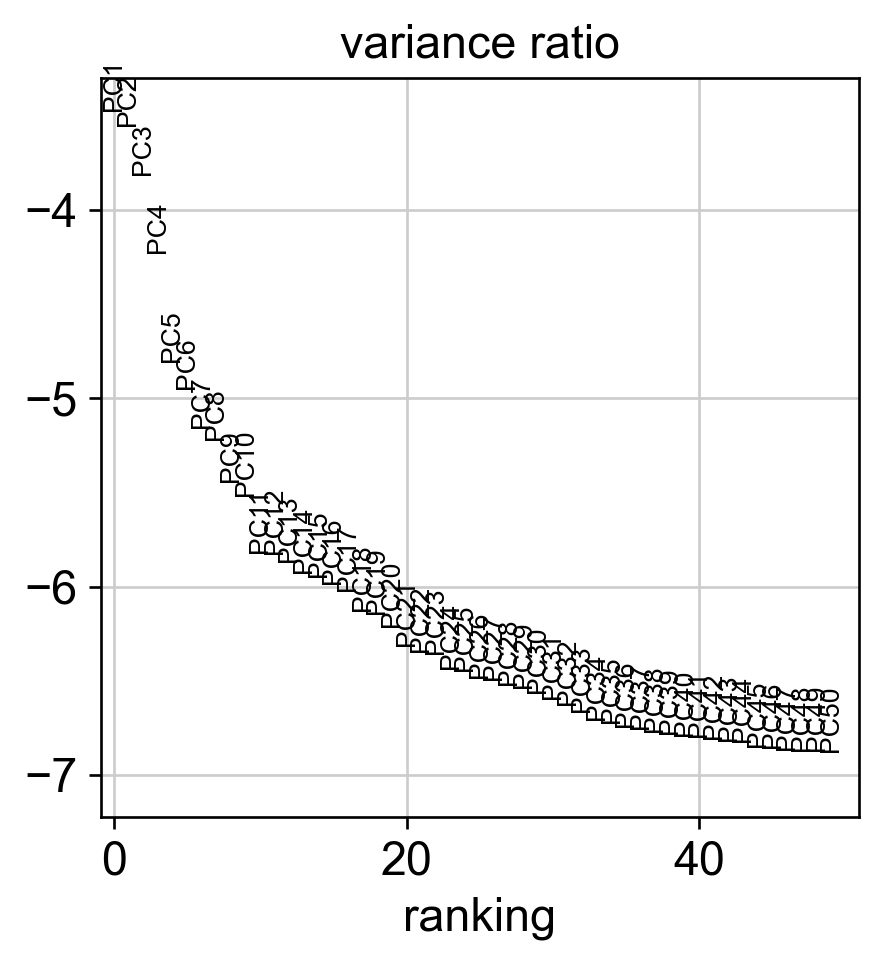

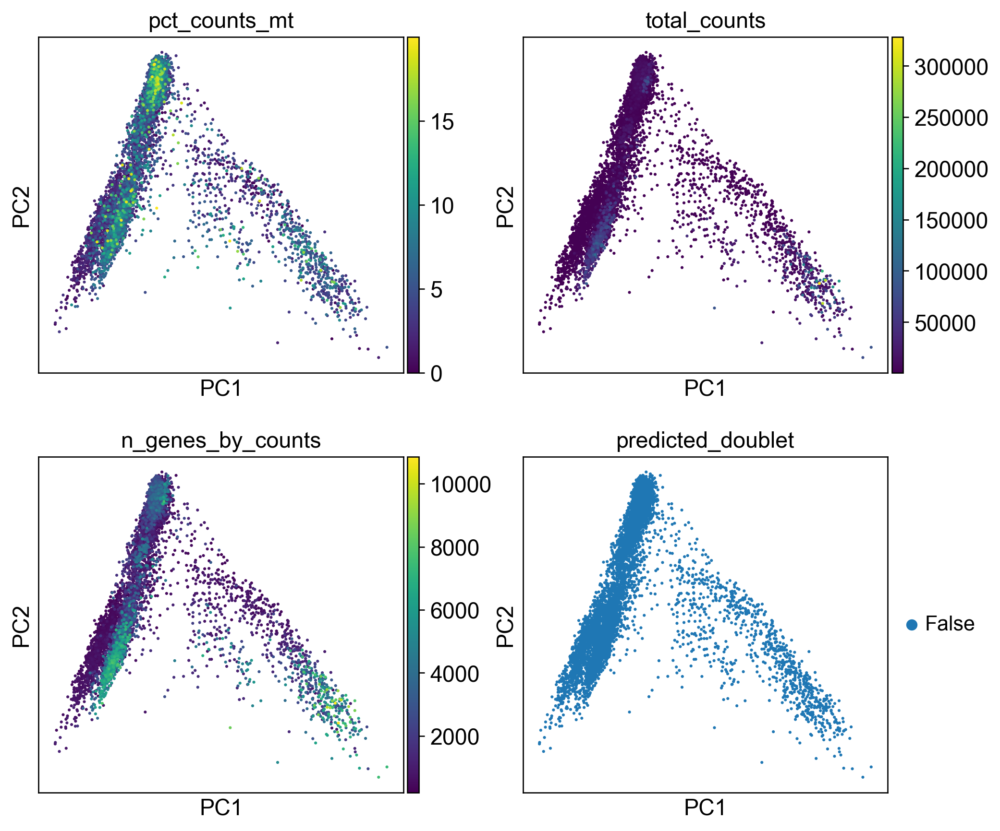

In [7]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [8]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 50
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 50


$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:11)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 12 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 16 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 19 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden clustering
    finished: found 25 clusters and added
    'le

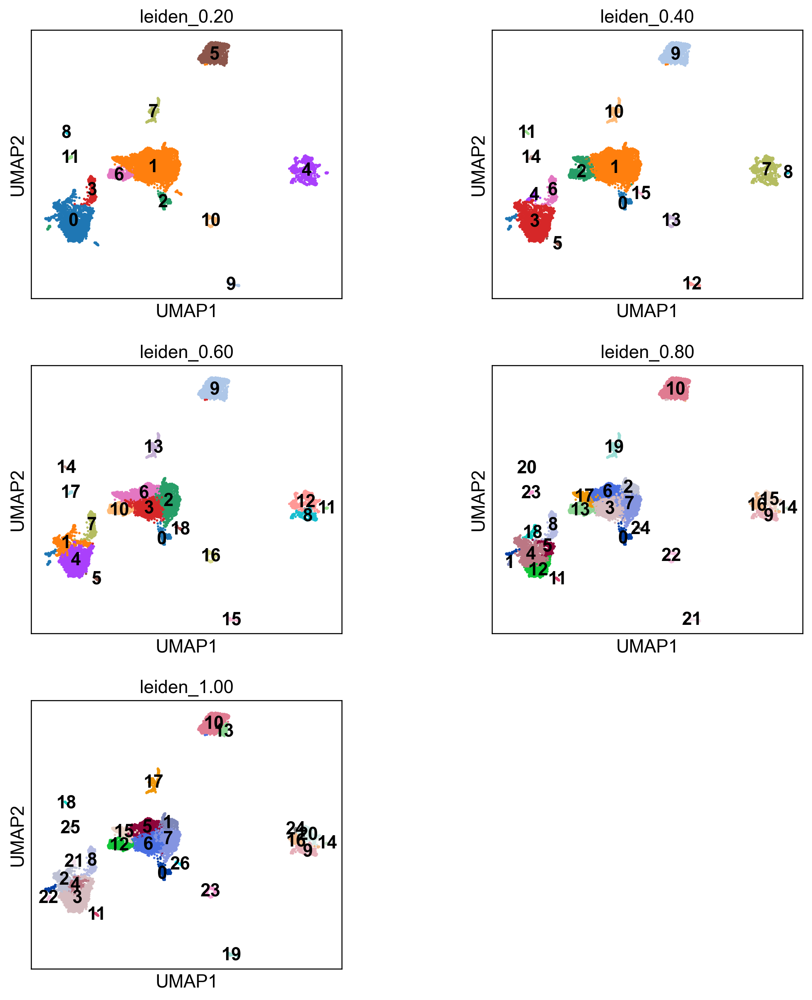

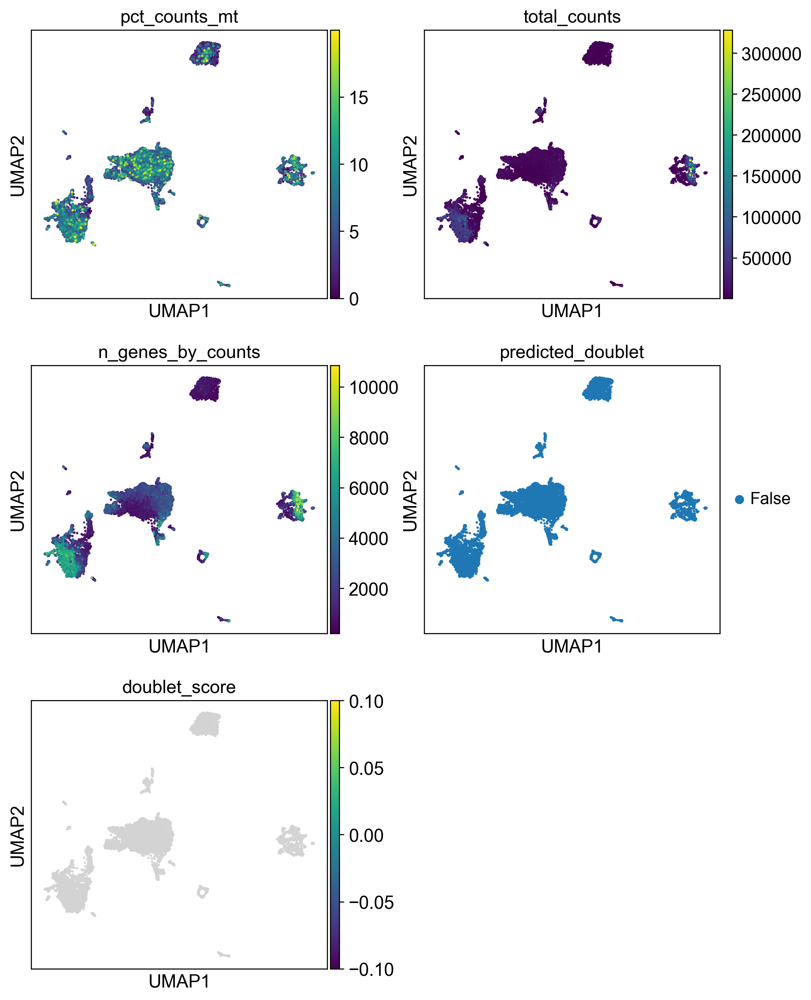

In [9]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [10]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.40"
TOP_N_MARKERS = 15

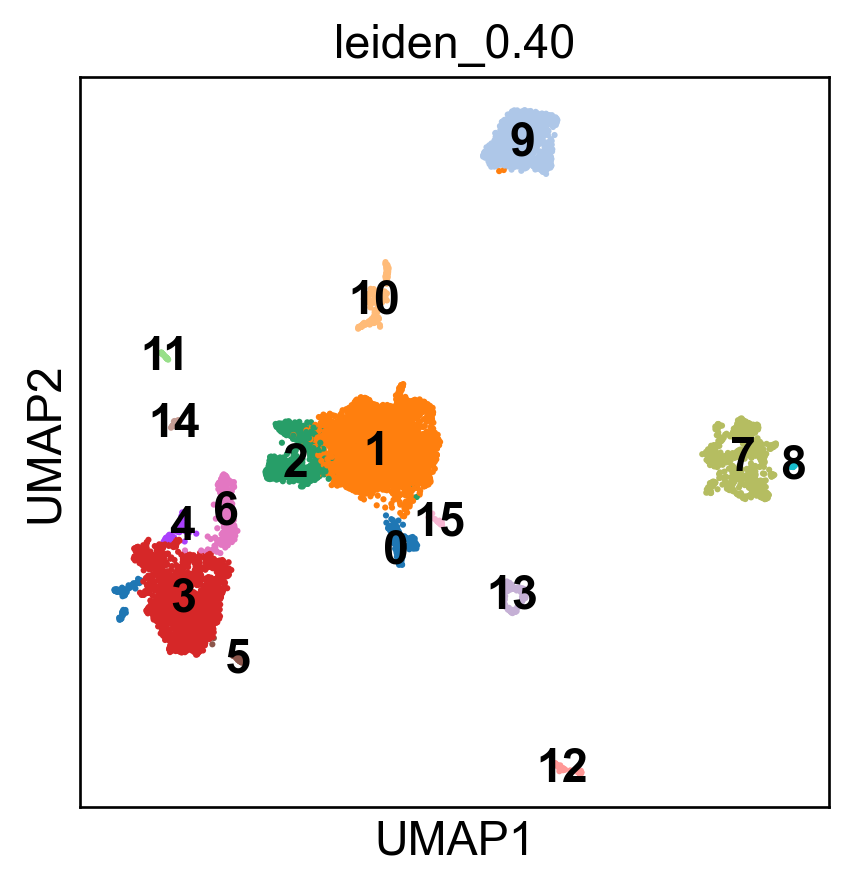

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.40']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:05)


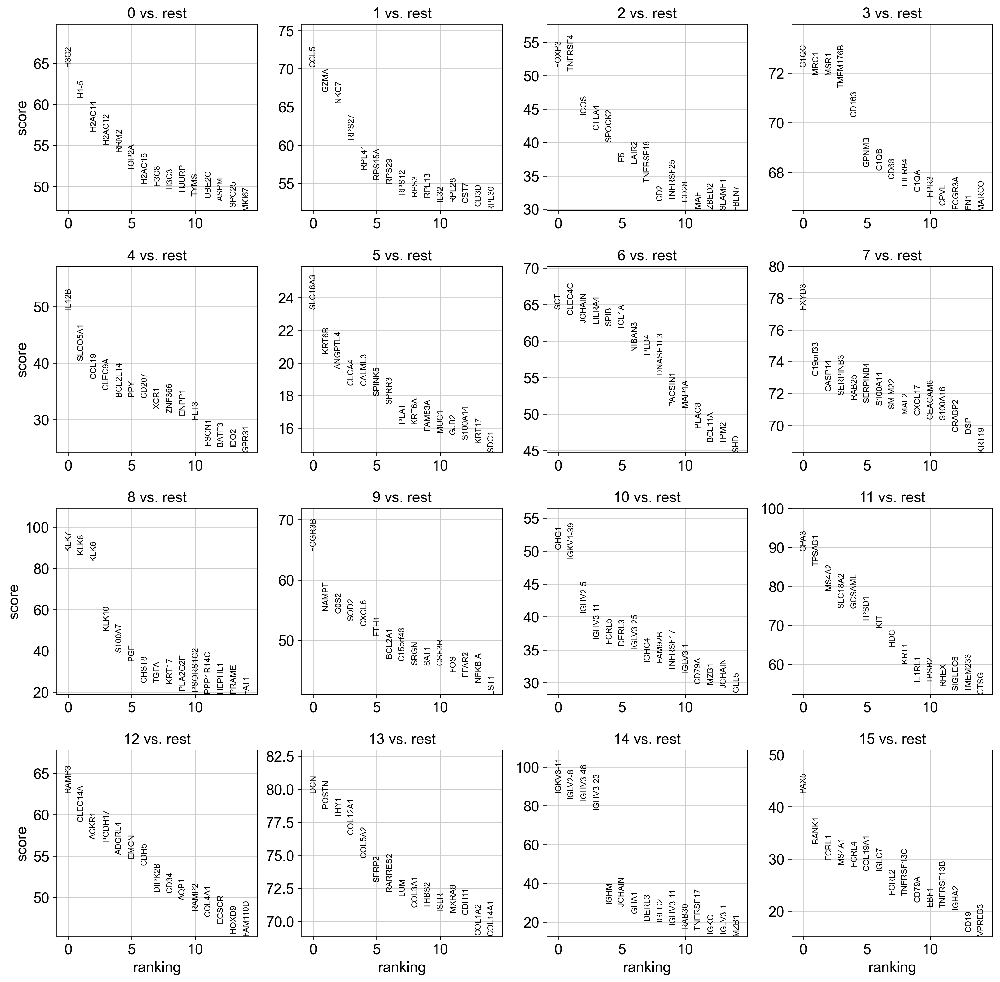

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.40']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
rank_1,H3C2,CCL5,FOXP3,C1QC,IL12B,KRT6B,SCT,FXYD3,KLK7,FCGR3B,IGHG1,CPA3,RAMP3,DCN,IGKV3-11,PAX5
rank_2,H1-5,GZMA,TNFRSF4,MRC1,SLCO5A1,ANGPTL4,CLEC4C,C19orf33,KLK8,NAMPT,IGKV1-39,TPSAB1,CLEC14A,POSTN,IGLV2-8,BANK1
rank_3,H2AC14,NKG7,ICOS,MSR1,CCL19,CLCA4,JCHAIN,CASP14,KLK6,G0S2,IGHV2-5,MS4A2,ACKR1,THY1,IGHV3-48,FCRL1
rank_4,H2AC12,RPS27,CTLA4,TMEM176B,CLEC9A,CALML3,LILRA4,SERPINB3,KLK10,SOD2,IGHV3-11,SLC18A2,PCDH17,COL12A1,IGHV3-23,MS4A1
rank_5,RRM2,RPL41,SPOCK2,CD163,BCL2L14,SPINK5,SPIB,RAB25,S100A7,CXCL8,FCRL5,GCSAML,ADGRL4,COL5A2,IGHM,FCRL4
rank_6,TOP2A,RPS15A,F5,GPNMB,PPY,SPRR3,TCL1A,SERPINB4,PGF,FTH1,DERL3,TPSD1,EMCN,SFRP2,JCHAIN,FCRL2
rank_7,H2AC16,RPS29,LAIR2,C1QB,CD207,PLAT,NIBAN3,S100A14,CHST8,BCL2A1,IGLV3-25,KIT,CDH5,RARRES2,IGHA1,TNFRSF13C
rank_8,H3C8,RPS12,TNFRSF18,CD68,XCR1,KRT6A,PLD4,SMIM22,TGFA,C15orf48,IGHG4,HDC,DIPK2B,LUM,DERL3,CD79A
rank_9,H3C3,RPS3,CD2,LILRB4,ZNF366,FAM83A,DNASE1L3,MAL2,KRT17,SRGN,FAM92B,KRT1,CD34,COL3A1,IGLC2,EBF1
rank_10,HJURP,RPL13,TNFRSF25,C1QA,ENPP1,MUC1,PACSIN1,CXCL17,PLA2G2F,SAT1,TNFRSF17,IL1RL1,AQP1,THBS2,IGHV3-11,TNFRSF13B


In [11]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [12]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "Cycling/proliferating cells",
    "1": "Cytotoxic T/NK cells",
    "2": "Regulatory T cells",
    "3": "Macrophages",
    "4": "Conventional dendritic cells",
    "5": "Malignant squamous epithelial cells",
    "6": "Plasmacytoid dendritic cells",
    "7": "Malignant epithelial cells",
    "8": "Keratinizing squamous epithelial cells",
    "9": "Neutrophils",
    "10": "Plasma cells",
    "11": "Mast cells",
    "12": "Endothelial cells",
    "13": "Fibroblasts",
    "14": "Plasma cells",
    "15": "B cells"
}

In [13]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360686_SCC_4__celltype_mapping.tsv.gz
                                                                 cell_id         sample_id leiden_0.40                    cell_type
GSM6360686_SCC_4_AAACCCAAGGATACAT-1  GSM6360686_SCC_4_AAACCCAAGGATACAT-1  GSM6360686_SCC_4           0  Cycling/proliferating cells
GSM6360686_SCC_4_AAACCCACAAGTGGTG-1  GSM6360686_SCC_4_AAACCCACAAGTGGTG-1  GSM6360686_SCC_4           1         Cytotoxic T/NK cells
GSM6360686_SCC_4_AAACCCACATTCACAG-1  GSM6360686_SCC_4_AAACCCACATTCACAG-1  GSM6360686_SCC_4           3                  Macrophages
GSM6360686_SCC_4_AAACCCAGTCATCGGC-1  GSM6360686_SCC_4_AAACCCAGTCATCGGC-1  GSM6360686_SCC_4           3                  Macrophages
GSM6360686_SCC_4_AAACCCATCCGTTTCG-1  GSM6360686_SCC_4_AAACCCATCCGTTTCG-1  GSM6360686_SCC_4           1         Cytotoxic T/NK cells


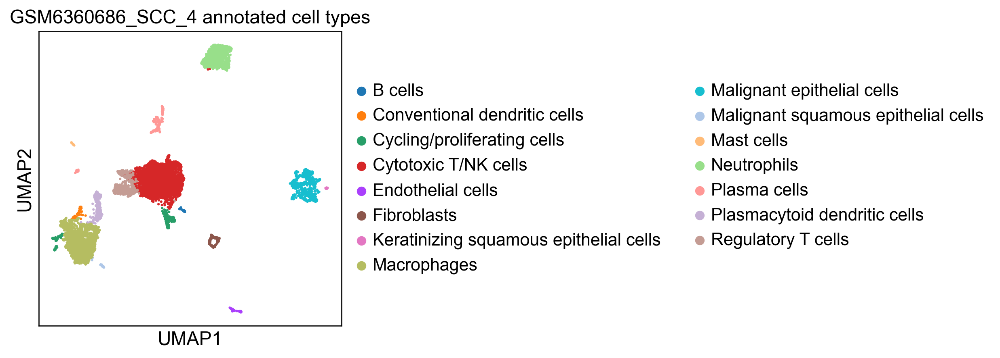

In [14]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360687_SCC_5

In [15]:
sample_id = "GSM6360687_SCC_5"

AnnData object with n_obs × n_vars = 6734 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3641 genes that are detected in less than 3 cells


,suggested_value
min_counts,91.00
max_counts,420480.00
min_genes,138.00
max_genes,39587.00
max_pct_mt,19.41


QC plots for GSM6360687_SCC_5
normalizing counts per cell
    finished (0:00:00)


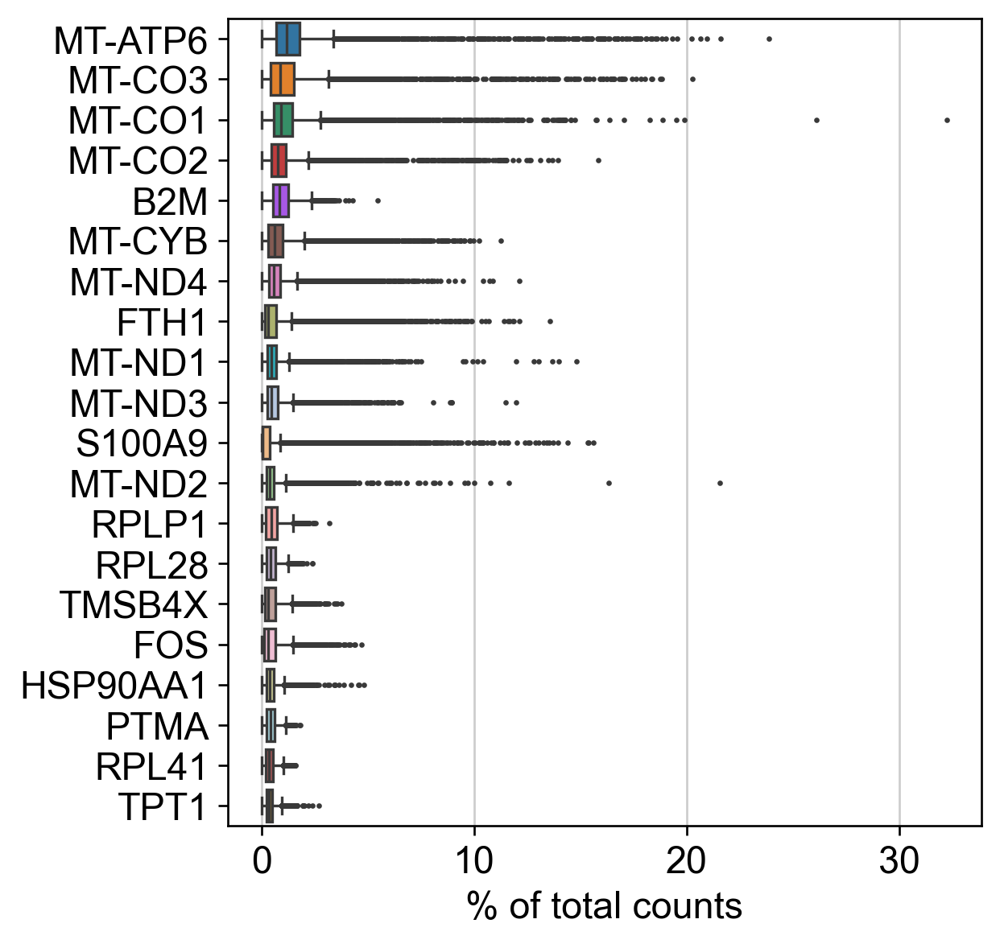

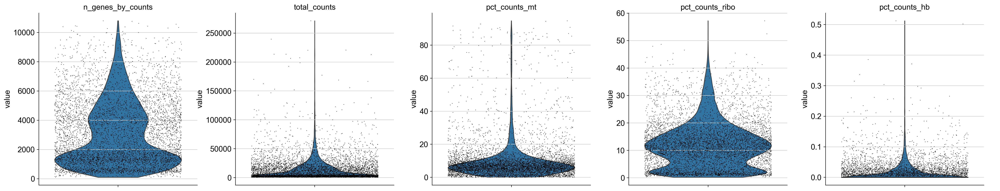

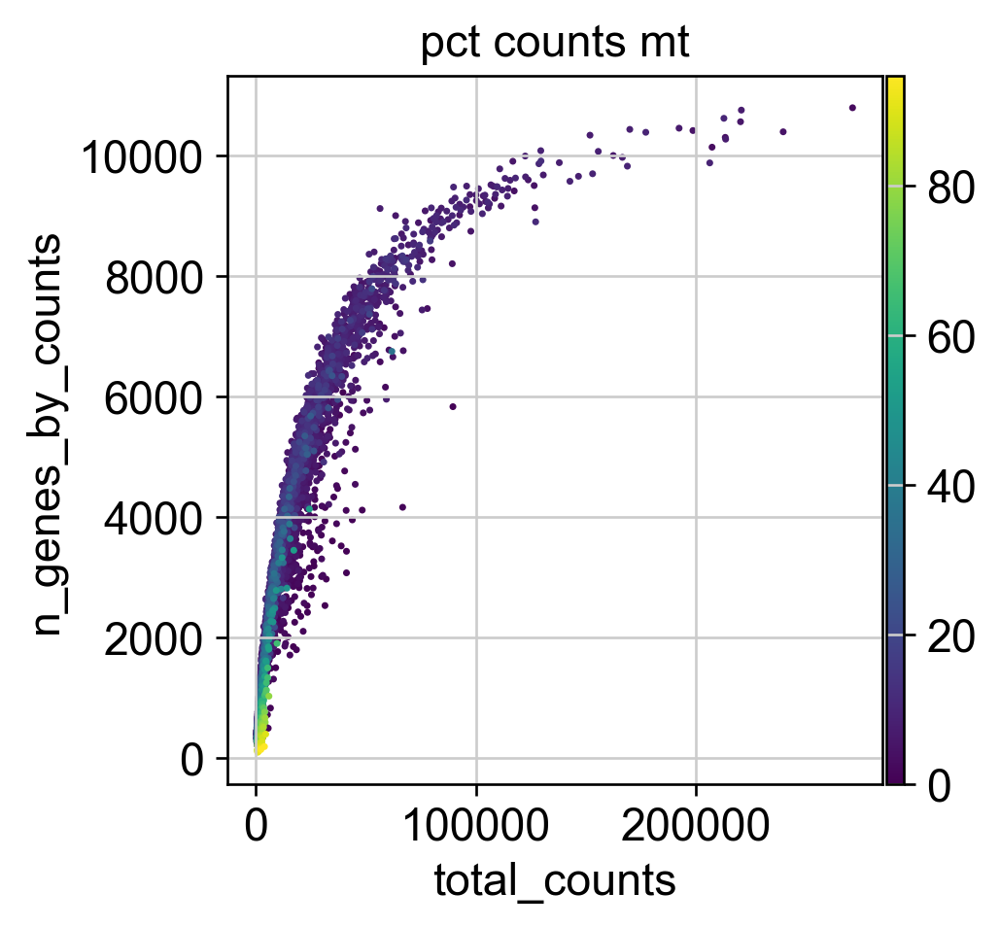

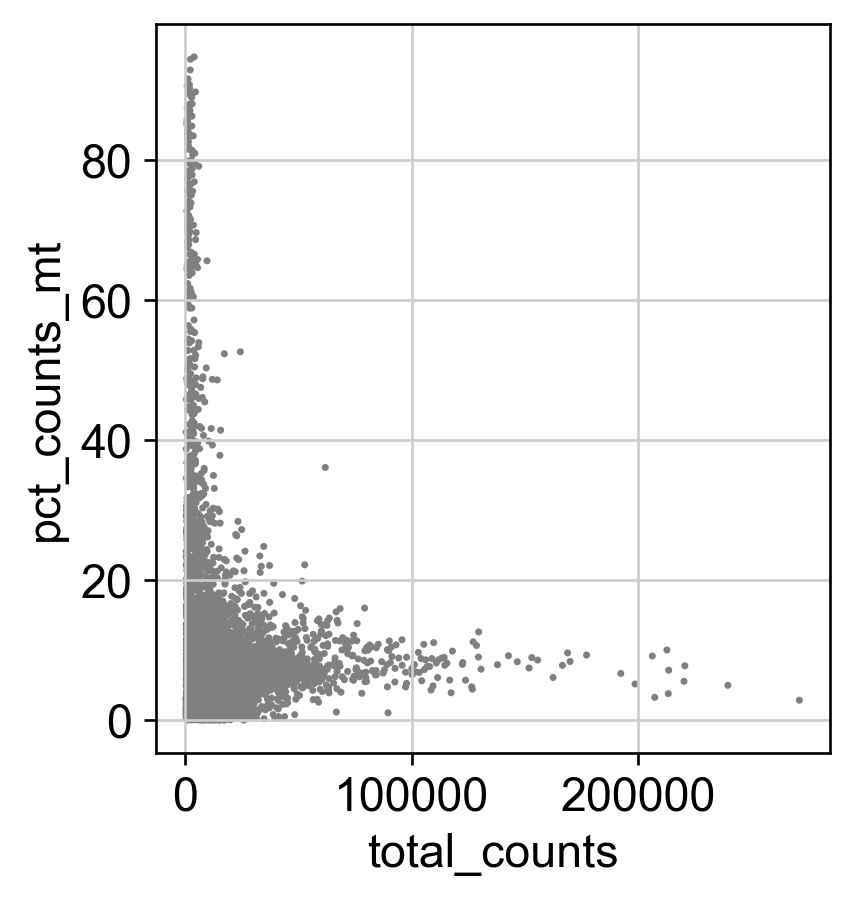

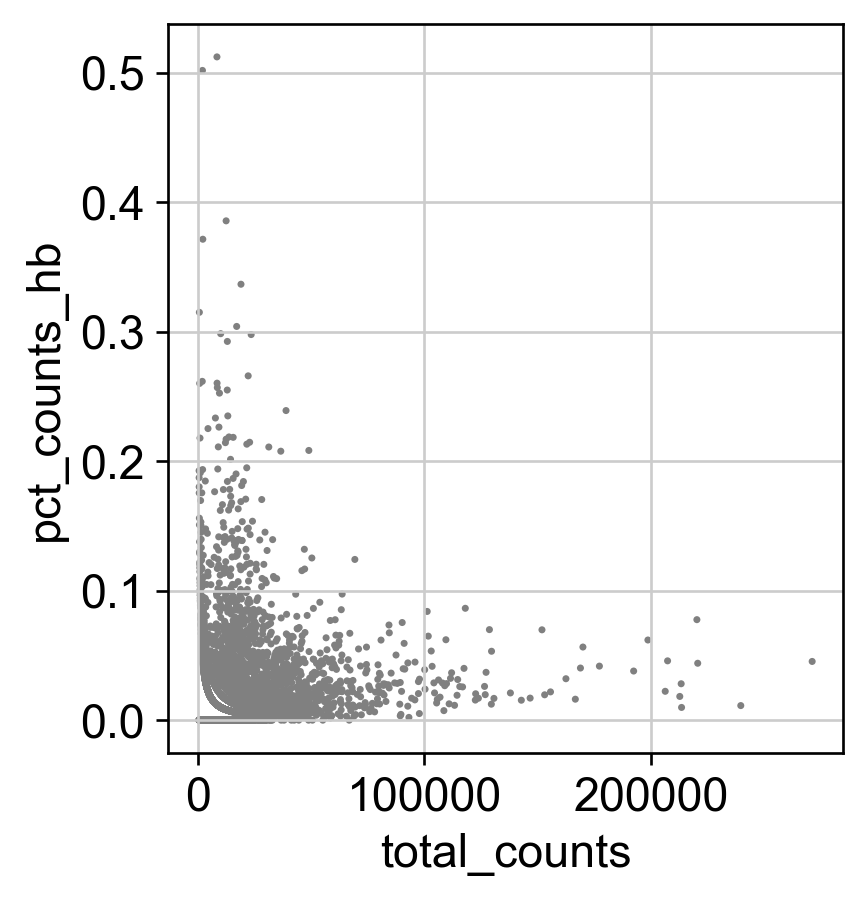

In [16]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [17]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3641 genes that are detected in less than 3 cells
Cells before QC: 6734
Cells after QC : 6195
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_83018/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


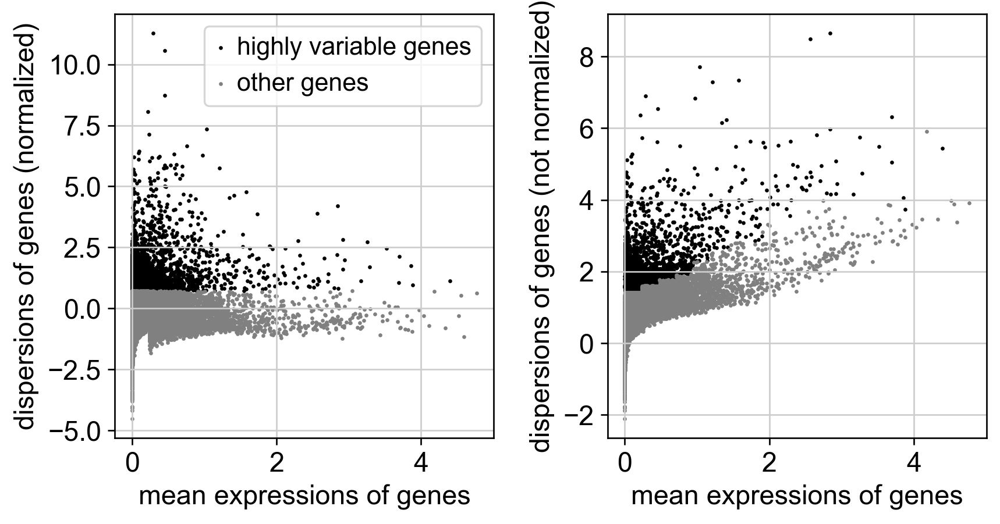

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:00)


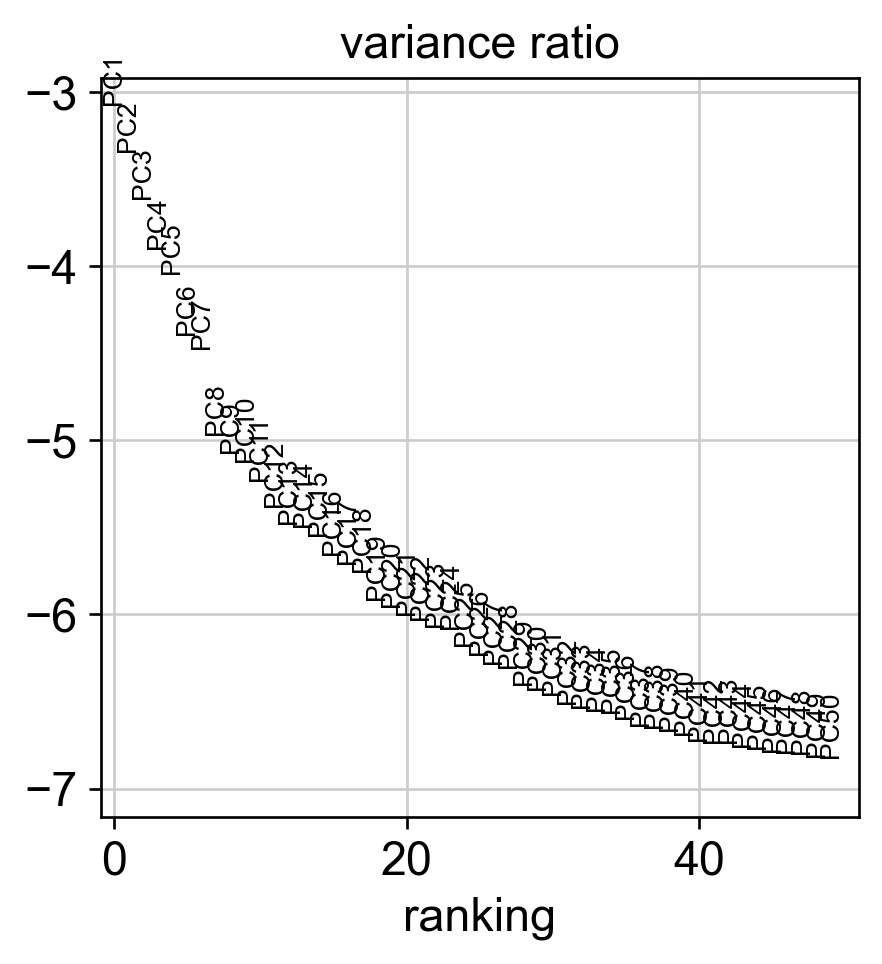

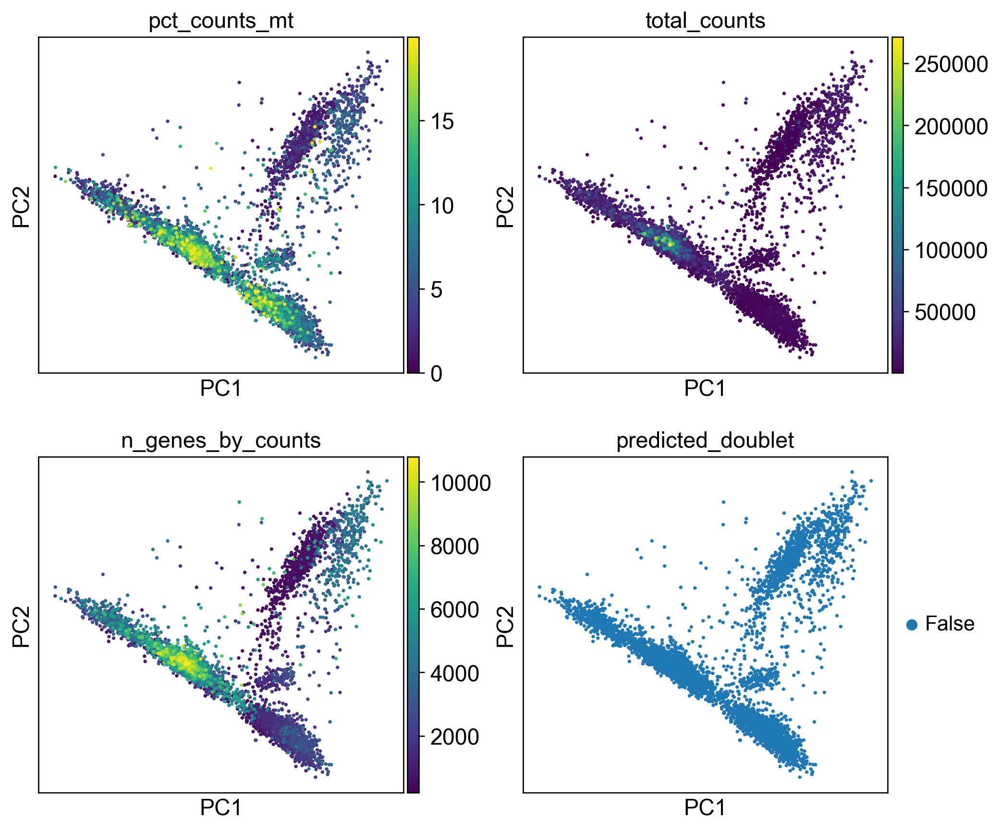

In [18]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [19]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 50
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:09)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 10 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 14 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 17 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden cluste

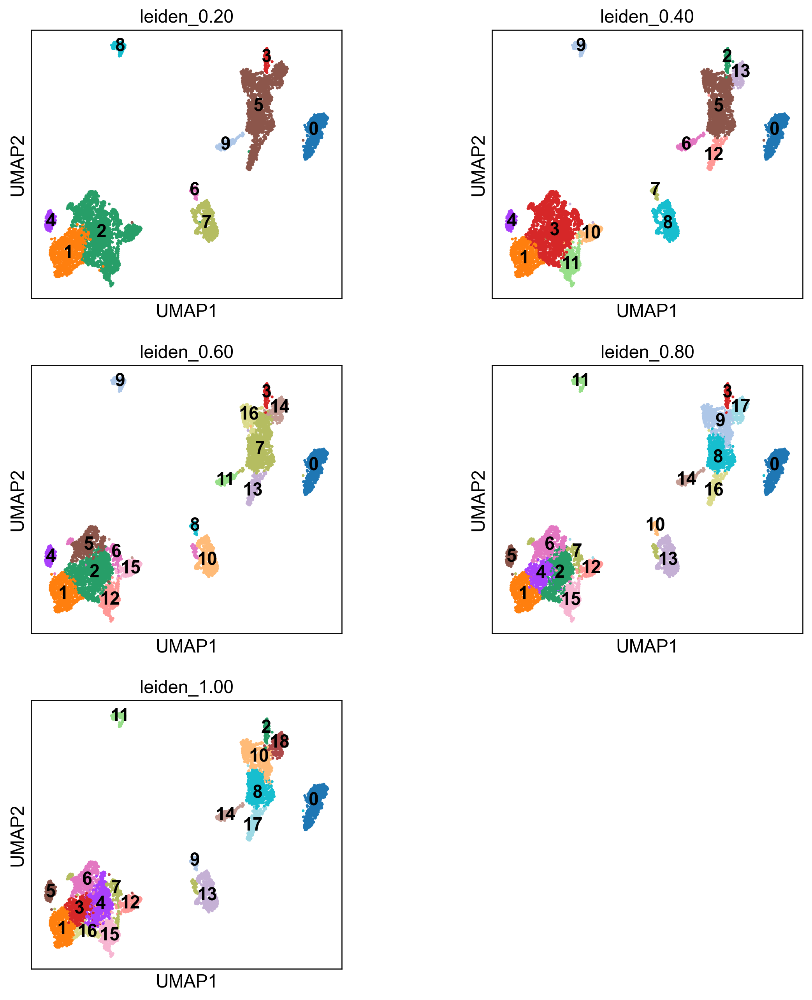

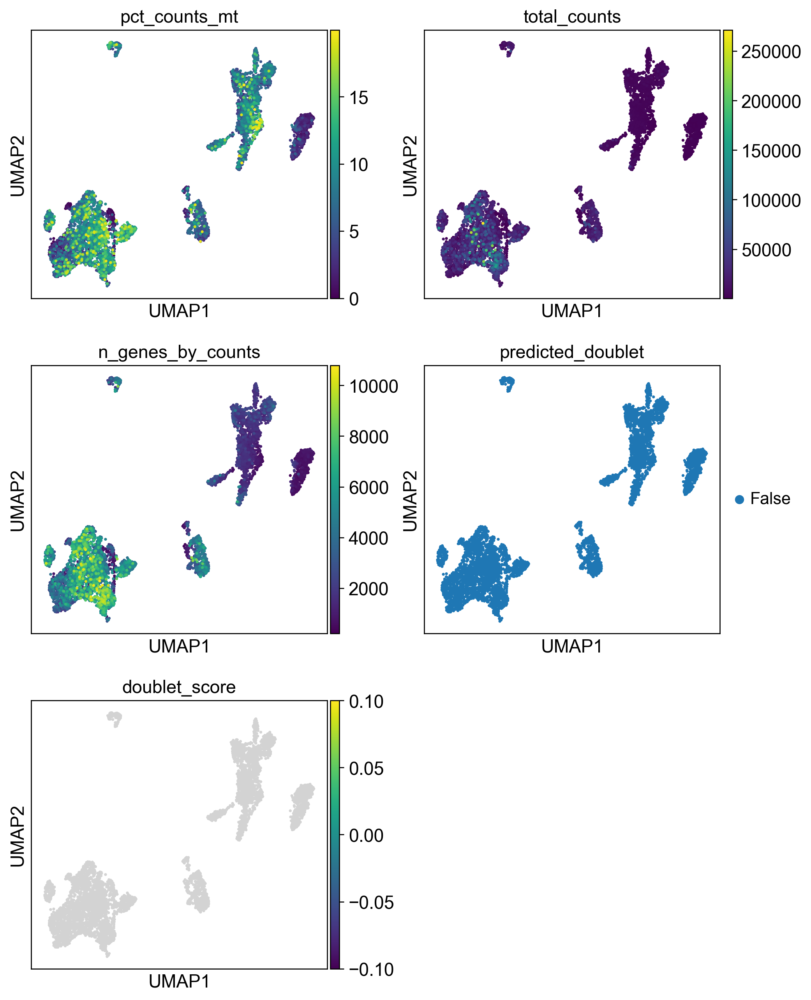

In [20]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [21]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.40"
TOP_N_MARKERS = 15

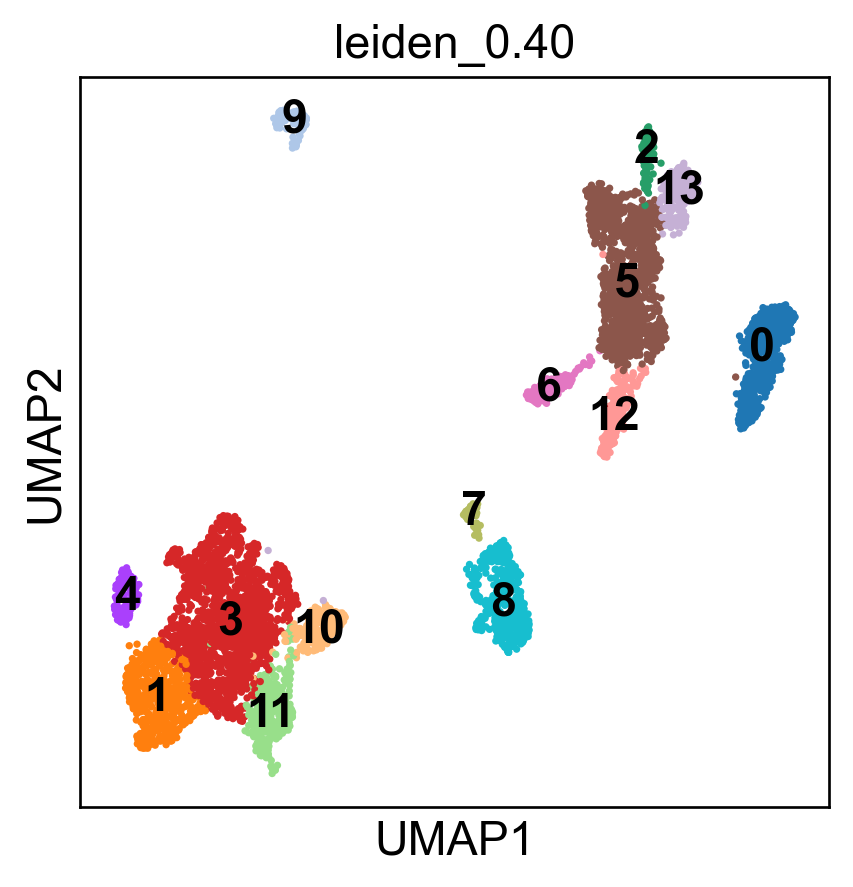

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.40']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:04)


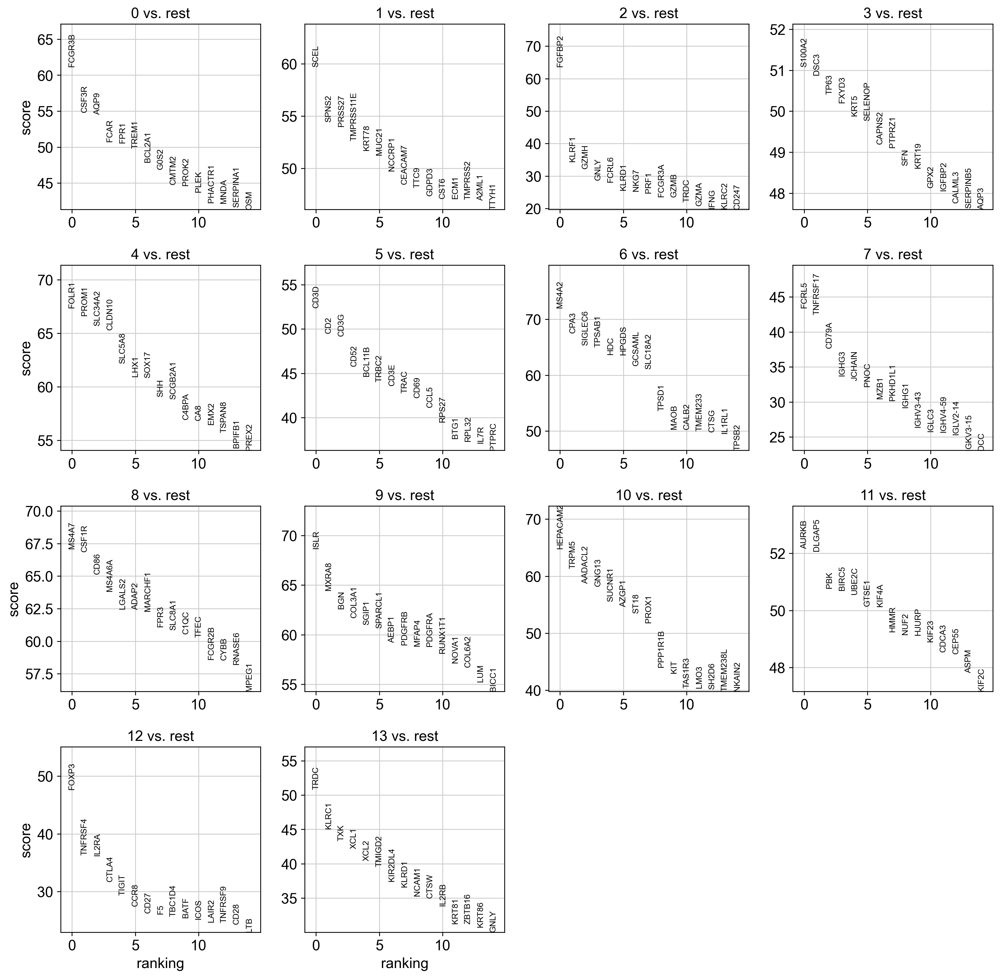

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.40']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
rank_1,FCGR3B,SCEL,FGFBP2,S100A2,FOLR1,CD3D,MS4A2,FCRL5,MS4A7,ISLR,HEPACAM2,AURKB,FOXP3,TRDC
rank_2,CSF3R,SPNS2,KLRF1,DSC3,PROM1,CD2,CPA3,TNFRSF17,CSF1R,MXRA8,TRPM5,DLGAP5,TNFRSF4,KLRC1
rank_3,AQP9,PRSS27,GZMH,TP63,SLC34A2,CD3G,SIGLEC6,CD79A,CD86,BGN,AADACL2,PBK,IL2RA,TXK
rank_4,FCAR,TMPRSS11E,GNLY,FXYD3,CLDN10,CD52,TPSAB1,IGHG3,MS4A6A,COL3A1,GNG13,BIRC5,CTLA4,XCL1
rank_5,FPR1,KRT78,FCRL6,KRT5,SLC5A8,BCL11B,HDC,JCHAIN,LGALS2,SGIP1,SUCNR1,UBE2C,TIGIT,XCL2
rank_6,TREM1,MUC21,KLRD1,SELENOP,LHX1,TRBC2,HPGDS,PNOC,ADAP2,SPARCL1,AZGP1,GTSE1,CCR8,TMIGD2
rank_7,BCL2A1,NCCRP1,NKG7,CAPNS2,SOX17,CD3E,GCSAML,MZB1,MARCHF1,AEBP1,ST18,KIF4A,CD27,KIR2DL4
rank_8,G0S2,CEACAM7,PRF1,PTPRZ1,SHH,TRAC,SLC18A2,PKHD1L1,FPR3,PDGFRB,PROX1,HMMR,F5,KLRD1
rank_9,CMTM2,TTC9,FCGR3A,SFN,SCGB2A1,CD69,TPSD1,IGHG1,SLC8A1,MFAP4,PPP1R1B,NUF2,TBC1D4,NCAM1
rank_10,PROK2,GDPD3,GZMB,KRT19,C4BPA,CCL5,MAOB,IGHV3-43,C1QC,PDGFRA,KIT,HJURP,BATF,CTSW


In [22]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [23]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "Neutrophils",
    "1": "Squamous epithelial cells",
    "2": "NK cells",
    "3": "Squamous epithelial cells",
    "4": "Epithelial cells (secretory-like)",
    "5": "T cells",
    "6": "Mast cells",
    "7": "Plasma cells",
    "8": "Macrophages",
    "9": "Fibroblasts",
    "10": "Tuft cells",
    "11": "Cycling/proliferating cells",
    "12": "Regulatory T cells",
    "13": "Gamma-delta T cells",
}

In [24]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360687_SCC_5__celltype_mapping.tsv.gz
                                                                 cell_id         sample_id leiden_0.40                          cell_type
GSM6360687_SCC_5_AAACCCAAGAAGTCTA-1  GSM6360687_SCC_5_AAACCCAAGAAGTCTA-1  GSM6360687_SCC_5           0                        Neutrophils
GSM6360687_SCC_5_AAACCCAGTAATGCTC-1  GSM6360687_SCC_5_AAACCCAGTAATGCTC-1  GSM6360687_SCC_5           1          Squamous epithelial cells
GSM6360687_SCC_5_AAACCCAGTCTTGCGG-1  GSM6360687_SCC_5_AAACCCAGTCTTGCGG-1  GSM6360687_SCC_5           2                           NK cells
GSM6360687_SCC_5_AAACCCAGTGTAGTGG-1  GSM6360687_SCC_5_AAACCCAGTGTAGTGG-1  GSM6360687_SCC_5           3          Squamous epithelial cells
GSM6360687_SCC_5_AAACCCATCCCTCGAT-1  GSM6360687_SCC_5_AAACCCATCCCTCGAT-1  GSM6360687_SCC_5           4  Epithelial cells (secretory-like)


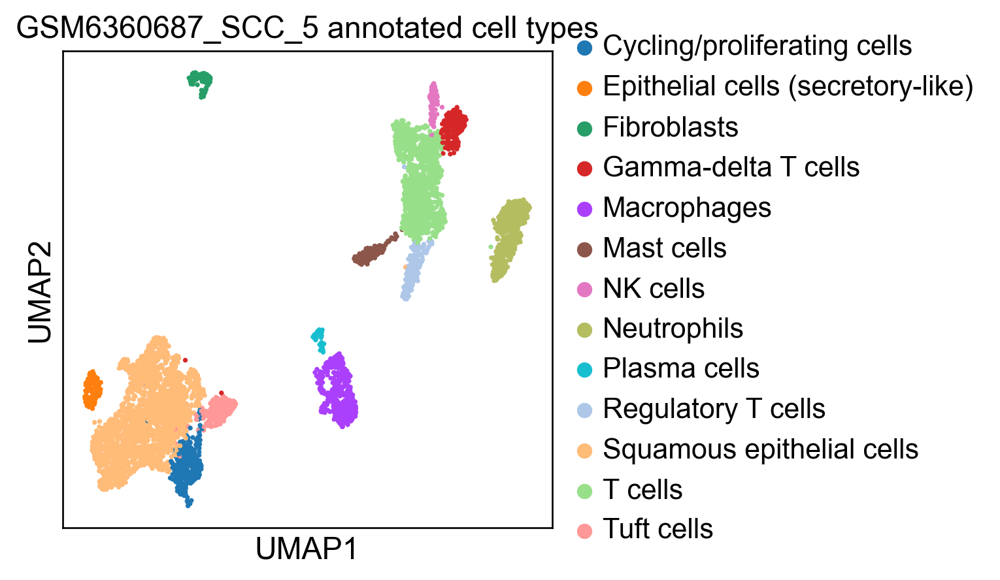

In [25]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

### GSM6360688_ADC_6

In [4]:
sample_id = "GSM6360688_ADC_6"

AnnData object with n_obs × n_vars = 10154 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species'
    var: 'gene_ids', 'feature_types'
Counts look integer-like: True
filtered out 3646 genes that are detected in less than 3 cells


,suggested_value
min_counts,187.00
max_counts,77822.00
min_genes,147.00
max_genes,15049.00
max_pct_mt,27.46


QC plots for GSM6360688_ADC_6
normalizing counts per cell
    finished (0:00:00)


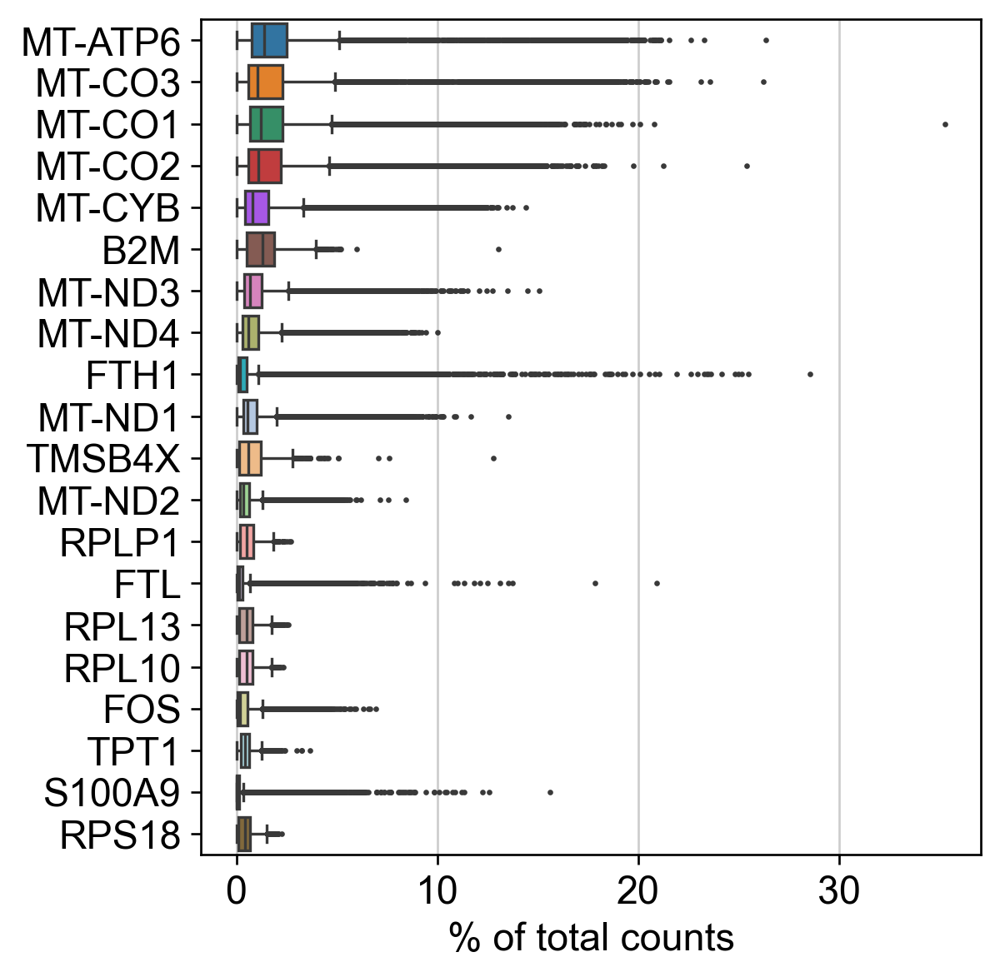

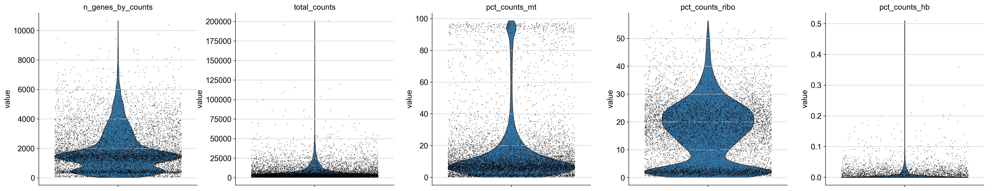

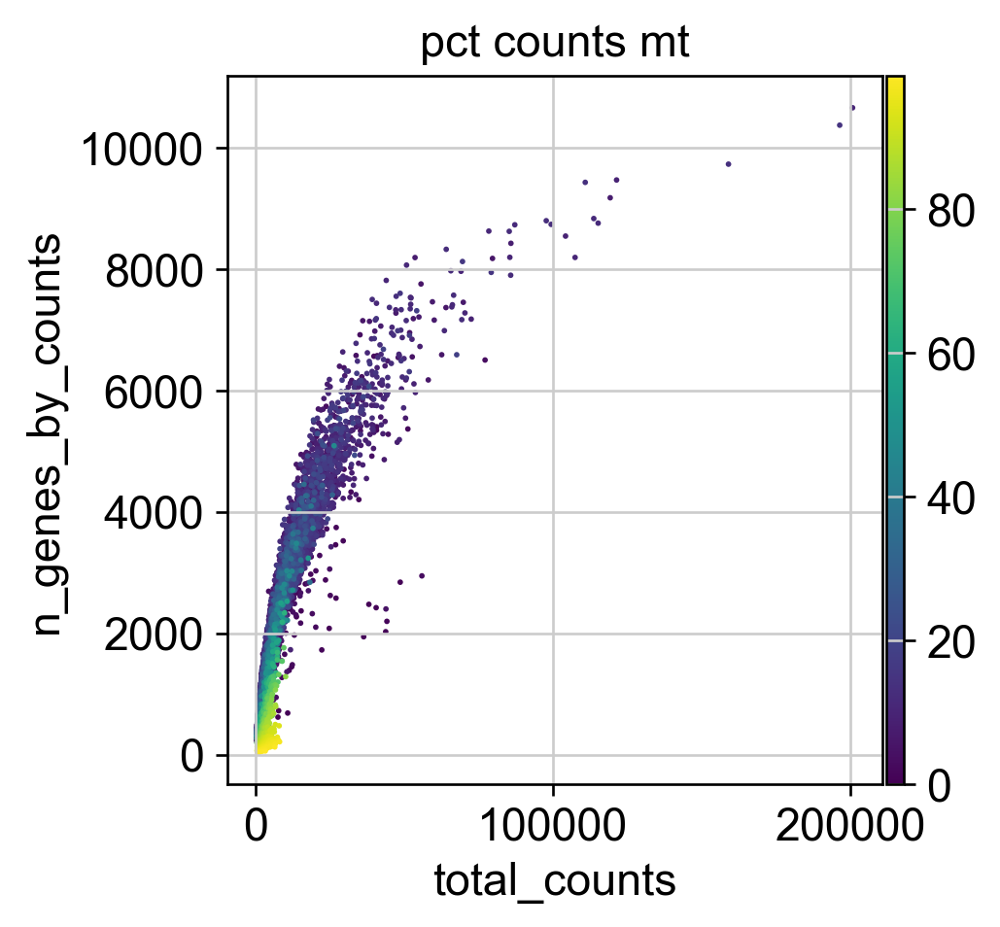

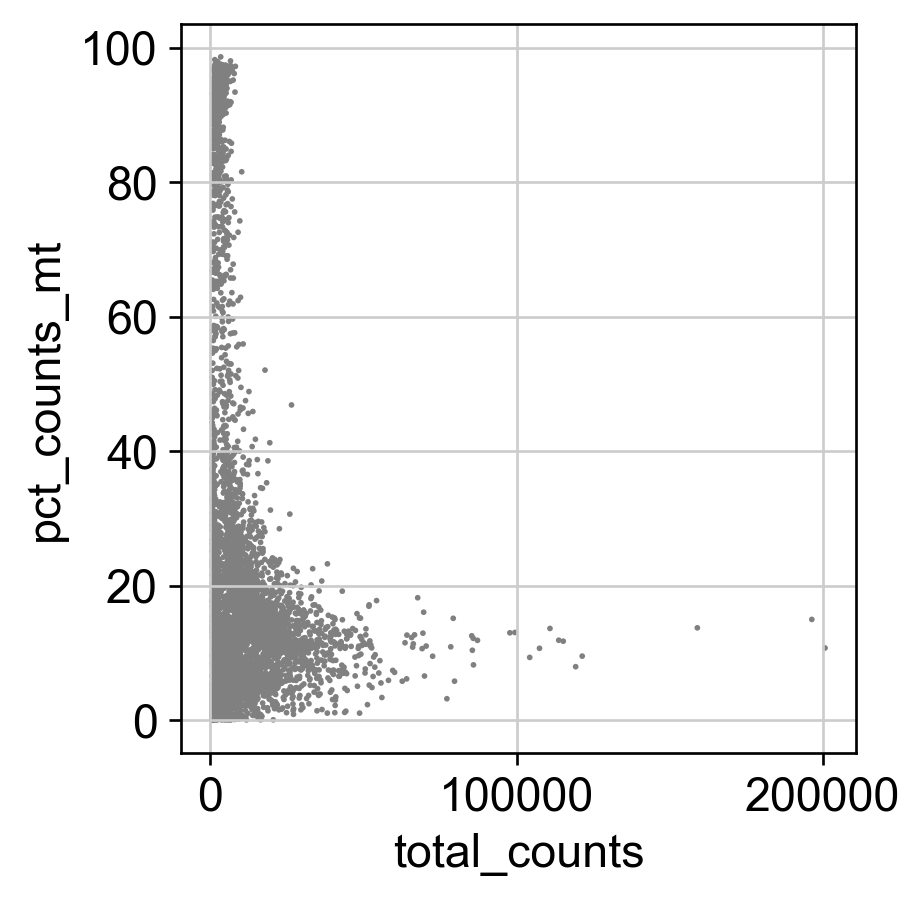

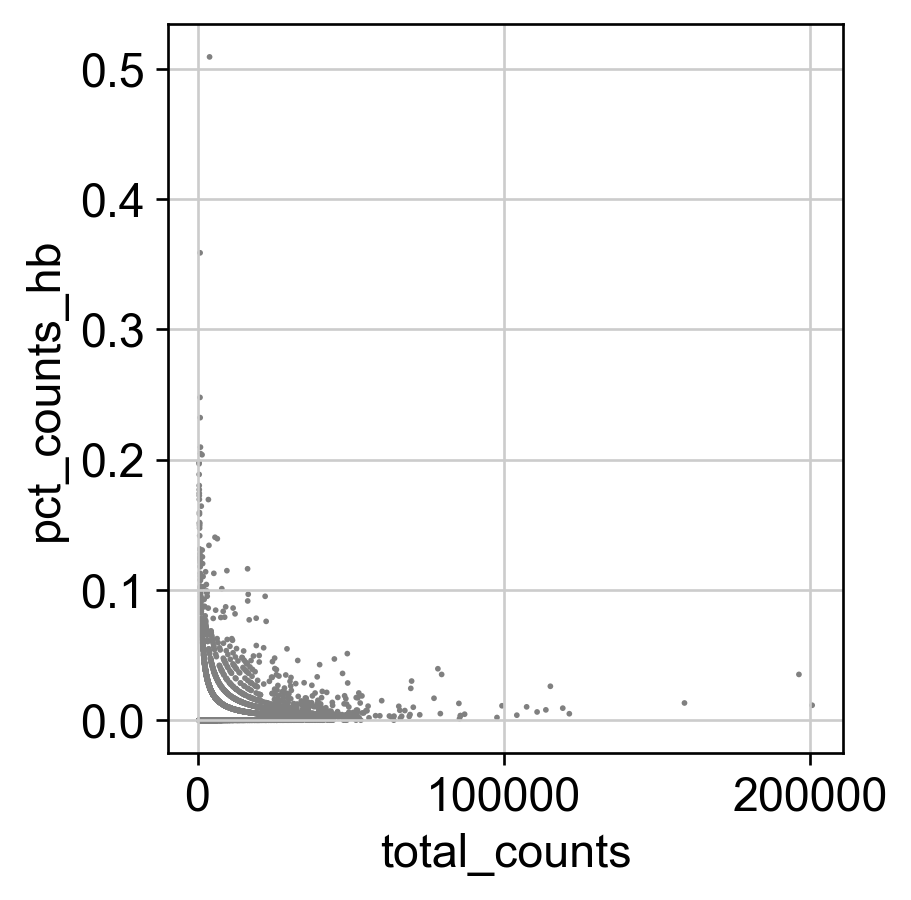

In [5]:
# QC inspection ---

# 3 types of unwanted cells to remove:
    # Empty droplets / debris -> almost no RNA
    # Dead or dying cells -> high mitochondrial RNA
    # Doublets (2 cells together) -> too much RNA

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

print(adata)
print(f"Counts look integer-like: {check_integer_like_counts(adata)}")

# Light gene filtering first (common, permissive)
sc.pp.filter_genes(adata, min_cells=3)

# Add QC metrics
add_standard_qc_metrics(adata)

# Suggested thresholds (starting point only)
qc_suggestions = suggest_qc_thresholds(adata, nmads=3)
display(pd.DataFrame.from_dict(qc_suggestions, orient="index", columns=["suggested_value"]))

# Inspect QC visually before deciding final thresholds
plot_qc(adata, sample_id)

In [6]:
# -------------------------------------------------------------------
# CHOOSE QC THRESHOLDS
# Adjust after inspecting the QC plots above.
# -------------------------------------------------------------------
QC = {
    "min_counts": 500,
    "min_genes": 200,
    "max_counts": None,
    "max_genes": None,
    "max_pct_mt": 20,
}

filtered out 3646 genes that are detected in less than 3 cells
Cells before QC: 10154
Cells after QC : 8331
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
HVG flavor used: seurat
Number of HVGs: 3000


/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_83711/3112665090.py:159: UserWarning: seurat_v3 HVG selection failed (ImportError: Please install skmisc package via `pip install --user scikit-misc). Falling back to flavor='seurat' on log1p data.
  warnings.warn(


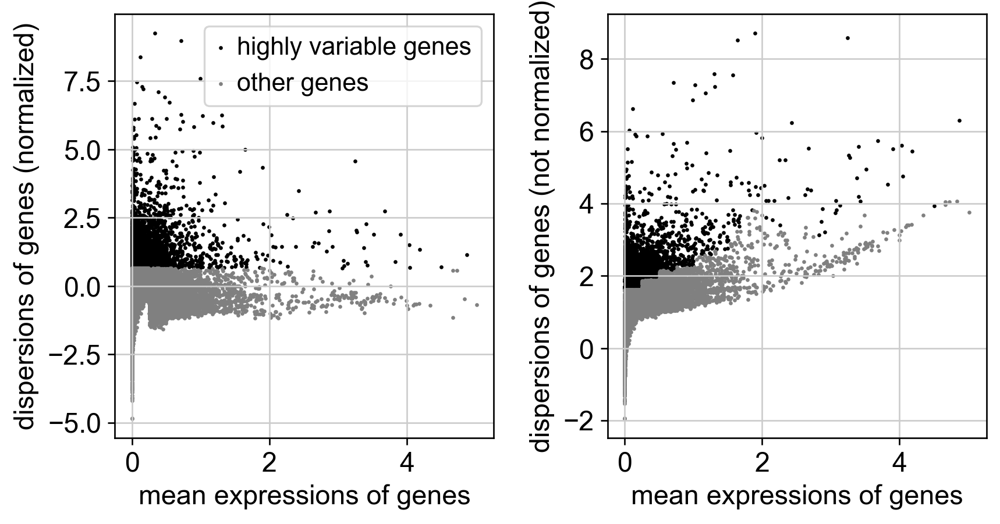

computing PCA
    with n_comps=50


$HOME/miniforge3/envs/process_slide/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


    finished (0:00:01)


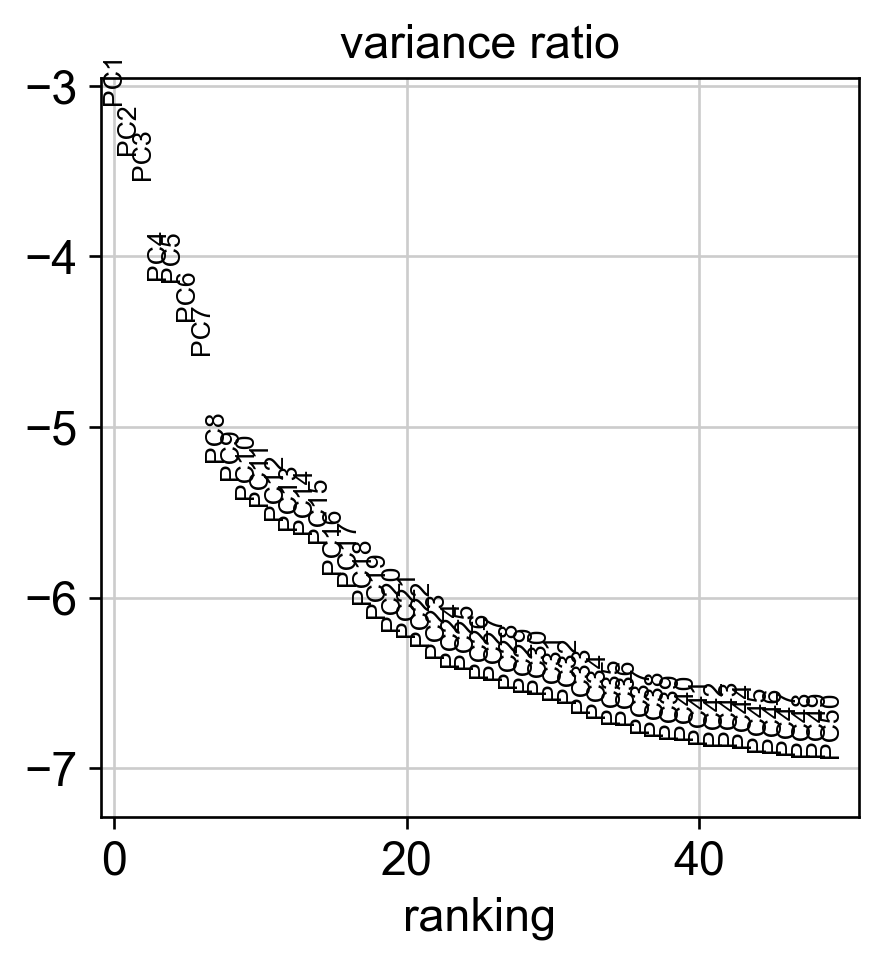

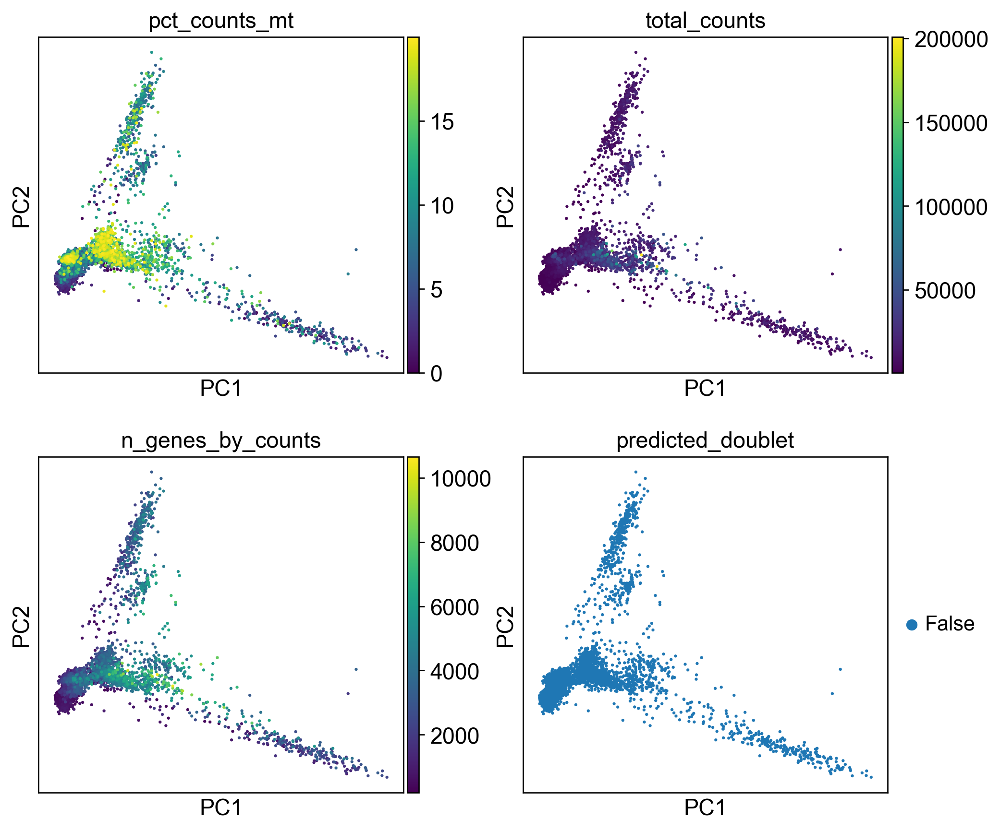

In [7]:
# Filtering + preprocessing ---

raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"

adata = sc.read_h5ad(raw_path)
adata.var_names_make_unique()

# Minimal gene filter first
sc.pp.filter_genes(adata, min_cells=3)

# QC metrics
add_standard_qc_metrics(adata)

RUN_SCRUBLET = False            # set True to enable doublet calling in this pass
REMOVE_PREDICTED_DOUBLETS = False

# Apply QC filters
n_before = adata.n_obs
adata = filter_cells_with_qc_dict(adata, QC)
n_after = adata.n_obs
print(f"Cells before QC: {n_before}")
print(f"Cells after QC : {n_after}")

# Optional doublet detection on raw counts, before normalization
if RUN_SCRUBLET:
    sc.pp.scrublet(adata, random_state=0)
    print(adata.obs["predicted_doublet"].value_counts(dropna=False))
    sc.pl.violin(adata, ["doublet_score"], jitter=0.4)
    sc.pl.umap(adata, color=["doublet_score", "predicted_doublet"]) if "X_umap" in adata.obsm else None

    if REMOVE_PREDICTED_DOUBLETS:
        adata = adata[~adata.obs["predicted_doublet"]].copy()
else:
    adata.obs["doublet_score"] = np.nan
    adata.obs["predicted_doublet"] = False

# Save raw counts in a layer before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize + log1p
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Save the full log-normalized matrix for marker plotting / DE
adata.raw = adata.copy()

# HVGs
N_TOP_HVGS = 3000
adata, hvg_flavor_used = run_hvg(adata, n_top_genes=N_TOP_HVGS)
sc.pl.highly_variable_genes(adata)

# Restrict to HVGs for PCA/clustering only
adata = adata[:, adata.var["highly_variable"]].copy()

# Scale, PCA
sc.pp.scale(adata, max_value=10)

MAX_PCS = 50
sc.tl.pca(adata, svd_solver="arpack", n_comps=MAX_PCS)

# PCA inspection
sc.pl.pca_variance_ratio(adata, n_pcs=MAX_PCS, log=True)
sc.pl.pca(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet"],
    ncols=2,
)

In [8]:
# -------------------------------------------------------------------
# CHOOSE AFTER INSPECTING PCA / UMAP
# -------------------------------------------------------------------
N_PCS_TO_USE = 50
N_NEIGHBORS = 15
RESOLUTIONS = [0.20, 0.40, 0.60, 0.80, 1.00]

computing neighbors
    using 'X_pca' with n_pcs = 50


$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:11)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:10)
* Running Leiden clustering at resolution 0.20...
running Leiden clustering
    finished: found 12 clusters and added
    'leiden_0.20', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.40...
running Leiden clustering
    finished: found 16 clusters and added
    'leiden_0.40', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.60...
running Leiden clustering
    finished: found 21 clusters and added
    'leiden_0.60', the cluster labels (adata.obs, categorical) (0:00:00)
* Running Leiden clustering at resolution 0.80...
running Leiden clustering
    finished: found 23 clusters and added
    'le

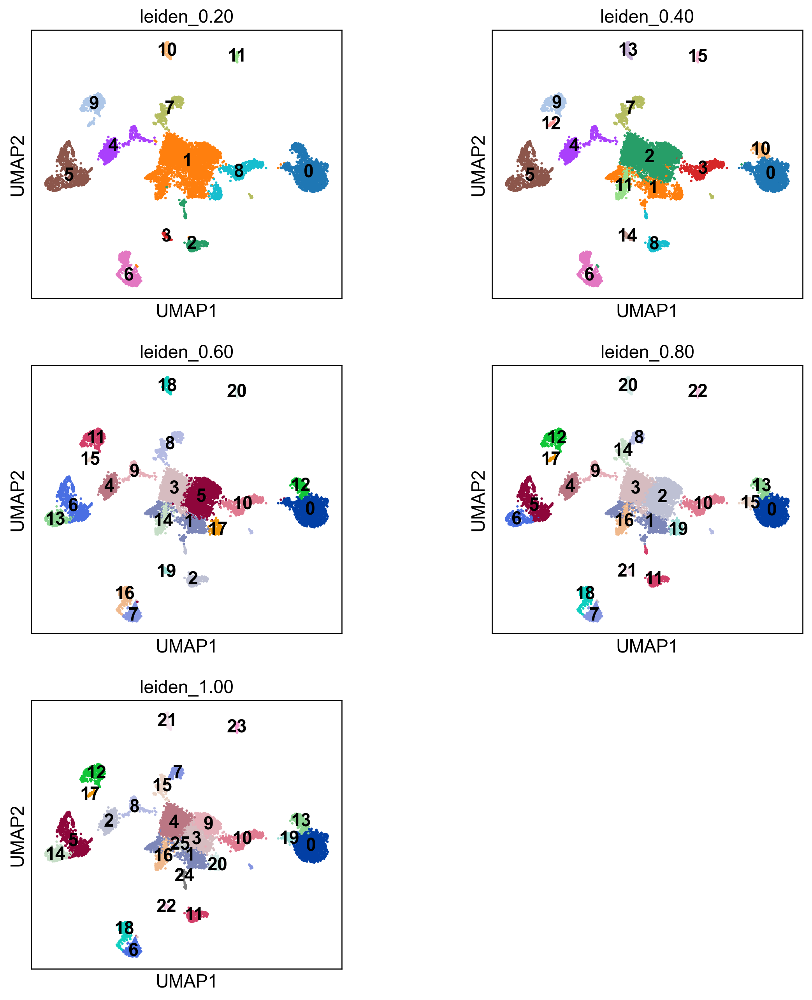

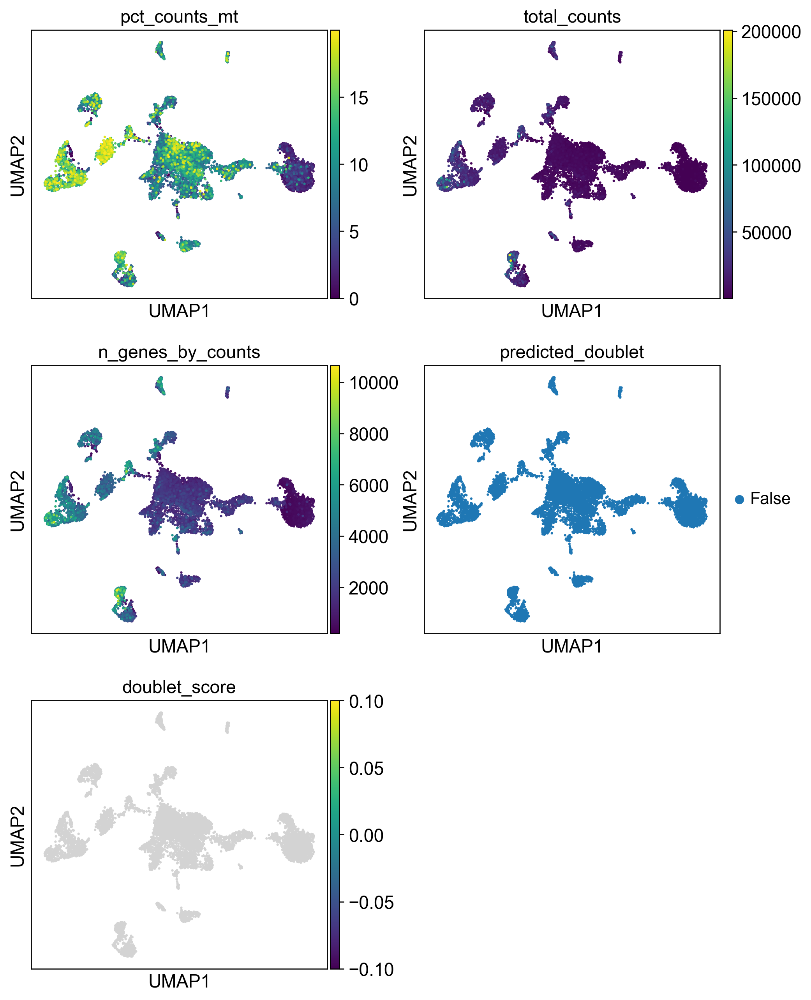

In [9]:
# Clustering + marker genes + save mapping ---

# Neighbors + UMAP
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS_TO_USE)
sc.tl.umap(adata, random_state=0)

# Several Leiden resolutions
for res in RESOLUTIONS:
    print(f"* Running Leiden clustering at resolution {res:.2f}...")
    key = f"leiden_{res:.2f}"
    sc.tl.leiden(
        adata,
        resolution=res,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
    )

cluster_keys = [f"leiden_{res:.2f}" for res in RESOLUTIONS]

# Visual inspection of clustering solutions
sc.pl.umap(
    adata,
    color=cluster_keys,
    legend_loc="on data",
    ncols=2,
    wspace=0.35,
)

# Also inspect QC variables on the chosen embedding
sc.pl.umap(
    adata,
    color=["pct_counts_mt", "total_counts", "n_genes_by_counts", "predicted_doublet", "doublet_score"],
    ncols=2,
)

In [10]:
# -------------------------------------------------------------------
# CHOOSE THE RESOLUTION YOU WANT TO KEEP
# -------------------------------------------------------------------
CLUSTER_KEY = "leiden_0.60"
TOP_N_MARKERS = 15

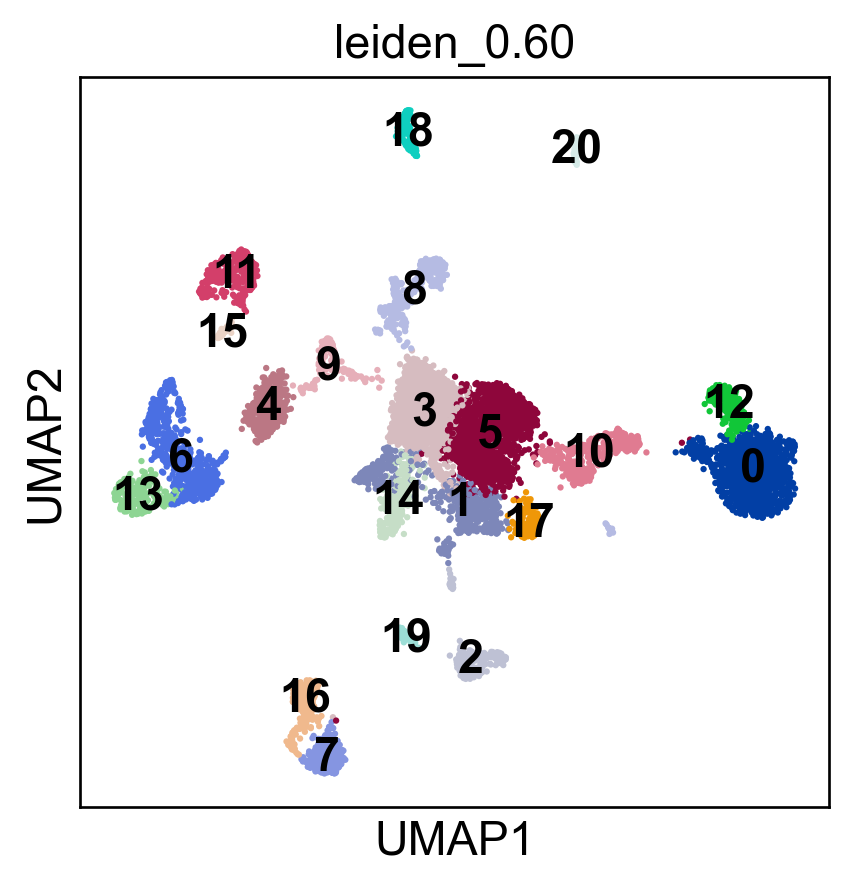

ranking genes
    finished: added to `.uns['rank_genes_groups__leiden_0.60']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:07)


$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:380: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/scanp

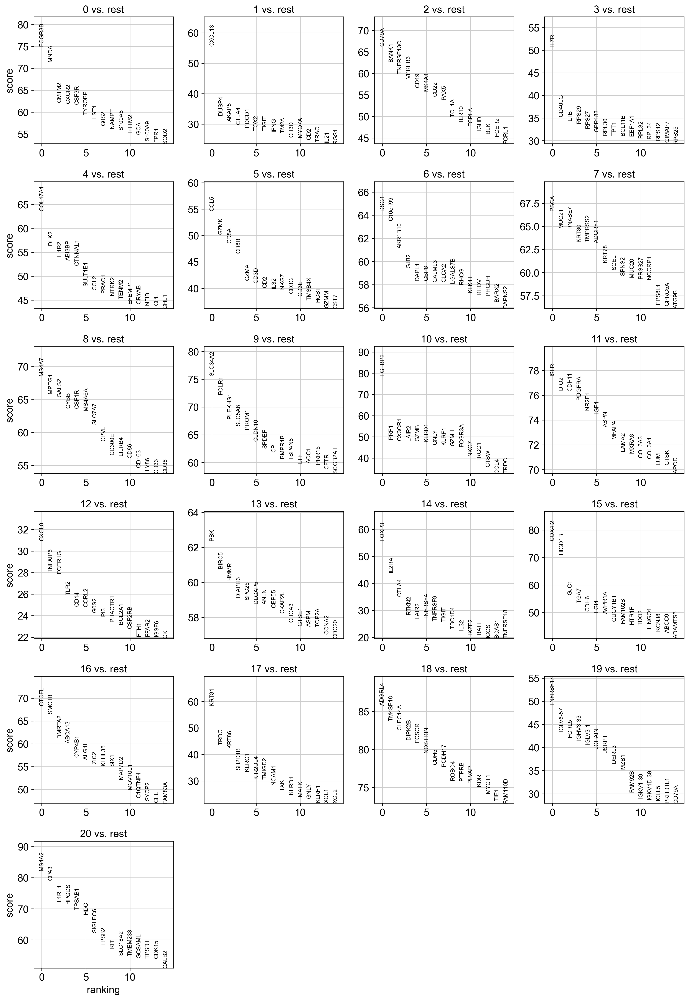

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_0.60']`






Top markers per cluster (wide table):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
rank_1,FCGR3B,CXCL13,CD79A,IL7R,COL17A1,CCL5,DSG1,PSCA,MS4A7,SLC34A2,FGFBP2,ISLR,CXCL8,PBK,FOXP3,COX4I2,CTCFL,KRT81,ADGRL4,TNFRSF17,MS4A2
rank_2,MNDA,DUSP4,BANK1,CD40LG,DLK2,GZMK,C10orf99,MUC21,MPEG1,FOLR1,PRF1,DIO2,TNFAIP6,BIRC5,IL2RA,HIGD1B,SMC1B,TRDC,TM4SF18,IGLV6-57,CPA3
rank_3,CMTM2,AKAP5,TNFRSF13C,LTB,IL1R2,CD8A,AKR1B10,RNASE7,LGALS2,PLEKHS1,CX3CR1,CDH11,FCER1G,HMMR,CTLA4,GJC1,DMRTA2,KRT86,CLEC14A,FCRL5,IL1RL1
rank_4,CXCR2,CTLA4,VPREB3,RPS29,ABI3BP,CD8B,GJB2,KRT80,CYBB,SLC5A8,LAIR2,PDGFRA,TLR2,DIAPH3,RTKN2,ITGA7,ABCA13,SH2D1B,DIPK2B,IGHV3-33,HPGDS
rank_5,CSF3R,PDCD1,CD19,RPS27,CTNNAL1,GZMA,DAPL1,TMPRSS2,CSF1R,PROM1,GZMB,NR2F1,CD14,SPC25,LAIR2,CDH6,CYP4B1,KLRC1,ECSCR,IGLV3-1,TPSAB1
rank_6,TYROBP,TOX2,MS4A1,GPR183,SULT1E1,CD3D,GBP6,ADGRF1,MS4A6A,CLDN10,KLRD1,IGF1,CCRL2,DLGAP5,TNFRSF4,LGI4,ALG1L,KIR2DL4,NOSTRIN,JCHAIN,HDC
rank_7,LST1,TIGIT,CD22,RPL30,CCL2,CD2,CALML3,KRT78,SLC7A7,SPDEF,GNLY,ASPN,G0S2,ANLN,TNFRSF9,AVPR1A,ZIC2,TMIGD2,CDH5,JSRP1,SIGLEC6
rank_8,G0S2,IFNG,PAX5,TPT1,PRAC1,IL32,CLCA2,SCEL,CPVL,CP,KLRF1,MFAP4,PI3,CEP55,TIGIT,GUCY1B1,KLHL35,NCAM1,PCDH17,DERL3,TPSB2
rank_9,NAMPT,ITM2A,TCL1A,BCL11B,NTRK2,NKG7,LGALS7B,SPNS2,CD300E,BMPR1B,GZMH,LAMA2,PHACTR1,CKAP2L,TBC1D4,FAM162B,SIX1,TXK,ROBO4,MZB1,KIT
rank_10,S100A8,CD3D,TLR10,EEF1A1,TENM2,CD3G,RHCG,MUC20,LILRB4,TSPAN8,FCGR3A,MXRA8,BCL2A1,CDCA3,IL32,HTR1F,MAP7D2,KLRD1,PTPRB,FAM92B,SLC18A2


In [11]:
# Differential expression / markers ---

# UMAP of chosen clustering
sc.pl.umap(
    adata,
    color=[CLUSTER_KEY],
    legend_loc="on data",
)

# Differential expression / markers
marker_key, markers_all, markers_filtered, top_markers_wide = run_marker_analysis(
    adata=adata,
    cluster_key=CLUSTER_KEY,
    top_n=TOP_N_MARKERS,
    min_logfc=0.25,
    max_adj_p=0.05,
    min_pct_group=0.10,
)

# Standard ranked marker plot
sc.pl.rank_genes_groups(
    adata,
    key=marker_key,
    n_genes=TOP_N_MARKERS,
    sharey=False,
)

# "Big plot": rows = clusters, columns = top marker genes
sc.pl.rank_genes_groups_matrixplot(
    adata,
    key=marker_key,
    groupby=CLUSTER_KEY,
    n_genes=TOP_N_MARKERS,
    use_raw=True,
    standard_scale="var",
    cmap="Blues",
)

# Convenient marker displays
print("\nTop markers per cluster (wide table):")
display(top_markers_wide)

# print("\nDetailed long-format marker table (top rows after filtering):")
# display(markers_filtered.groupby("cluster", sort=False).head(TOP_N_MARKERS))

# # Optional: save marker tables
# markers_all.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_all.tsv.gz", sep="\t", index=False)
# markers_filtered.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__markers_filtered.tsv.gz", sep="\t", index=False)
# top_markers_wide.to_csv(ref_folder_annot / f"{sample_id}__{CLUSTER_KEY}__top_markers_wide.tsv", sep="\t", index=True)

In [12]:
# -------------------------------------------------------------------
# FILL ANNOTATION MAPPING cluster -> cell type dict
# -------------------------------------------------------------------

# Fill with annotations
cluster_to_cell_type = {
    "0": "Neutrophils",
    "1": "Activated/exhausted T cells",
    "2": "B cells",
    "3": "CD4+ T cells",
    "4": "Epithelial cells (basal/squamous-like)",
    "5": "Cytotoxic T cells",
    "6": "Epithelial cells (differentiated squamous-like)",
    "7": "Epithelial tumor cells (glandular/secretory-like)",
    "8": "Macrophages/monocytes",
    "9": "Epithelial tumor cells (secretory-like)",
    "10": "NK cells",
    "11": "Fibroblasts / CAFs",
    "12": "Inflammatory myeloid cells",
    "13": "Cycling/proliferating cells",
    "14": "Regulatory T cells",
    "15": "Pericytes",
    "16": "Epithelial tumor cells",
    "17": "γδ T cells",
    "18": "Endothelial cells",
    "19": "Plasma cells",
    "20": "Mast cells",
}

In [13]:
# Apply annotation and save cell_id <-> cell_type mapping
mapping_df, mapping_path = apply_annotation_and_save_mapping(
    adata=adata,
    sample_id=sample_id,
    cluster_key=CLUSTER_KEY,
    cluster_to_cell_type=cluster_to_cell_type,
    output_dir=ref_folder_annot,
)

Saved mapping file:
/path/to/ALHENA_data/eval/eval_datasets/st_eval_data/scRNAseq_references_before/cervix/cervix_annots/GSM6360688_ADC_6__celltype_mapping.tsv.gz
                                                                 cell_id         sample_id leiden_0.60                               cell_type
GSM6360688_ADC_6_AAACCCAAGATAGCAT-1  GSM6360688_ADC_6_AAACCCAAGATAGCAT-1  GSM6360688_ADC_6           0                             Neutrophils
GSM6360688_ADC_6_AAACCCAAGTCATGGG-1  GSM6360688_ADC_6_AAACCCAAGTCATGGG-1  GSM6360688_ADC_6           1             Activated/exhausted T cells
GSM6360688_ADC_6_AAACCCAAGTCTGTAC-1  GSM6360688_ADC_6_AAACCCAAGTCTGTAC-1  GSM6360688_ADC_6           4  Epithelial cells (basal/squamous-like)
GSM6360688_ADC_6_AAACCCACAAGTGATA-1  GSM6360688_ADC_6_AAACCCACAAGTGATA-1  GSM6360688_ADC_6           4  Epithelial cells (basal/squamous-like)
GSM6360688_ADC_6_AAACCCACACACGGTC-1  GSM6360688_ADC_6_AAACCCACACACGGTC-1  GSM6360688_ADC_6           5                    

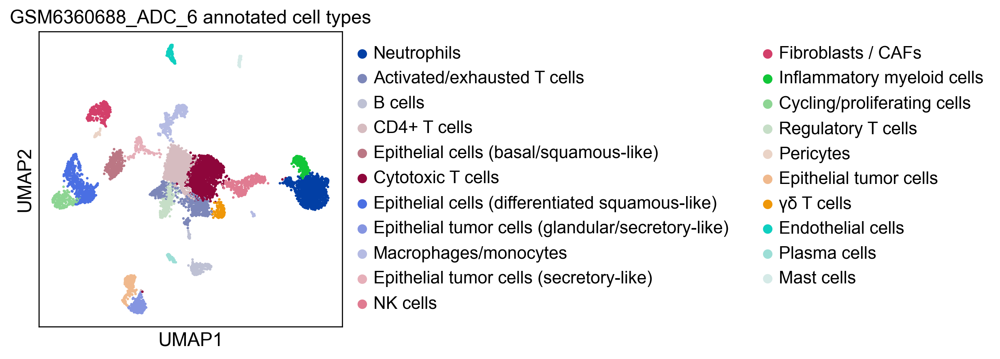

In [14]:
# Look at cell type on UMAP
sc.pl.umap(
    adata,
    color=["cell_type"],
    title=f"{sample_id} annotated cell types",
)

## Final concatened adata with all annotations and samples

In [4]:
import scanpy as sc
import anndata as ad
import pandas as pd

In [7]:
# Final merge: rebuild annotated full cervix reference ---

raw_paths = sorted(ref_folder_raw_h5ad.glob("*.h5ad"))
# Remove files with ._ prefix if present (e.g. from MacOS Finder)
raw_paths = [p for p in raw_paths if not p.name.startswith("._")]

sample_ids = [p.stem for p in raw_paths]

if len(sample_ids) == 0:
    raise ValueError(f"No raw h5ad files found in: {ref_folder_raw_h5ad}")

adata_dict = {}
reference_genes = None

for sample_id in sample_ids:
    raw_path = ref_folder_raw_h5ad / f"{sample_id}.h5ad"
    map_path = ref_folder_annot / f"{sample_id}__celltype_mapping.tsv.gz"

    if not map_path.exists():
        raise FileNotFoundError(f"Missing annotation mapping for sample {sample_id}:\n{map_path}")

    a = sc.read_h5ad(raw_path)
    a.var_names_make_unique()

    # Confirm same gene space across samples
    if reference_genes is None:
        reference_genes = a.var_names.copy()
    else:
        if not reference_genes.equals(a.var_names):
            raise ValueError(f"Gene space mismatch for sample {sample_id}")

    mapping = pd.read_csv(map_path, sep="\t")

    required_cols = {"cell_id", "cell_type"}
    if not required_cols.issubset(mapping.columns):
        raise ValueError(f"{map_path} must contain columns: {required_cols}")

    if mapping["cell_id"].duplicated().any():
        dup_ids = mapping.loc[mapping["cell_id"].duplicated(), "cell_id"].tolist()[:10]
        raise ValueError(f"Duplicated cell_id(s) in {map_path}, examples: {dup_ids}")

    mapping = mapping.set_index("cell_id")

    # Join annotation onto obs
    a.obs = a.obs.join(mapping, how="left")

    # Cells without a mapping are cells removed during QC / annotation
    missing_ct = a.obs["cell_type"].isna().sum()
    print(f"{sample_id}: {missing_ct} cells have no cell_type mapping and will be dropped.")

    # Keep only annotated cells (i.e. QC-passed cells)
    a = a[~a.obs["cell_type"].isna()].copy()

    if a.n_obs == 0:
        raise ValueError(f"{sample_id}: no annotated cells remain after filtering to mapped cells.")

    # Keep an explicit provenance column
    a.obs["source_sample_id"] = sample_id

    adata_dict[sample_id] = a

# Concatenate
cervix = ad.concat(
    adata_dict,
    axis=0,
    join="inner",          # all samples should share the same genes
    merge="same",
    label="concat_sample_id",
    index_unique=None,     # obs_names are already globally unique
)

# Nice dtypes
cervix.obs["cell_type"] = cervix.obs["cell_type"].astype("category")
cervix.obs["source_sample_id"] = cervix.obs["source_sample_id"].astype("category")
cervix.obs["concat_sample_id"] = cervix.obs["concat_sample_id"].astype("category")

print(cervix)
print(cervix.obs["cell_type"].value_counts(dropna=False).head(50))

final_path = ref_folder_final / "cervix.h5ad"
cervix.write_h5ad(final_path, compression="gzip")

print(f"Saved final reference:\n{final_path}")

GSM6360680_N_HPV_NEG_1: 789 cells have no cell_type mapping and will be dropped.
GSM6360681_N_HPV_NEG_2: 635 cells have no cell_type mapping and will be dropped.
GSM6360682_N_1: 908 cells have no cell_type mapping and will be dropped.
GSM6360683_N_2: 755 cells have no cell_type mapping and will be dropped.
GSM6360684_HSIL_1: 377 cells have no cell_type mapping and will be dropped.
GSM6360685_HSIL_2: 389 cells have no cell_type mapping and will be dropped.
GSM6360686_SCC_4: 226 cells have no cell_type mapping and will be dropped.
GSM6360687_SCC_5: 539 cells have no cell_type mapping and will be dropped.
GSM6360688_ADC_6: 1823 cells have no cell_type mapping and will be dropped.
AnnData object with n_obs × n_vars = 77518 × 20615
    obs: 'gsm', 'sample', 'group', 'stage', 'replicate', 'histology', 'dataset', 'tissue', 'species', 'sample_id', 'cell_type', 'source_sample_id', 'concat_sample_id'
    var: 'gene_ids', 'feature_types'
cell_type
Neutrophils                                      